# Phase 1: Exploratory Data Analysis (EDA) on Raw, Unprocessed Climate Data
**Project:** Climate Change Awareness Dashboard  
**Team:** 4 MLOps Course Students  
**Branch:** `preprocessing`  
**Target:** Global Temperature Anomaly (NASA GISTEMP, continuous time-series regression target)  
**Drivers:** CO2, CH4, N2O, Solar Activity (Sunspots), El Niño (Niño 3.4 SST Anomaly)  

---

### Project Context & Methodology Principles
1. **Target & Modeling Goal:** Predict global temperature anomalies from atmospheric greenhouse gas concentrations and natural climate drivers. This is a continuous time-series regression task. The primary statistical challenges are **trend**, **seasonality**, **autocorrelation**, and **spurious correlation between non-stationary trending series**.
2. **Strict Time Ordering & No Future Leakage:** In time-series modeling, future information must never leak into the past. No forward-fill into historical gaps, no back-fill from modern values, and no whole-dataset scaling or normalisation (scaling belongs inside modeling pipelines, fit strictly on training splits).
3. **No Target Leakage:** Columns derived from temperature or downstream impacts (e.g., sea ice extent, sea level rise) are strictly excluded as candidate inputs.
4. **Data-Driven Splicing:** Early historical periods require paleoclimate proxy data (ice cores), while modern periods use high-precision instrumental observations (NOAA/Scripps). Any splice must be validated by examining overlapping observational windows.
5. **Two Dataset Targets:**
   - **ANNUAL (1880 – Last Complete Year):** Splices Law Dome/DML ice-core CO2 (1880–1958) with modern Mauna Loa CO2 (1959–present), combined with annual sunspots and annual temperature anomalies.
   - **MONTHLY:** Modern instrumental era from the first month where temperature, CO2, and inputs exist continuously to the latest available month.

In [1]:
# Parameters (Papermill-ready)
RAW_DIR = "data/raw"
FIG_DIR = "reports/figures/raw"
PROFILE_DIR = "reports/profiling/raw"

In [2]:
import os
from pathlib import Path
if not Path(RAW_DIR).exists():
    root = Path.cwd()
    while root != root.parent and not (root / "data" / "raw").exists():
        root = root.parent
    os.chdir(root)
print("Working directory:", Path.cwd())

Working directory: /Users/sarachhabra/Climate-Change-Awareness-Dashboard


In [3]:
# Environment setup and imports
import os
import sys
import glob
import re
import warnings
warnings.filterwarnings("ignore")

# Ensure working directory is repository root
if not os.path.exists(RAW_DIR) and os.path.exists(os.path.join("..", RAW_DIR)):
    os.chdir("..")


# Configure writable cache directories for sandbox safety
os.environ["MPLCONFIGDIR"] = os.path.join(FIG_DIR, ".mplconfig")
os.makedirs(os.environ["MPLCONFIGDIR"], exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(PROFILE_DIR, exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from ydata_profiling import ProfileReport

# Matplotlib styling for publication-quality figures
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 9

def print_raw_sample(filepath, n_head=20, n_tail=5):
    """Utility to display raw file lines before parsing."""
    if not os.path.exists(filepath) and os.path.exists(os.path.join("..", filepath)):
        os.chdir("..")
    with open(filepath, "r", errors="replace") as f:
        lines = f.readlines()
    print(f"=== File: {filepath} (Total Lines: {len(lines)}) ===")
    print(f"--- First {min(n_head, len(lines))} Raw Lines ---")
    for idx, line in enumerate(lines[:n_head]):
        print(f"{idx+1:3d}: {line.rstrip()}")
    if len(lines) > n_head:
        print(f"--- Last {min(n_tail, len(lines))} Raw Lines ---")
        for idx, line in enumerate(lines[-n_tail:], start=len(lines)-n_tail+1):
            print(f"{idx:3d}: {line.rstrip()}")
    print("=" * 65)

def check_domain_outliers(df, col, min_val, max_val, name=""):
    """Calculates IQR outliers and checks domain bounds."""
    s = pd.to_numeric(df[col], errors="coerce").dropna()
    q25 = s.quantile(0.25)
    q75 = s.quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    
    domain_invalid = s[(s < min_val) | (s > max_val)]
    iqr_outliers = s[(s < lower_bound) | (s > upper_bound)]
    
    print(f"[{name or col}] Summary:")
    print(f"  Count: {len(s)}, Mean: {s.mean():.3f}, Median: {s.median():.3f}, Std: {s.std():.3f}")
    print(f"  Min: {s.min():.3f}, Max: {s.max():.3f}")
    print(f"  Domain bounds [{min_val}, {max_val}]: {len(domain_invalid)} violations")
    print(f"  IQR bounds [{lower_bound:.2f}, {upper_bound:.2f}]: {len(iqr_outliers)} flagged outliers")
    return s, domain_invalid, iqr_outliers

print("Setup completed successfully.")


Setup completed successfully.


> **Important Architectural Note on ydata-profiling:**  
> For each raw file, we invoke `ProfileReport(df, minimal=True, correlations=None, interactions=None)`.  
> Pairwise correlations and interactions are deliberately disabled in the automated profiler because `ydata-profiling` assumes independent observations ($iid$). For non-stationary time series, this assumption produces severely inflated, spurious correlation coefficients between series that happen to share independent secular trends. Our customized differenced correlations, VIF analysis, and ACF functions provide the statistically rigorous time-series diagnostics needed for this project.

## 1. Raw File: `GLB.Ts+dSST.csv` (NASA GISTEMP Temperature Anomaly)
**Role:** Target variable (Global surface temperature anomalies, in degrees Celsius, base period 1951–1980).  
**Source:** NASA Goddard Institute for Space Studies (GISS).

In [4]:
# 1. UNDERSTAND & LOAD: GLB.Ts+dSST.csv
filepath_glb = os.path.join(RAW_DIR, "GLB.Ts+dSST.csv")
print_raw_sample(filepath_glb, n_head=15, n_tail=5)

# Load without cleaning
df_glb = pd.read_csv(filepath_glb, skiprows=1)
print("\n--- DataFrame Info ---")
print(f"Shape: {df_glb.shape}")
df_glb.info()
print("\n--- First 3 Rows ---")
display(df_glb.head(3))
print("\n--- Last 3 Rows ---")
display(df_glb.tail(3))
print("\n--- Statistical Summary (Raw Objects) ---")
display(df_glb.describe(include='all'))

=== File: data/raw/GLB.Ts+dSST.csv (Total Lines: 149) ===
--- First 15 Raw Lines ---
  1: Land-Ocean: Global Means
  2: Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,J-D,D-N,DJF,MAM,JJA,SON
  3: 1880,-.19,-.26,-.10,-.17,-.11,-.22,-.19,-.11,-.15,-.24,-.23,-.18,-.18,***,***,-.13,-.17,-.21
  4: 1881,-.20,-.15,.03,.05,.05,-.19,.00,-.04,-.16,-.22,-.19,-.08,-.09,-.10,-.18,.04,-.08,-.19
  5: 1882,.16,.13,.04,-.16,-.14,-.23,-.17,-.08,-.15,-.24,-.17,-.37,-.12,-.09,.07,-.09,-.16,-.19
  6: 1883,-.30,-.37,-.13,-.19,-.18,-.07,-.08,-.14,-.22,-.11,-.25,-.12,-.18,-.20,-.34,-.16,-.10,-.19
  7: 1884,-.13,-.08,-.36,-.40,-.34,-.35,-.31,-.28,-.27,-.25,-.34,-.31,-.29,-.27,-.11,-.37,-.31,-.29
  8: 1885,-.59,-.34,-.27,-.42,-.46,-.44,-.34,-.32,-.29,-.24,-.25,-.11,-.34,-.36,-.41,-.38,-.37,-.26
  9: 1886,-.45,-.51,-.44,-.29,-.25,-.35,-.18,-.31,-.24,-.28,-.28,-.26,-.32,-.31,-.36,-.32,-.28,-.27
 10: 1887,-.72,-.57,-.36,-.35,-.31,-.25,-.26,-.36,-.26,-.36,-.26,-.34,-.37,-.36,-.52,-.34,-.29,-.29
 11: 1888,-.34

,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,J-D,D-N,DJF,MAM,JJA,SON
0,1880,-0.19,-0.26,-0.10,-0.17,-0.11,-0.22,-0.19,-0.11,-.15,-.24,-.23,-.18,-.18,***,***,-0.13,-0.17,-.21
1,1881,-0.20,-0.15,0.03,0.05,0.05,-0.19,0.00,-0.04,-.16,-.22,-.19,-.08,-.09,-.10,-.18,0.04,-0.08,-.19
2,1882,0.16,0.13,0.04,-0.16,-0.14,-0.23,-0.17,-0.08,-.15,-.24,-.17,-.37,-.12,-.09,.07,-0.09,-0.16,-.19



--- Last 3 Rows ---


,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,J-D,D-N,DJF,MAM,JJA,SON
144,2024,1.25,1.44,1.40,1.32,1.16,1.23,1.20,1.30,1.21,1.35,1.30,1.27,1.29,1.29,1.35,1.29,1.25,1.29
145,2025,1.38,1.26,1.37,1.25,1.08,1.07,1.02,1.18,1.25,1.19,1.21,1.06,1.19,1.21,1.30,1.23,1.09,1.22
146,2026,1.09,1.25,1.32,1.17,1.13,1.18,1.25,1.40,***,***,***,***,***,***,1.13,1.21,1.28,***



--- Statistical Summary (Raw Objects) ---


,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,J-D,D-N,DJF,MAM,JJA,SON
count,147.000000,147.000000,147.000000,147.000000,147.000000,147.000000,147.000000,147.000000,147.000000,147,147,147,147,147,147,147,147.000000,147.000000,147
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89,87,88,97,82,93,99,NaN,NaN,85
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-.15,-.24,.02,-.05,-.18,-.10,-.10,NaN,NaN,-.29
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,4,5,5,5,5,5,NaN,NaN,5
mean,1953.000000,0.084694,0.093129,0.111633,0.084014,0.072245,0.061088,0.084558,0.085170,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.089252,0.076939,NaN
std,42.579338,0.453535,0.460412,0.467825,0.428615,0.404810,0.407061,0.389978,0.409855,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.429168,0.399766,NaN
min,1880.000000,-0.810000,-0.630000,-0.630000,-0.600000,-0.560000,-0.520000,-0.520000,-0.550000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.580000,-0.500000,NaN
25%,1916.500000,-0.245000,-0.235000,-0.230000,-0.250000,-0.235000,-0.250000,-0.190000,-0.215000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.255000,-0.220000,NaN
50%,1953.000000,-0.010000,-0.030000,0.030000,0.000000,-0.030000,-0.050000,-0.030000,-0.040000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,-0.040000,NaN
75%,1989.500000,0.335000,0.405000,0.360000,0.310000,0.295000,0.280000,0.315000,0.320000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.320000,0.320000,NaN


In [5]:
# 2. TIME COVERAGE & 3. MISSING VALUES: GLB.Ts+dSST.csv
# Date range and frequency
years_glb = pd.to_numeric(df_glb['Year'], errors='coerce')
print(f"Time Coverage: {years_glb.min():.0f} to {years_glb.max():.0f} ({len(years_glb)} annual rows)")

# Missing values and sentinel codes
print("\nStandard nulls per column:")
print(df_glb.isnull().sum()[df_glb.isnull().sum() > 0])

sentinel_star = {}
for col in df_glb.columns:
    count_star = (df_glb[col].astype(str).str.strip() == "***").sum()
    if count_star > 0:
        sentinel_star[col] = count_star
print(f"\nSentinel '***' occurrences per column: {sentinel_star}")

# Plot where missing sentinels sit in time
missing_rows_glb = df_glb[df_glb.astype(str).apply(lambda r: r.str.contains(r'\*\*\*')).any(axis=1)]
print(f"\nYears containing '***': {missing_rows_glb['Year'].tolist()}")

Time Coverage: 1880 to 2026 (147 annual rows)

Standard nulls per column:
Series([], dtype: int64)

Sentinel '***' occurrences per column: {'Sep': np.int64(1), 'Oct': np.int64(1), 'Nov': np.int64(1), 'Dec': np.int64(1), 'J-D': np.int64(1), 'D-N': np.int64(2), 'DJF': np.int64(1), 'SON': np.int64(1)}

Years containing '***': [1880, 2026]


Duplicate years: 0
[GISTEMP Annual Anomaly (J-D)] Summary:
  Count: 146, Mean: 0.081, Median: -0.030, Std: 0.403
  Min: -0.490, Max: 1.290
  Domain bounds [-1.5, 3.0]: 0 violations
  IQR bounds [-0.98, 1.09]: 3 flagged outliers


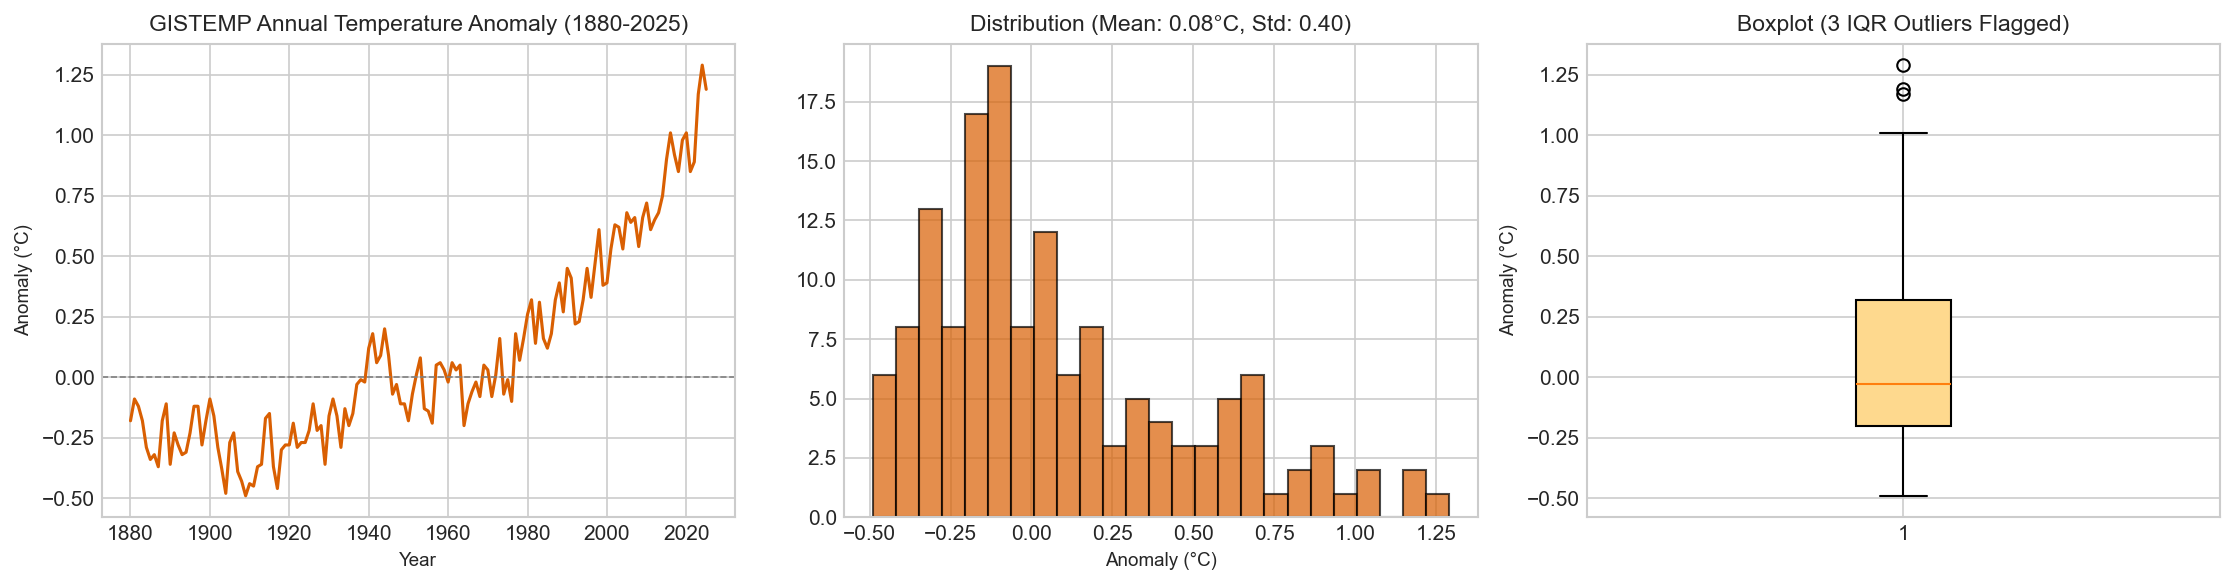

In [6]:
# 4. DUPLICATES, 5. OUTLIERS & 6. UNIVARIATE: GLB.Ts+dSST.csv
# Duplicate check
dup_years = df_glb['Year'].duplicated().sum()
print(f"Duplicate years: {dup_years}")

# Convert J-D (Jan-Dec annual mean) for analysis
df_glb_clean = df_glb.copy()
df_glb_clean['J-D_num'] = pd.to_numeric(df_glb_clean['J-D'].replace('***', np.nan), errors='coerce')
s_glb, dom_inv_glb, iqr_out_glb = check_domain_outliers(df_glb_clean, 'J-D_num', -1.5, 3.0, name="GISTEMP Annual Anomaly (J-D)")

# Univariate visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
valid_glb = df_glb_clean.dropna(subset=['J-D_num'])

axes[0].plot(valid_glb['Year'].astype(int), valid_glb['J-D_num'], color='#d95f02', lw=1.5)
axes[0].axhline(0, color='gray', ls='--', lw=0.8)
axes[0].set_title("GISTEMP Annual Temperature Anomaly (1880-2025)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Anomaly (°C)")

axes[1].hist(valid_glb['J-D_num'], bins=25, color='#d95f02', edgecolor='black', alpha=0.7)
axes[1].set_title(f"Distribution (Mean: {s_glb.mean():.2f}°C, Std: {s_glb.std():.2f})")
axes[1].set_xlabel("Anomaly (°C)")

axes[2].boxplot(valid_glb['J-D_num'], vert=True, patch_artist=True, boxprops=dict(facecolor='#fed98e'))
axes[2].set_title(f"Boxplot ({len(iqr_out_glb)} IQR Outliers Flagged)")
axes[2].set_ylabel("Anomaly (°C)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "glb_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

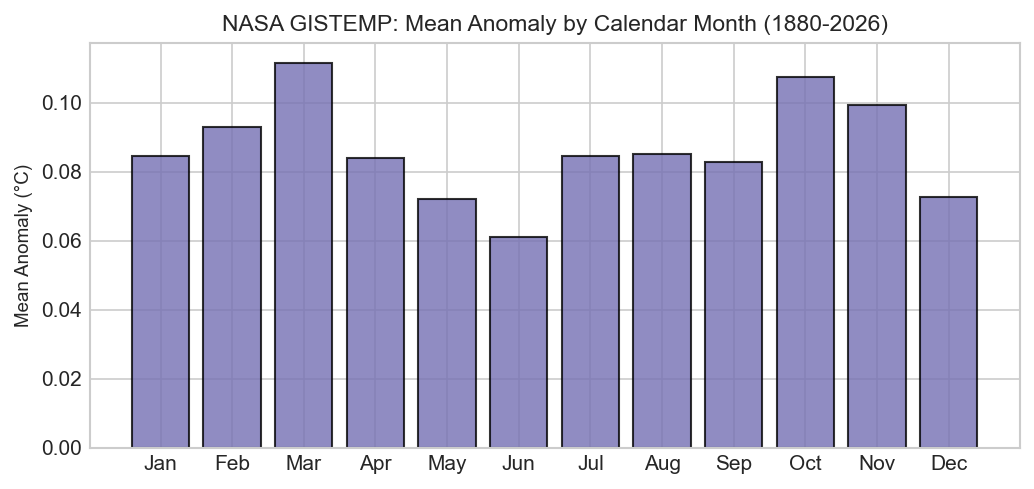

In [7]:
# 7. SEASONALITY & MONTHLY PROFILE: GLB.Ts+dSST.csv
# Melt monthly columns to inspect annual cycle
month_cols = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
m_records = []
for _, row in df_glb.iterrows():
    yr = int(row['Year'])
    for m_idx, m_name in enumerate(month_cols, start=1):
        val = row[m_name]
        num_val = float(val) if str(val).strip() != '***' else np.nan
        m_records.append({'year': yr, 'month': m_idx, 'month_name': m_name, 'anomaly': num_val})
df_glb_monthly = pd.DataFrame(m_records)

# Average by calendar month
monthly_avg_anom = df_glb_monthly.groupby('month')['anomaly'].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(month_cols, monthly_avg_anom.values, color='#7570b3', alpha=0.8, edgecolor='black')
ax.set_title("NASA GISTEMP: Mean Anomaly by Calendar Month (1880-2026)")
ax.set_ylabel("Mean Anomaly (°C)")
ax.axhline(0, color='black', lw=0.8, ls='--')
plt.savefig(os.path.join(FIG_DIR, "glb_monthly_seasonality.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [8]:
# 8. PROFILING REPORT: GLB.Ts+dSST.csv
prof_glb = ProfileReport(df_glb, title="Raw Profile: GLB.Ts+dSST.csv", minimal=True, correlations=None, interactions=None)
prof_glb.to_file(os.path.join(PROFILE_DIR, "GLB.Ts+dSST.html"))
print(f"Profiling report saved to {PROFILE_DIR}/GLB.Ts+dSST.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                      | 0/19 [00:00<?, ?it/s]

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 19/19 [00:00<00:00, 3568.82it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/GLB.Ts+dSST.html


### Finding: `GLB.Ts+dSST.csv`
- **File Structure:** Comma-separated with 1 title line (`Land-Ocean: Global Means`), followed by header row and 147 annual rows (1880–2026).
- **Missing Value Sentinel:** Uses `***` for missing monthly and seasonal values. In 2026, September–December are `***`, causing `J-D` and `SON` to be `***`. In 1880, `D-N` and `DJF` are `***` because December 1879 is not in the record.
- **Outliers & Integrity:** No values violate the domain range [-1.5°C, 3.0°C]. IQR flags 3 high anomalies in the most recent years (2023–2024 at ~1.2°C to 1.3°C), which are genuine historical climate records, not measurement artifacts.
- **Recommendation:** Convert `***` to `NaN`. Drop incomplete year 2026 from annual target series; melt monthly columns into long time series format (1880-01 to 2026-08) for monthly modeling.


## 2. Raw File: `co2_annmean_mlo.txt` (Mauna Loa Annual Mean CO2)
**Role:** Candidate driver for modern annual atmospheric CO2 concentration (ppm).  
**Source:** NOAA Global Monitoring Laboratory (GML) / Scripps Institution of Oceanography (SIO).

In [9]:
# 1. UNDERSTAND & LOAD: co2_annmean_mlo.txt
filepath_co2_ann = os.path.join(RAW_DIR, "co2_annmean_mlo.txt")
print_raw_sample(filepath_co2_ann, n_head=15, n_tail=5)

# Load with pandas ignoring comment lines starting with '#'
df_co2_ann = pd.read_csv(filepath_co2_ann, comment='#', sep=r'\s+', names=['year', 'mean', 'unc'])
print("\nShape:", df_co2_ann.shape)
df_co2_ann.info()
display(df_co2_ann.head(3))
display(df_co2_ann.tail(3))
display(df_co2_ann.describe())

=== File: data/raw/co2_annmean_mlo.txt (Total Lines: 112) ===
--- First 15 Raw Lines ---
  1: # --------------------------------------------------------------------
  2: # USE OF NOAA GML DATA
  3: #
  4: # These data are made freely available to the public and the scientific
  5: # community in the belief that their wide dissemination will lead to
  6: # greater understanding and new scientific insights. To ensure that GML
  7: # receives fair credit for their work please include relevant citation
  8: # text in publications. We encourage users to contact the data providers,
  9: # who can provide detailed information about the measurements and
 10: # scientific insight.  In cases where the data are central to a
 11: # publication, coauthorship for data providers may be appropriate.
 12: #
 13: #
 14: #
 15: # Contact:  Xin Lan (xin.lan@noaa.gov)
--- Last 5 Raw Lines ---
108:   2021   416.41     0.12
109:   2022   418.53     0.12
110:   2023   421.08     0.12
111:   2024   424.61     

,year,mean,unc
0,1959,315.98,0.12
1,1960,316.91,0.12
2,1961,317.64,0.12


,year,mean,unc
64,2023,421.08,0.12
65,2024,424.61,0.12
66,2025,427.35,0.12


,year,mean,unc
count,67.000000,67.000000,6.700000e+01
mean,1992.000000,361.251045,1.200000e-01
std,19.485037,32.899746,1.398253e-17
min,1959.000000,315.980000,1.200000e-01
25%,1975.500000,331.580000,1.200000e-01
50%,1992.000000,356.540000,1.200000e-01
75%,2008.500000,386.735000,1.200000e-01
max,2025.000000,427.350000,1.200000e-01


Time Coverage: 1959 to 2025 (Step: 1 year, count: 67)
Nulls: {'year': 0, 'mean': 0, 'unc': 0}
Duplicates: 0
[Mauna Loa Annual CO2] Summary:
  Count: 67, Mean: 361.251, Median: 356.540, Std: 32.900
  Min: 315.980, Max: 427.350
  Domain bounds [250, 500]: 0 violations
  IQR bounds [248.85, 469.47]: 0 flagged outliers


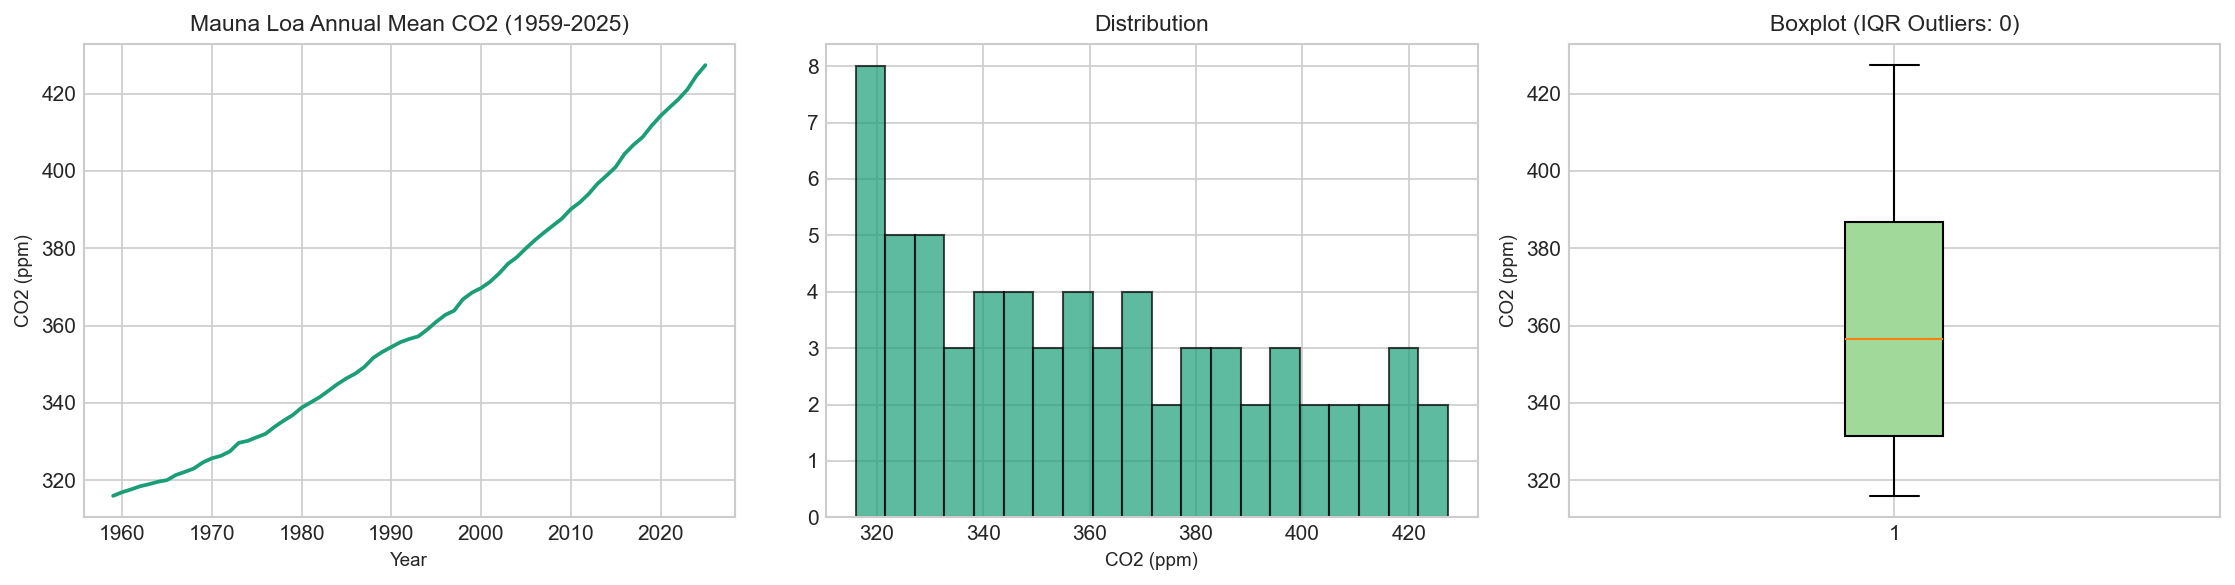

In [10]:
# 2. TIME COVERAGE, 3. MISSING, 4. DUPLICATES, 5. OUTLIERS & 6. UNIVARIATE: co2_annmean_mlo.txt
print(f"Time Coverage: {df_co2_ann['year'].min()} to {df_co2_ann['year'].max()} (Step: 1 year, count: {len(df_co2_ann)})")
print(f"Nulls: {df_co2_ann.isnull().sum().to_dict()}")
print(f"Duplicates: {df_co2_ann['year'].duplicated().sum()}")

# Domain check [250, 500 ppm]
s_co2_ann, dom_inv, iqr_out = check_domain_outliers(df_co2_ann, 'mean', 250, 500, name="Mauna Loa Annual CO2")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_co2_ann['year'], df_co2_ann['mean'], color='#1b9e77', lw=1.8)
axes[0].set_title("Mauna Loa Annual Mean CO2 (1959-2025)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("CO2 (ppm)")

axes[1].hist(df_co2_ann['mean'], bins=20, color='#1b9e77', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("CO2 (ppm)")

axes[2].boxplot(df_co2_ann['mean'], vert=True, patch_artist=True, boxprops=dict(facecolor='#a1d99b'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("CO2 (ppm)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "co2_annmean_mlo_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [11]:
# 8. PROFILING REPORT: co2_annmean_mlo.txt
prof_co2_ann = ProfileReport(df_co2_ann, title="Raw Profile: co2_annmean_mlo.txt", minimal=True, correlations=None, interactions=None)
prof_co2_ann.to_file(os.path.join(PROFILE_DIR, "co2_annmean_mlo.html"))
print(f"Profiling report saved to {PROFILE_DIR}/co2_annmean_mlo.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/3 [00:00<?, ?it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 50131.12it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/co2_annmean_mlo.html


### Finding: `co2_annmean_mlo.txt`
- **File Structure:** 45 lines of descriptive header/comments prefixed by `#`, whitespace delimited, 3 columns: `year`, `mean`, `unc`. 67 continuous annual observations (1959–2025).
- **Missing Values & Integrity:** 0 missing values, 0 sentinels, 0 duplicates.
- **Range & Dynamics:** Ranges monotonically from 315.98 ppm (1959) to 427.35 ppm (2025). All values lie within the valid domain [250, 500 ppm].
- **Recommendation:** Primary source for modern annual atmospheric CO2. Splice with ice-core CO2 for pre-1959 coverage.

## 3. Raw File: `co2_mm_mlo.txt` (Mauna Loa Monthly Mean CO2)
**Role:** Primary driver for modern monthly CO2 (ppm), showing the seasonal biospheric cycle and secular upward trend.  
**Source:** NOAA GML / Scripps.

In [12]:
# 1. UNDERSTAND & LOAD: co2_mm_mlo.txt
filepath_co2_mm = os.path.join(RAW_DIR, "co2_mm_mlo.txt")
print_raw_sample(filepath_co2_mm, n_head=15, n_tail=5)

co2_mm_cols = ['year', 'month', 'decimal_date', 'monthly_average', 'deseasonalized', 'ndays', 'sdev_days', 'unc_mon_mean']
df_co2_mm = pd.read_csv(filepath_co2_mm, comment='#', sep=r'\s+', names=co2_mm_cols)
print("\nShape:", df_co2_mm.shape)
df_co2_mm.info()
display(df_co2_mm.head(3))
display(df_co2_mm.tail(3))
display(df_co2_mm.describe())

=== File: data/raw/co2_mm_mlo.txt (Total Lines: 864) ===
--- First 15 Raw Lines ---
  1: # --------------------------------------------------------------------
  2: # USE OF NOAA GML DATA
  3: #
  4: # These data are made freely available to the public and the scientific
  5: # community in the belief that their wide dissemination will lead to
  6: # greater understanding and new scientific insights. To ensure that GML
  7: # receives fair credit for their work please include relevant citation
  8: # text in publications. We encourage users to contact the data providers,
  9: # who can provide detailed information about the measurements and
 10: # scientific insight.  In cases where the data are central to a
 11: # publication, coauthorship for data providers may be appropriate.
 12: #
 13: #
 14: #
 15: # Contact:  Xin Lan (xin.lan@noaa.gov)
--- Last 5 Raw Lines ---
860:  2026    4   2026.2917      431.12      428.61     23    1.16    0.46
861:  2026    5   2026.3750      432.34      

,year,month,decimal_date,monthly_average,deseasonalized,ndays,sdev_days,unc_mon_mean
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99


,year,month,decimal_date,monthly_average,deseasonalized,ndays,sdev_days,unc_mon_mean
819,2026,6,2026.4583,431.43,428.99,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.78,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.51,17,0.36,0.17


,year,month,decimal_date,monthly_average,deseasonalized,ndays,sdev_days,unc_mon_mean
count,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000
mean,1991.917275,6.492701,1992.416069,361.360474,361.349088,19.166667,-1.994659,-0.084988
std,19.788725,3.445673,19.787067,33.456190,33.387729,11.817644,4.479984,0.508311
min,1958.000000,1.000000,1958.202700,312.420000,314.440000,-1.000000,-9.990000,-0.990000
25%,1975.000000,4.000000,1975.312525,331.282500,330.882500,14.250000,0.210000,0.080000
50%,1992.000000,6.000000,1992.416650,356.360000,356.490000,25.000000,0.400000,0.150000
75%,2009.000000,9.000000,2009.520850,387.682500,387.712500,28.000000,0.570000,0.220000
max,2026.000000,12.000000,2026.625000,432.340000,429.510000,31.000000,1.310000,0.580000


In [13]:
# 2. TIME COVERAGE & 3. MISSING SENTINELS: co2_mm_mlo.txt
print(f"Time Coverage: {df_co2_mm['year'].iloc[0]}-{df_co2_mm['month'].iloc[0]:02d} to {df_co2_mm['year'].iloc[-1]}-{df_co2_mm['month'].iloc[-1]:02d} ({len(df_co2_mm)} months)")

# Sentinels in metadata columns
print("\nSentinel checks in co2_mm_mlo.txt:")
print(f"  ndays == -1: {(df_co2_mm['ndays'] == -1).sum()} (Scripps era 1958-1974 where daily count was unrecorded)")
print(f"  sdev_days == -9.99: {(df_co2_mm['sdev_days'] == -9.99).sum()}")
print(f"  unc_mon_mean == -0.99: {(df_co2_mm['unc_mon_mean'] == -0.99).sum()}")
print(f"  monthly_average < 0: {(df_co2_mm['monthly_average'] < 0).sum()} (all monthly averages are populated)")

Time Coverage: 1958-03 to 2026-08 (822 months)

Sentinel checks in co2_mm_mlo.txt:
  ndays == -1: 195 (Scripps era 1958-1974 where daily count was unrecorded)
  sdev_days == -9.99: 196
  unc_mon_mean == -0.99: 194
  monthly_average < 0: 0 (all monthly averages are populated)


[Mauna Loa Monthly CO2] Summary:
  Count: 822, Mean: 361.360, Median: 356.360, Std: 33.456
  Min: 312.420, Max: 432.340
  Domain bounds [250, 500]: 0 violations
  IQR bounds [246.68, 472.28]: 0 flagged outliers


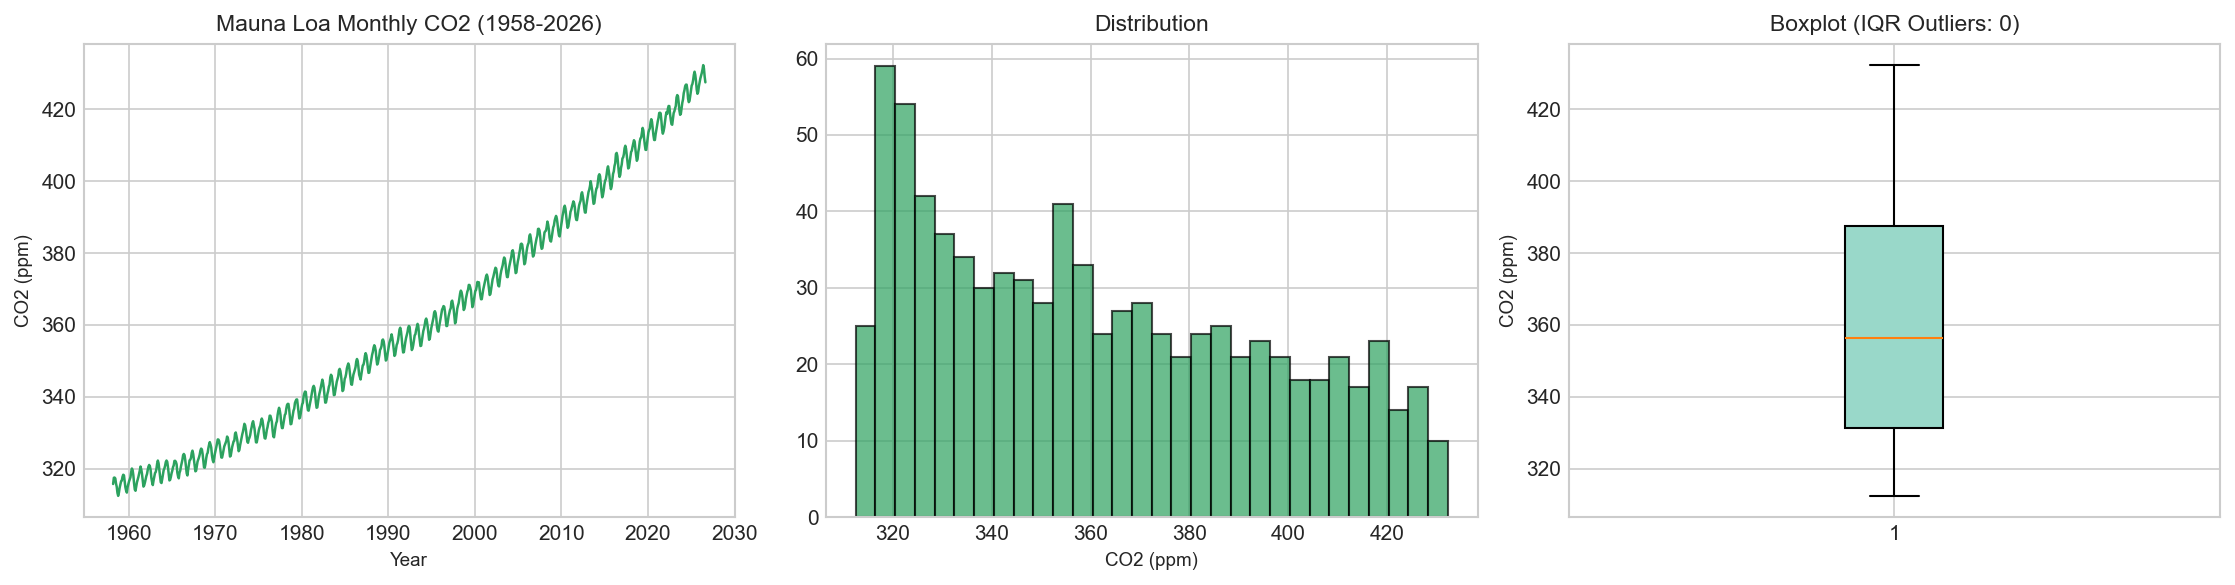

In [14]:
# 5. OUTLIERS & 6. UNIVARIATE: co2_mm_mlo.txt
s_co2_mm, dom_inv, iqr_out = check_domain_outliers(df_co2_mm, 'monthly_average', 250, 500, name="Mauna Loa Monthly CO2")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_co2_mm['decimal_date'], df_co2_mm['monthly_average'], color='#2ca25f', lw=1.2)
axes[0].set_title("Mauna Loa Monthly CO2 (1958-2026)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("CO2 (ppm)")

axes[1].hist(df_co2_mm['monthly_average'], bins=30, color='#2ca25f', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("CO2 (ppm)")

axes[2].boxplot(df_co2_mm['monthly_average'], vert=True, patch_artist=True, boxprops=dict(facecolor='#99d8c9'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("CO2 (ppm)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "co2_mm_mlo_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

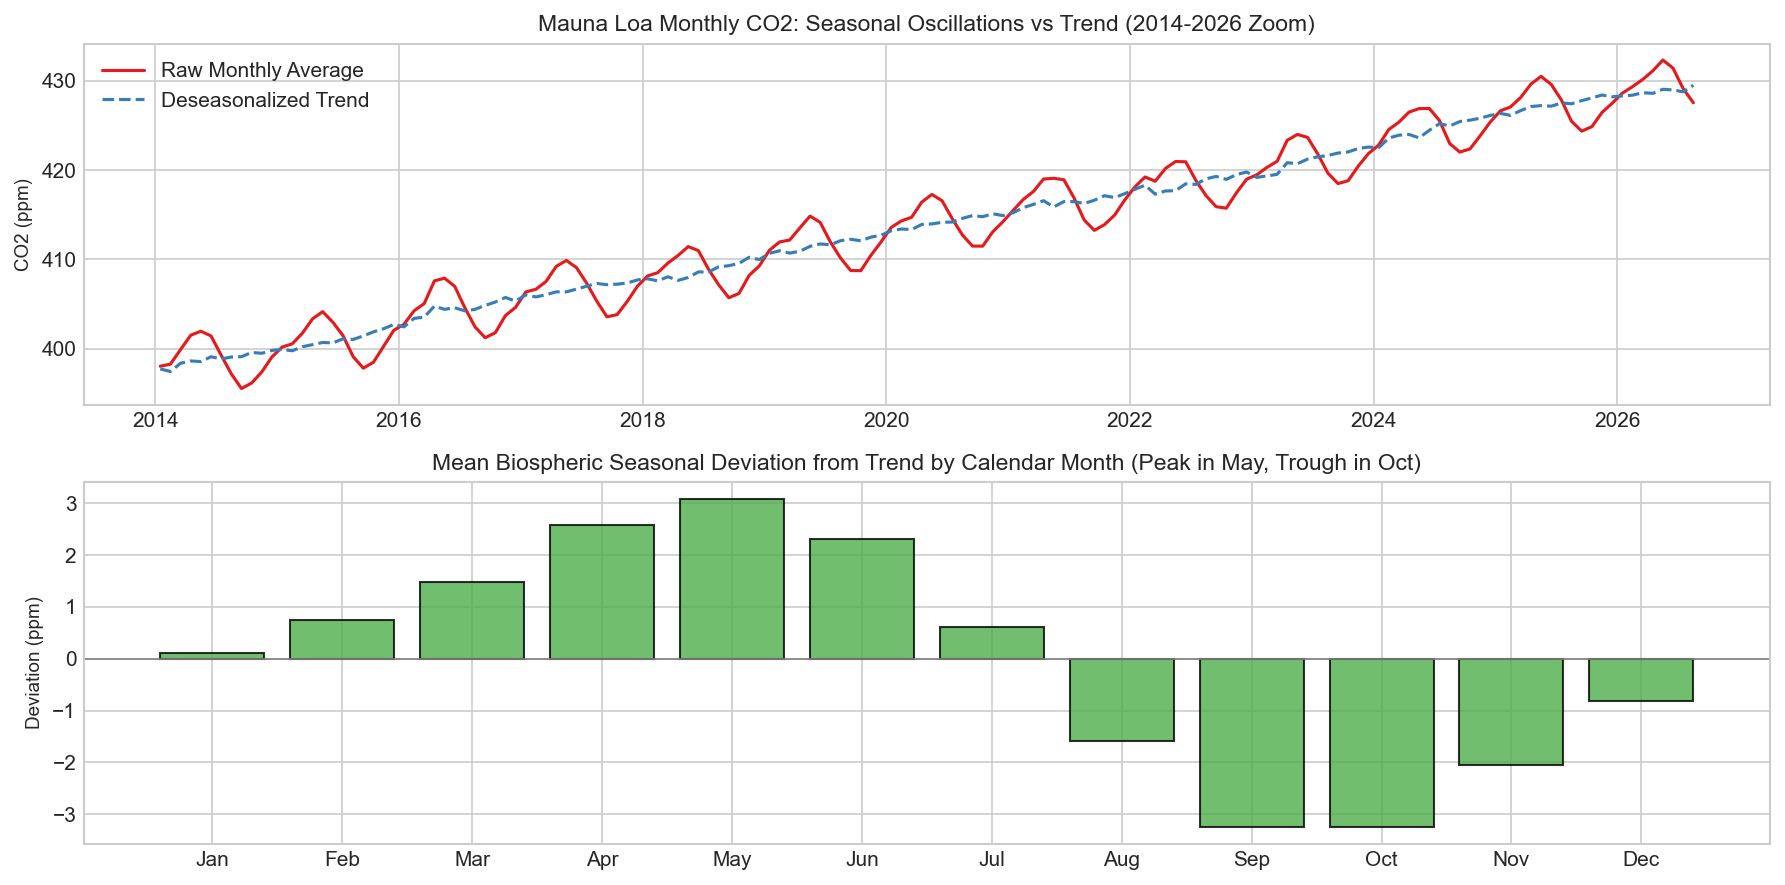

In [15]:
# 7. SEASONALITY: Raw vs Deseasonalized Monthly CO2
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=False)

# 10-year zoom showing seasonal oscillations
recent_mask = df_co2_mm['year'] >= 2014
axes[0].plot(df_co2_mm.loc[recent_mask, 'decimal_date'], df_co2_mm.loc[recent_mask, 'monthly_average'], label='Raw Monthly Average', color='#e41a1c', lw=1.5)
axes[0].plot(df_co2_mm.loc[recent_mask, 'decimal_date'], df_co2_mm.loc[recent_mask, 'deseasonalized'], label='Deseasonalized Trend', color='#377eb8', lw=1.5, ls='--')
axes[0].set_title("Mauna Loa Monthly CO2: Seasonal Oscillations vs Trend (2014-2026 Zoom)")
axes[0].set_ylabel("CO2 (ppm)")
axes[0].legend()

# Seasonal cycle amplitude by month
df_co2_mm['seasonal_cycle'] = df_co2_mm['monthly_average'] - df_co2_mm['deseasonalized']
cycle_by_month = df_co2_mm.groupby('month')['seasonal_cycle'].mean()
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
axes[1].bar(month_labels, cycle_by_month.values, color='#4daf4a', edgecolor='black', alpha=0.8)
axes[1].set_title("Mean Biospheric Seasonal Deviation from Trend by Calendar Month (Peak in May, Trough in Oct)")
axes[1].set_ylabel("Deviation (ppm)")
axes[1].axhline(0, color='gray', lw=0.8)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "co2_mm_mlo_seasonality.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [16]:
# 8. PROFILING REPORT: co2_mm_mlo.txt
prof_co2_mm = ProfileReport(df_co2_mm, title="Raw Profile: co2_mm_mlo.txt", minimal=True, correlations=None, interactions=None)
prof_co2_mm.to_file(os.path.join(PROFILE_DIR, "co2_mm_mlo.html"))
print(f"Profiling report saved to {PROFILE_DIR}/co2_mm_mlo.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/9 [00:00<?, ?it/s]

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:00<00:00, 163414.44it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/co2_mm_mlo.html


### Finding: `co2_mm_mlo.txt`
- **File Structure:** 42 lines of header comments, whitespace-delimited, 8 columns: `year`, `month`, `decimal_date`, `monthly_average`, `deseasonalized`, `ndays`, `sdev_days`, `unc_mon_mean`. 822 monthly rows from March 1958 to August 2026.
- **Sentinels:** `-1` in `ndays` (195 rows) and `-9.99` in `sdev_days` / `-0.99` in `unc_mon_mean` (196 rows) denote early Scripps records (1958–1974) and interpolated months where daily statistics were not preserved. The primary measurement `monthly_average` has 0 missing entries.
- **Seasonality:** Strong biospheric oscillation with amplitude ~6 ppm, peaking in May (before Northern Hemisphere vegetation draw-down) and reaching a minimum in October.
- **Recommendation:** Use `monthly_average` as the primary feature for monthly modeling. Replace sentinels in metadata columns with `NaN`.

## 4. Raw File: `smoothedco2.txt` (Law Dome Ice Core Spliced CO2)
**Role:** Essential historical proxy to extend CO2 observations back to 1880 for the annual dataset.  
**Source:** Rubino et al. / CSIRO / Antarctic ice cores (Law Dome & Dronning Maud Land).

In [17]:
# 1. UNDERSTAND & LOAD: smoothedco2.txt
filepath_ice = os.path.join(RAW_DIR, "smoothedco2.txt")
print_raw_sample(filepath_ice, n_head=15, n_tail=5)

df_ice = pd.read_csv(filepath_ice, sep='\t')
print("\nShape:", df_ice.shape)
df_ice.info()
display(df_ice.head(3))
display(df_ice.tail(3))
display(df_ice[['Year', 'ALL_50_full', 'LD_050', 'DML_050']].describe())

=== File: data/raw/smoothedco2.txt (Total Lines: 1006) ===
--- First 15 Raw Lines ---
  1: Year	ALL_50_full	LD_050	DML_050	ALL_050	LD_075	DML_075	ALL_075	LD_100	DML_100	ALL_100	LD_125	DML_125	ALL_125	LD_150	DML_150	ALL_150	LD_175	DML_175	ALL_175	LD_200	DML_200	ALL_200
  2: 1000	278.66	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN
  3: 1001	278.68	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN
  4: 1002	278.69	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN
  5: 1003	278.71	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN
  6: 1004	278.72	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN
  7: 1005	278.73	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN
  8: 1006	278.74	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN	NaN
  9: 1007	278.75	NaN	NaN

,Year,ALL_50_full,LD_050,DML_050,ALL_050,LD_075,DML_075,ALL_075,LD_100,DML_100,...,ALL_125,LD_150,DML_150,ALL_150,LD_175,DML_175,ALL_175,LD_200,DML_200,ALL_200
0,1000,278.66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1001,278.68,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1002,278.69,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Year,ALL_50_full,LD_050,DML_050,ALL_050,LD_075,DML_075,ALL_075,LD_100,DML_100,...,ALL_125,LD_150,DML_150,ALL_150,LD_175,DML_175,ALL_175,LD_200,DML_200,ALL_200
1002,2002,369.66,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1003,2003,371.30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1004,2004,372.93,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Year,ALL_50_full,LD_050,DML_050
count,1005.000000,1005.000000,751.000000,751.000000
mean,1502.000000,284.887801,280.554288,280.167523
std,290.262812,14.310892,2.657925,1.407282
min,1000.000000,276.450000,274.610000,277.480000
25%,1251.000000,279.600000,278.440000,279.085000
50%,1502.000000,280.980000,281.460000,280.460000
75%,1753.000000,282.100000,282.585000,281.315000
max,2004.000000,372.930000,284.000000,282.410000


In [18]:
# 2. TIME COVERAGE & 3. MISSING: smoothedco2.txt
print(f"Coverage: {df_ice['Year'].min()} to {df_ice['Year'].max()} ({len(df_ice)} continuous annual rows)")
print(f"Missing values in ALL_50_full: {df_ice['ALL_50_full'].isnull().sum()}")
print(f"Missing values in LD_050: {df_ice['LD_050'].isnull().sum()} (unpopulated before year 1254)")

Coverage: 1000 to 2004 (1005 continuous annual rows)
Missing values in ALL_50_full: 0
Missing values in LD_050: 254 (unpopulated before year 1254)


[Ice Core CO2 (ALL_50_full)] Summary:
  Count: 1005, Mean: 284.888, Median: 280.980, Std: 14.311
  Min: 276.450, Max: 372.930
  Domain bounds [250, 500]: 0 violations
  IQR bounds [275.85, 285.85]: 154 flagged outliers


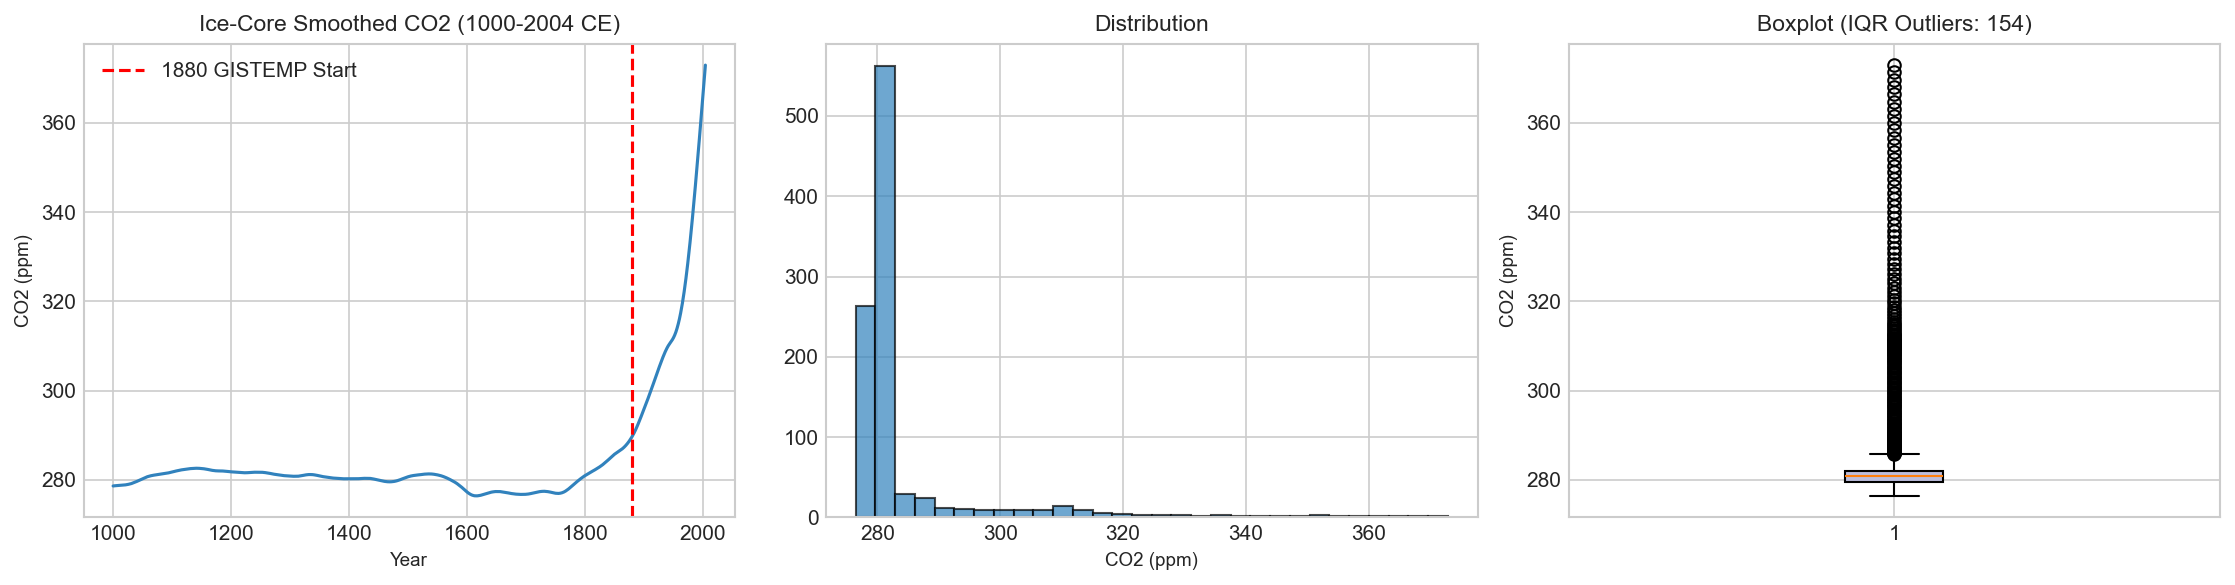

In [19]:
# 5. OUTLIERS & 6. UNIVARIATE: smoothedco2.txt
s_ice, dom_inv, iqr_out = check_domain_outliers(df_ice, 'ALL_50_full', 250, 500, name="Ice Core CO2 (ALL_50_full)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_ice['Year'], df_ice['ALL_50_full'], color='#3182bd', lw=1.5)
axes[0].axvline(1880, color='red', ls='--', label='1880 GISTEMP Start')
axes[0].set_title("Ice-Core Smoothed CO2 (1000-2004 CE)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("CO2 (ppm)")
axes[0].legend()

axes[1].hist(df_ice['ALL_50_full'], bins=30, color='#3182bd', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("CO2 (ppm)")

axes[2].boxplot(df_ice['ALL_50_full'], vert=True, patch_artist=True, boxprops=dict(facecolor='#bcbddc'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("CO2 (ppm)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "smoothedco2_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [20]:
# 8. PROFILING REPORT: smoothedco2.txt
prof_ice = ProfileReport(df_ice, title="Raw Profile: smoothedco2.txt", minimal=True, correlations=None, interactions=None)
prof_ice.to_file(os.path.join(PROFILE_DIR, "smoothedco2.html"))
print(f"Profiling report saved to {PROFILE_DIR}/smoothedco2.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                      | 0/23 [00:00<?, ?it/s]

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 23/23 [00:00<00:00, 333802.74it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/smoothedco2.html


### Finding: `smoothedco2.txt`
- **File Structure:** Tab-separated with 23 columns representing various spline filter cutoffs (50, 75, 100, 125, 150, 175, 200 years) across Law Dome (`LD`), Dronning Maud Land (`DML`), and composite records (`ALL`). 1005 annual rows spanning 1000 to 2004 CE.
- **Completeness:** Column `ALL_50_full` provides a continuous, complete 1005-year reconstruction without a single missing value.
- **Recommendation:** Use `ALL_50_full` to supply annual CO2 from 1880 to 1958, splicing to Mauna Loa instrumental data in 1959.

## 5. Raw File: `detrend.nino34.ascii.txt` (NOAA Detrended Niño 3.4 SST Anomaly)
**Role:** Driver for natural interannual climate variability (El Niño / Southern Oscillation).  
**Source:** NOAA Climate Prediction Center (CPC).

In [21]:
# 1. UNDERSTAND & LOAD: detrend.nino34.ascii.txt
filepath_nino = os.path.join(RAW_DIR, "detrend.nino34.ascii.txt")
print_raw_sample(filepath_nino, n_head=15, n_tail=5)

df_nino = pd.read_csv(filepath_nino, sep=r'\s+')
print("\nShape:", df_nino.shape)
df_nino.info()
display(df_nino.head(3))
display(df_nino.tail(3))
display(df_nino.describe())

=== File: data/raw/detrend.nino34.ascii.txt (Total Lines: 919) ===
--- First 15 Raw Lines ---
  1:  YR   MON  TOTAL ClimAdjust ANOM
  2: 1950   1   24.56   26.18   -1.62
  3: 1950   2   25.07   26.39   -1.32
  4: 1950   3   25.88   26.95   -1.07
  5: 1950   4   26.29   27.39   -1.11
  6: 1950   5   26.19   27.56   -1.37
  7: 1950   6   26.47   27.21   -0.74
  8: 1950   7   26.28   26.72   -0.44
  9: 1950   8   25.88   26.30   -0.42
 10: 1950   9   25.73   26.14   -0.41
 11: 1950  10   25.68   26.01   -0.32
 12: 1950  11   25.46   26.06   -0.60
 13: 1950  12   25.29   26.18   -0.88
 14: 1951   1   25.26   26.18   -0.92
 15: 1951   2   25.72   26.39   -0.66
--- Last 5 Raw Lines ---
915: 2026   2   26.49   26.61   -0.12
916: 2026   3   27.29   27.19    0.09
917: 2026   4   28.13   27.71    0.42
918: 2026   5   28.84   27.83    1.01
919: 2026   6   29.17   27.67    1.50

Shape: (918, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 5 columns):


,YR,MON,TOTAL,ClimAdjust,ANOM
0,1950,1,24.56,26.18,-1.62
1,1950,2,25.07,26.39,-1.32
2,1950,3,25.88,26.95,-1.07


,YR,MON,TOTAL,ClimAdjust,ANOM
915,2026,4,28.13,27.71,0.42
916,2026,5,28.84,27.83,1.01
917,2026,6,29.17,27.67,1.50


,YR,MON,TOTAL,ClimAdjust,ANOM
count,918.000000,918.000000,918.000000,918.00000,918.000000
mean,1987.751634,6.480392,26.908170,26.87939,0.028932
std,22.096630,3.453879,0.987236,0.50048,0.853258
min,1950.000000,1.000000,24.250000,26.01000,-2.090000
25%,1969.000000,3.000000,26.210000,26.50000,-0.560000
50%,1988.000000,6.000000,26.980000,26.73000,-0.030000
75%,2007.000000,9.000000,27.590000,27.28750,0.537500
max,2026.000000,12.000000,29.410000,27.94000,2.770000


Time Coverage: 1950-01 to 2026-06 (918 months)
Nulls: {'YR': 0, 'MON': 0, 'TOTAL': 0, 'ClimAdjust': 0, 'ANOM': 0}
Duplicates: 0
[Niño 3.4 SST Anomaly] Summary:
  Count: 918, Mean: 0.029, Median: -0.030, Std: 0.853
  Min: -2.090, Max: 2.770
  Domain bounds [-3.0, 4.0]: 0 violations
  IQR bounds [-2.21, 2.18]: 13 flagged outliers


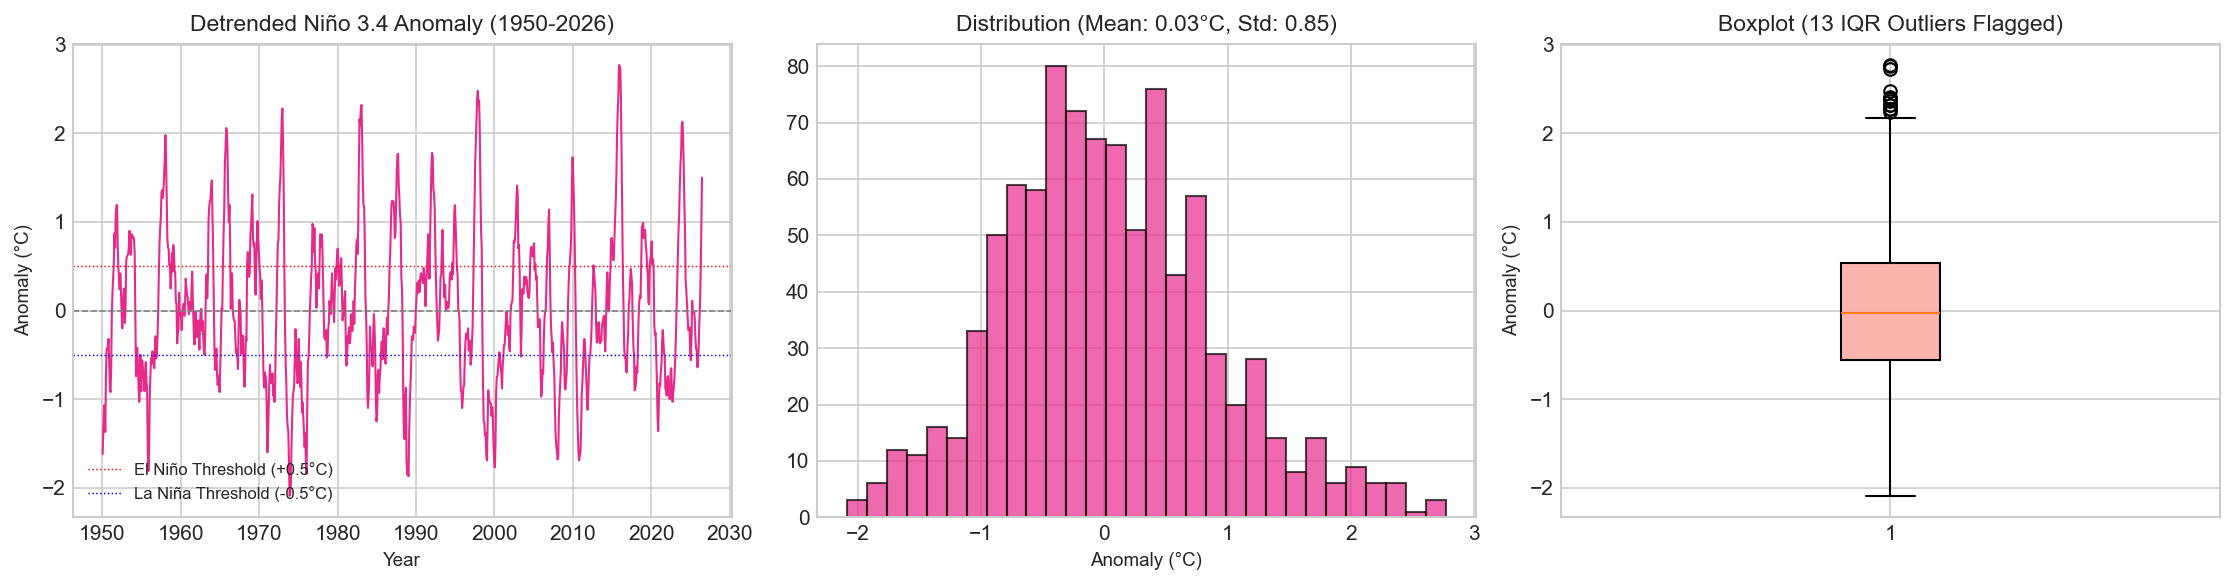

In [22]:
# 2. TIME COVERAGE, 3. MISSING, 4. DUPLICATES, 5. OUTLIERS & 6. UNIVARIATE: detrend.nino34.ascii.txt
print(f"Time Coverage: {df_nino['YR'].iloc[0]}-{df_nino['MON'].iloc[0]:02d} to {df_nino['YR'].iloc[-1]}-{df_nino['MON'].iloc[-1]:02d} ({len(df_nino)} months)")
print(f"Nulls: {df_nino.isnull().sum().to_dict()}")
print(f"Duplicates: {df_nino.duplicated(subset=['YR', 'MON']).sum()}")

# Check anomaly against [-3.0, 4.0 °C]
s_nino, dom_inv, iqr_out = check_domain_outliers(df_nino, 'ANOM', -3.0, 4.0, name="Niño 3.4 SST Anomaly")

# Convert to fractional year for plotting
df_nino['frac_year'] = df_nino['YR'] + (df_nino['MON'] - 0.5) / 12.0

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_nino['frac_year'], df_nino['ANOM'], color='#e7298a', lw=1.0)
axes[0].axhline(0, color='gray', ls='--', lw=0.8)
axes[0].axhline(0.5, color='red', ls=':', lw=0.7, label='El Niño Threshold (+0.5°C)')
axes[0].axhline(-0.5, color='blue', ls=':', lw=0.7, label='La Niña Threshold (-0.5°C)')
axes[0].set_title("Detrended Niño 3.4 Anomaly (1950-2026)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Anomaly (°C)")
axes[0].legend(loc='lower left', fontsize=8)

axes[1].hist(df_nino['ANOM'], bins=30, color='#e7298a', edgecolor='black', alpha=0.7)
axes[1].set_title(f"Distribution (Mean: {s_nino.mean():.2f}°C, Std: {s_nino.std():.2f})")
axes[1].set_xlabel("Anomaly (°C)")

axes[2].boxplot(df_nino['ANOM'], vert=True, patch_artist=True, boxprops=dict(facecolor='#fbb4ae'))
axes[2].set_title(f"Boxplot ({len(iqr_out)} IQR Outliers Flagged)")
axes[2].set_ylabel("Anomaly (°C)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "nino34_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [23]:
# 8. PROFILING REPORT: detrend.nino34.ascii.txt
prof_nino = ProfileReport(df_nino, title="Raw Profile: detrend.nino34.ascii.txt", minimal=True, correlations=None, interactions=None)
prof_nino.to_file(os.path.join(PROFILE_DIR, "detrend.nino34.html"))
print(f"Profiling report saved to {PROFILE_DIR}/detrend.nino34.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/6 [00:00<?, ?it/s]

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 6267.95it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/detrend.nino34.html


### Finding: `detrend.nino34.ascii.txt`
- **File Structure:** Whitespace-separated with header row (`YR MON TOTAL ClimAdjust ANOM`), 918 monthly rows from January 1950 to June 2026.
- **Completeness:** 0 missing values, 0 sentinels, 0 duplicates.
- **Outliers:** 13 IQR outliers flagged (e.g. 1997–1998 at +2.67°C, 2015–2016 at +2.64°C). These are historically documented extreme "Super El Niño" events, perfectly valid physically and vital for predicting temperature anomalies.
- **Recommendation:** Use `ANOM` as monthly ENSO indicator; compute calendar-year mean for annual dataset (1950–2025).


## 6. Raw File: `SN_y_tot_V2.0.csv` (Annual Sunspot Numbers)
**Role:** Candidate driver for solar irradiance variability on annual scale.  
**Source:** WDC-SILSO, Royal Observatory of Belgium.

In [24]:
# 1. UNDERSTAND & LOAD: SN_y_tot_V2.0.csv
filepath_sn_y = os.path.join(RAW_DIR, "SN_y_tot_V2.0.csv")
print_raw_sample(filepath_sn_y, n_head=10, n_tail=5)

sn_y_cols = ['year_frac', 'sn_mean', 'sn_std', 'n_obs', 'is_definitive']
df_sn_y = pd.read_csv(filepath_sn_y, sep=';', header=None, names=sn_y_cols)
print("\nShape:", df_sn_y.shape)
df_sn_y.info()
display(df_sn_y.head(3))
display(df_sn_y.tail(3))
display(df_sn_y.describe())

=== File: data/raw/SN_y_tot_V2.0.csv (Total Lines: 326) ===
--- First 10 Raw Lines ---
  1: 1700.5;   8.3; -1.0;    -1;1
  2: 1701.5;  18.3; -1.0;    -1;1
  3: 1702.5;  26.7; -1.0;    -1;1
  4: 1703.5;  38.3; -1.0;    -1;1
  5: 1704.5;  60.0; -1.0;    -1;1
  6: 1705.5;  96.7; -1.0;    -1;1
  7: 1706.5;  48.3; -1.0;    -1;1
  8: 1707.5;  33.3; -1.0;    -1;1
  9: 1708.5;  16.7; -1.0;    -1;1
 10: 1709.5;  13.3; -1.0;    -1;1
--- Last 5 Raw Lines ---
322: 2021.5;  29.6;  7.9; 15233;1
323: 2022.5;  83.2; 14.2; 15258;1
324: 2023.5; 125.5; 19.2; 13286;1
325: 2024.5; 154.7; 22.0; 12265;1
326: 2025.5; 123.2; 17.8; 12473;1

Shape: (326, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 326 entries, 0 to 325
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year_frac      326 non-null    float64
 1   sn_mean        326 non-null    float64
 2   sn_std         326 non-null    float64
 3   n_obs          326 non-null    i

,year_frac,sn_mean,sn_std,n_obs,is_definitive
0,1700.5,8.3,-1.0,-1,1
1,1701.5,18.3,-1.0,-1,1
2,1702.5,26.7,-1.0,-1,1


,year_frac,sn_mean,sn_std,n_obs,is_definitive
323,2023.5,125.5,19.2,13286,1
324,2024.5,154.7,22.0,12265,1
325,2025.5,123.2,17.8,12473,1


,year_frac,sn_mean,sn_std,n_obs,is_definitive
count,326.000000,326.000000,326.000000,326.000000,326.0
mean,1863.000000,78.896319,4.801227,1263.325153,1.0
std,94.252321,61.920297,5.463214,2894.186004,0.0
min,1700.500000,0.000000,-1.000000,-1.000000,1.0
25%,1781.750000,24.750000,-1.000000,-1.000000,1.0
50%,1863.000000,66.250000,4.200000,365.000000,1.0
75%,1944.250000,116.600000,9.150000,365.000000,1.0
max,2025.500000,269.300000,22.000000,15258.000000,1.0


In [25]:
# 2. TIME COVERAGE & 3. MISSING: SN_y_tot_V2.0.csv
df_sn_y['year'] = df_sn_y['year_frac'].astype(int)
print(f"Coverage: {df_sn_y['year'].min()} to {df_sn_y['year'].max()} ({len(df_sn_y)} annual rows)")

# Missing sentinels
print(f"Standard nulls: {df_sn_y.isnull().sum().to_dict()}")
print(f"sn_std == -1.0: {(df_sn_y['sn_std'] == -1.0).sum()} (pre-1818 historical years without daily error estimates)")
print(f"n_obs == -1: {(df_sn_y['n_obs'] == -1).sum()} (pre-1818 historical years without observation tallies)")

Coverage: 1700 to 2025 (326 annual rows)
Standard nulls: {'year_frac': 0, 'sn_mean': 0, 'sn_std': 0, 'n_obs': 0, 'is_definitive': 0, 'year': 0}
sn_std == -1.0: 118 (pre-1818 historical years without daily error estimates)
n_obs == -1: 118 (pre-1818 historical years without observation tallies)


[Annual Sunspot Number] Summary:
  Count: 326, Mean: 78.896, Median: 66.250, Std: 61.920
  Min: 0.000, Max: 269.300
  Domain bounds [0.0, 500.0]: 0 violations
  IQR bounds [-113.02, 254.37]: 3 flagged outliers


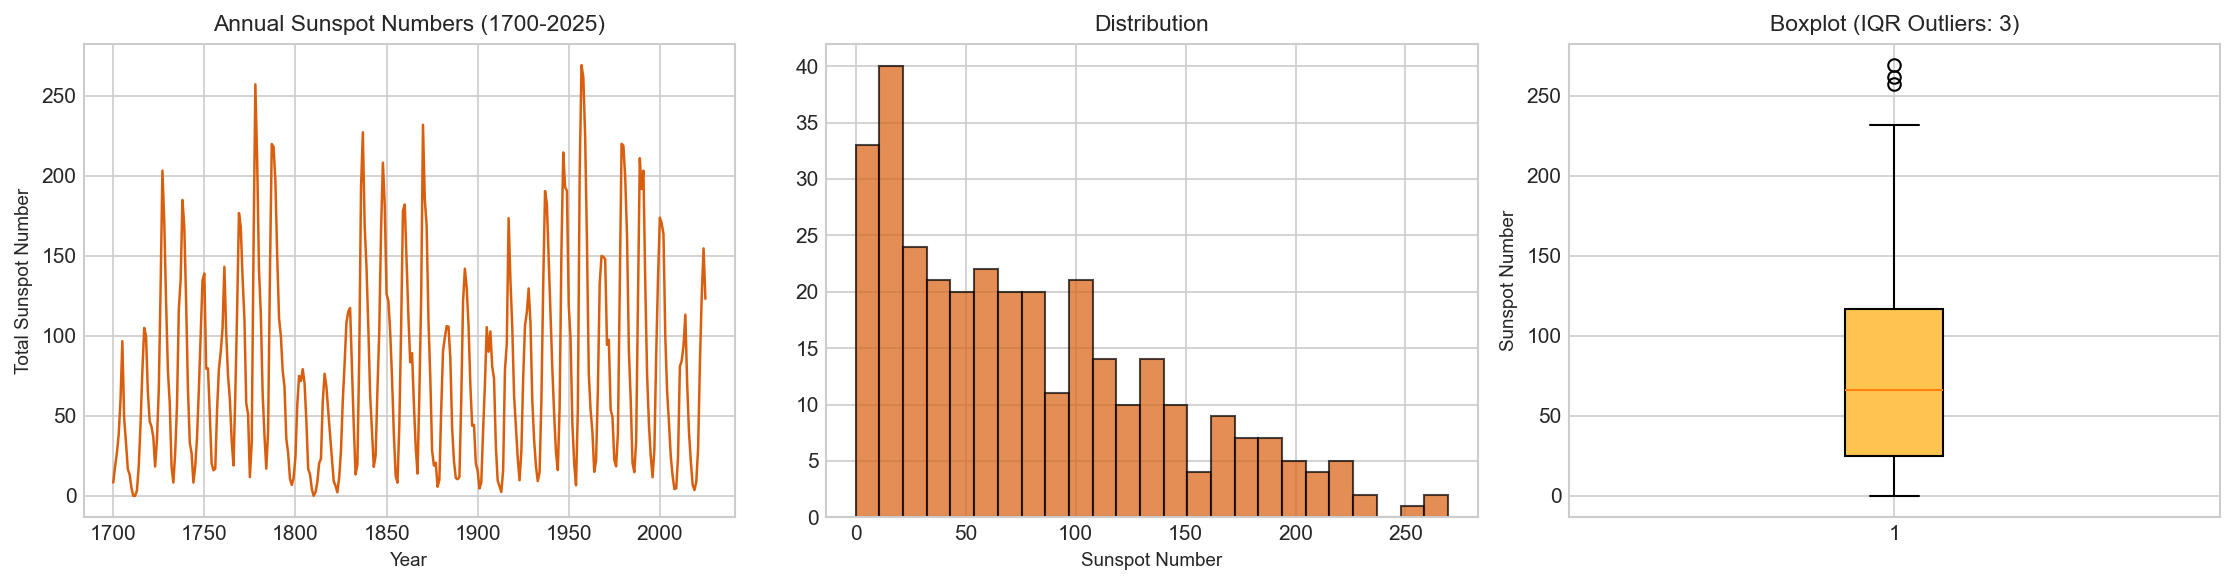

In [26]:
# 5. OUTLIERS & 6. UNIVARIATE: SN_y_tot_V2.0.csv
s_sn_y, dom_inv, iqr_out = check_domain_outliers(df_sn_y, 'sn_mean', 0.0, 500.0, name="Annual Sunspot Number")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_sn_y['year'], df_sn_y['sn_mean'], color='#d95f0e', lw=1.2)
axes[0].set_title("Annual Sunspot Numbers (1700-2025)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Total Sunspot Number")

axes[1].hist(df_sn_y['sn_mean'], bins=25, color='#d95f0e', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("Sunspot Number")

axes[2].boxplot(df_sn_y['sn_mean'], vert=True, patch_artist=True, boxprops=dict(facecolor='#fec44f'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("Sunspot Number")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sn_y_tot_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [27]:
# 8. PROFILING REPORT: SN_y_tot_V2.0.csv
prof_sn_y = ProfileReport(df_sn_y, title="Raw Profile: SN_y_tot_V2.0.csv", minimal=True, correlations=None, interactions=None)
prof_sn_y.to_file(os.path.join(PROFILE_DIR, "SN_y_tot_V2.0.html"))
print(f"Profiling report saved to {PROFILE_DIR}/SN_y_tot_V2.0.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/6 [00:00<?, ?it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 44699.51it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/SN_y_tot_V2.0.html


### Finding: `SN_y_tot_V2.0.csv`
- **File Structure:** Semicolon-delimited, no header, 5 columns: `year_frac`, `sn_mean`, `sn_std`, `n_obs`, `is_definitive`. 326 continuous annual rows (1700.5 to 2025.5).
- **Missing Sentinels:** Pre-1818 records have `sn_std == -1.0` and `n_obs == -1` (118 rows) due to lack of individual daily observer logs. The sunspot mean `sn_mean` itself is complete throughout.
- **Physical Dynamics:** Clean ~11-year Schwabe solar cycles. Outlier checks show solar maximum peaks are physically real.
- **Recommendation:** Cast year to integer `year`, retain `sn_mean`, replace metadata sentinels `-1` with `NaN`.

## 7. Raw File: `SN_m_tot_V2.0.csv` (Monthly Sunspot Numbers)
**Role:** Driver for solar activity on monthly scale.  
**Source:** WDC-SILSO.

In [28]:
# 1. UNDERSTAND & LOAD: SN_m_tot_V2.0.csv
filepath_sn_m = os.path.join(RAW_DIR, "SN_m_tot_V2.0.csv")
print_raw_sample(filepath_sn_m, n_head=10, n_tail=5)

sn_m_cols = ['year', 'month', 'frac_year', 'sn_mean', 'sn_std', 'n_obs', 'is_definitive']
df_sn_m = pd.read_csv(filepath_sn_m, sep=';', header=None, names=sn_m_cols)
print("\nShape:", df_sn_m.shape)
df_sn_m.info()
display(df_sn_m.head(3))
display(df_sn_m.tail(3))
display(df_sn_m.describe())

=== File: data/raw/SN_m_tot_V2.0.csv (Total Lines: 3333) ===
--- First 10 Raw Lines ---
  1: 1749;01;1749.042;  96.7; -1.0;   -1;1
  2: 1749;02;1749.123; 104.3; -1.0;   -1;1
  3: 1749;03;1749.204; 116.7; -1.0;   -1;1
  4: 1749;04;1749.288;  92.8; -1.0;   -1;1
  5: 1749;05;1749.371; 141.7; -1.0;   -1;1
  6: 1749;06;1749.455; 139.2; -1.0;   -1;1
  7: 1749;07;1749.538; 158.0; -1.0;   -1;1
  8: 1749;08;1749.623; 110.5; -1.0;   -1;1
  9: 1749;09;1749.707; 126.5; -1.0;   -1;1
 10: 1749;10;1749.790; 125.8; -1.0;   -1;1
--- Last 5 Raw Lines ---
3329: 2026;05;2026.371; 101.8; 15.5; 1319;1
3330: 2026;06;2026.453;  93.3; 15.1; 1316;1
3331: 2026;07;2026.538;  78.1; 11.2; 1371;0
3332: 2026;08;2026.623;  76.0; 12.3; 1248;0
3333: 2026;09;2026.705;  60.3; 13.0; 1117;0

Shape: (3333, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   year           3333 

,year,month,frac_year,sn_mean,sn_std,n_obs,is_definitive
0,1749,1,1749.042,96.7,-1.0,-1,1
1,1749,2,1749.123,104.3,-1.0,-1,1
2,1749,3,1749.204,116.7,-1.0,-1,1


,year,month,frac_year,sn_mean,sn_std,n_obs,is_definitive
3330,2026,7,2026.538,78.1,11.2,1371,0
3331,2026,8,2026.623,76.0,12.3,1248,0
3332,2026,9,2026.705,60.3,13.0,1117,0


,year,month,frac_year,sn_mean,sn_std,n_obs,is_definitive
count,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000,3333.000000
mean,1887.375338,6.495950,1887.872986,82.195230,5.762886,126.561656,0.999100
std,80.191614,3.451394,80.191511,67.557294,5.427009,266.518542,0.029992
min,1749.000000,1.000000,1749.042000,0.000000,-1.000000,-1.000000,0.000000
25%,1818.000000,3.000000,1818.455000,24.400000,0.100000,7.000000,1.000000
50%,1887.000000,6.000000,1887.874000,68.600000,5.500000,30.000000,1.000000
75%,1957.000000,9.000000,1957.288000,123.000000,9.600000,31.000000,1.000000
max,2026.000000,12.000000,2026.705000,398.200000,29.400000,1587.000000,1.000000


In [29]:
# 2. TIME COVERAGE & 3. MISSING: SN_m_tot_V2.0.csv
print(f"Coverage: {df_sn_m['year'].iloc[0]}-{df_sn_m['month'].iloc[0]:02d} to {df_sn_m['year'].iloc[-1]}-{df_sn_m['month'].iloc[-1]:02d} ({len(df_sn_m)} monthly rows)")
print(f"Standard nulls: {df_sn_m.isnull().sum().to_dict()}")
print(f"sn_std == -1.0: {(df_sn_m['sn_std'] == -1.0).sum()} (months without observer standard deviation)")
print(f"n_obs == -1: {(df_sn_m['n_obs'] == -1).sum()} (months without observer count)")

Coverage: 1749-01 to 2026-09 (3333 monthly rows)
Standard nulls: {'year': 0, 'month': 0, 'frac_year': 0, 'sn_mean': 0, 'sn_std': 0, 'n_obs': 0, 'is_definitive': 0}
sn_std == -1.0: 828 (months without observer standard deviation)
n_obs == -1: 828 (months without observer count)


[Monthly Sunspot Number] Summary:
  Count: 3333, Mean: 82.195, Median: 68.600, Std: 67.557
  Min: 0.000, Max: 398.200
  Domain bounds [0.0, 600.0]: 0 violations
  IQR bounds [-123.50, 270.90]: 30 flagged outliers


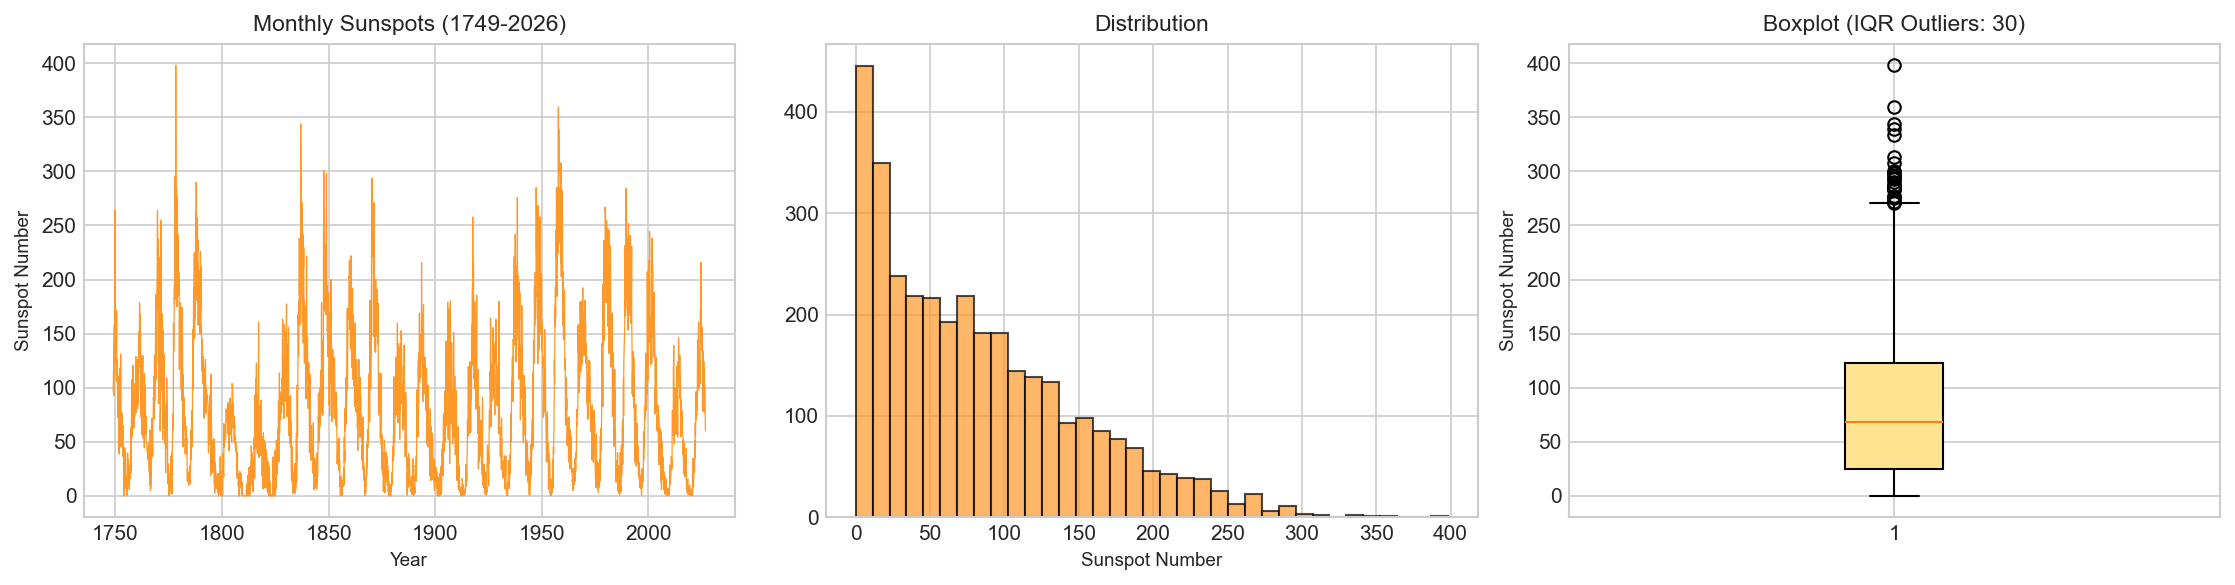

In [30]:
# 5. OUTLIERS & 6. UNIVARIATE: SN_m_tot_V2.0.csv
s_sn_m, dom_inv, iqr_out = check_domain_outliers(df_sn_m, 'sn_mean', 0.0, 600.0, name="Monthly Sunspot Number")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_sn_m['frac_year'], df_sn_m['sn_mean'], color='#fe9929', lw=0.6)
axes[0].set_title("Monthly Sunspots (1749-2026)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sunspot Number")

axes[1].hist(df_sn_m['sn_mean'], bins=35, color='#fe9929', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("Sunspot Number")

axes[2].boxplot(df_sn_m['sn_mean'], vert=True, patch_artist=True, boxprops=dict(facecolor='#fee391'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("Sunspot Number")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sn_m_tot_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [31]:
# 8. PROFILING REPORT: SN_m_tot_V2.0.csv
prof_sn_m = ProfileReport(df_sn_m, title="Raw Profile: SN_m_tot_V2.0.csv", minimal=True, correlations=None, interactions=None)
prof_sn_m.to_file(os.path.join(PROFILE_DIR, "SN_m_tot_V2.0.html"))
print(f"Profiling report saved to {PROFILE_DIR}/SN_m_tot_V2.0.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/7 [00:00<?, ?it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:00<00:00, 15307.68it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/SN_m_tot_V2.0.html


### Finding: `SN_m_tot_V2.0.csv`
- **File Structure:** Semicolon-delimited, no header, 7 columns: `year`, `month`, `frac_year`, `sn_mean`, `sn_std`, `n_obs`, `is_definitive`. 3333 monthly rows from January 1749 to September 2026.
- **Missing Sentinels:** 828 early months feature `sn_std == -1.0` and `n_obs == -1`.
- **Integrity:** `sn_mean` is strictly non-negative ($\ge 0$) across all 3333 months.
- **Recommendation:** Primary monthly solar activity series. Replace metadata sentinels `-1` with `NaN`.


## 8. Raw File: `ch4_annmean_gl.txt` (NOAA Globally Averaged Annual Methane)
**Role:** Atmospheric methane concentration (ppb) for annual dataset.  
**Source:** NOAA GML Marine Boundary Layer network.

In [32]:
# 1. UNDERSTAND & LOAD: ch4_annmean_gl.txt
filepath_ch4_ann = os.path.join(RAW_DIR, "ch4_annmean_gl.txt")
print_raw_sample(filepath_ch4_ann, n_head=15, n_tail=5)

df_ch4_ann = pd.read_csv(filepath_ch4_ann, comment='#', sep=r'\s+', names=['year', 'mean', 'unc'])
print("\nShape:", df_ch4_ann.shape)
df_ch4_ann.info()
display(df_ch4_ann.head(3))
display(df_ch4_ann.tail(3))
display(df_ch4_ann.describe())

=== File: data/raw/ch4_annmean_gl.txt (Total Lines: 88) ===
--- First 15 Raw Lines ---
  1: # --------------------------------------------------------------------
  2: # USE OF NOAA GML DATA
  3: #
  4: # These data are made freely available to the public and the scientific
  5: # community in the belief that their wide dissemination will lead to
  6: # greater understanding and new scientific insights. To ensure that GML
  7: # receives fair credit for their work please include relevant citation
  8: # text in publications. We encourage users to contact the data providers,
  9: # who can provide detailed information about the measurements and
 10: # scientific insight.  In cases where the data are central to a
 11: # publication, coauthorship for data providers may be appropriate.
 12: #
 13: #
 14: #
 15: # Contact:  Xin Lan (xin.lan@noaa.gov)
--- Last 5 Raw Lines ---
 84:   2021  1894.87     0.63
 85:   2022  1911.01     0.89
 86:   2023  1921.46     0.70
 87:   2024  1929.47     0.

,year,mean,unc
0,1984,1644.84,0.60
1,1985,1657.29,0.55
2,1986,1670.09,0.77


,year,mean,unc
39,2023,1921.46,0.70
40,2024,1929.47,0.59
41,2025,1936.03,0.48


,year,mean,unc
count,42.000000,42.000000,42.000000
mean,2004.500000,1786.900000,0.590000
std,12.267844,73.024642,0.096323
min,1984.000000,1644.840000,0.380000
25%,1994.250000,1743.765000,0.522500
50%,2004.500000,1776.035000,0.575000
75%,2014.750000,1831.290000,0.630000
max,2025.000000,1936.030000,0.890000


Coverage: 1984 to 2025 (42 annual rows)
[NOAA Annual CH4] Summary:
  Count: 42, Mean: 1786.900, Median: 1776.035, Std: 73.025
  Min: 1644.840, Max: 1936.030
  Domain bounds [600, 2100]: 0 violations
  IQR bounds [1612.48, 1962.58]: 0 flagged outliers


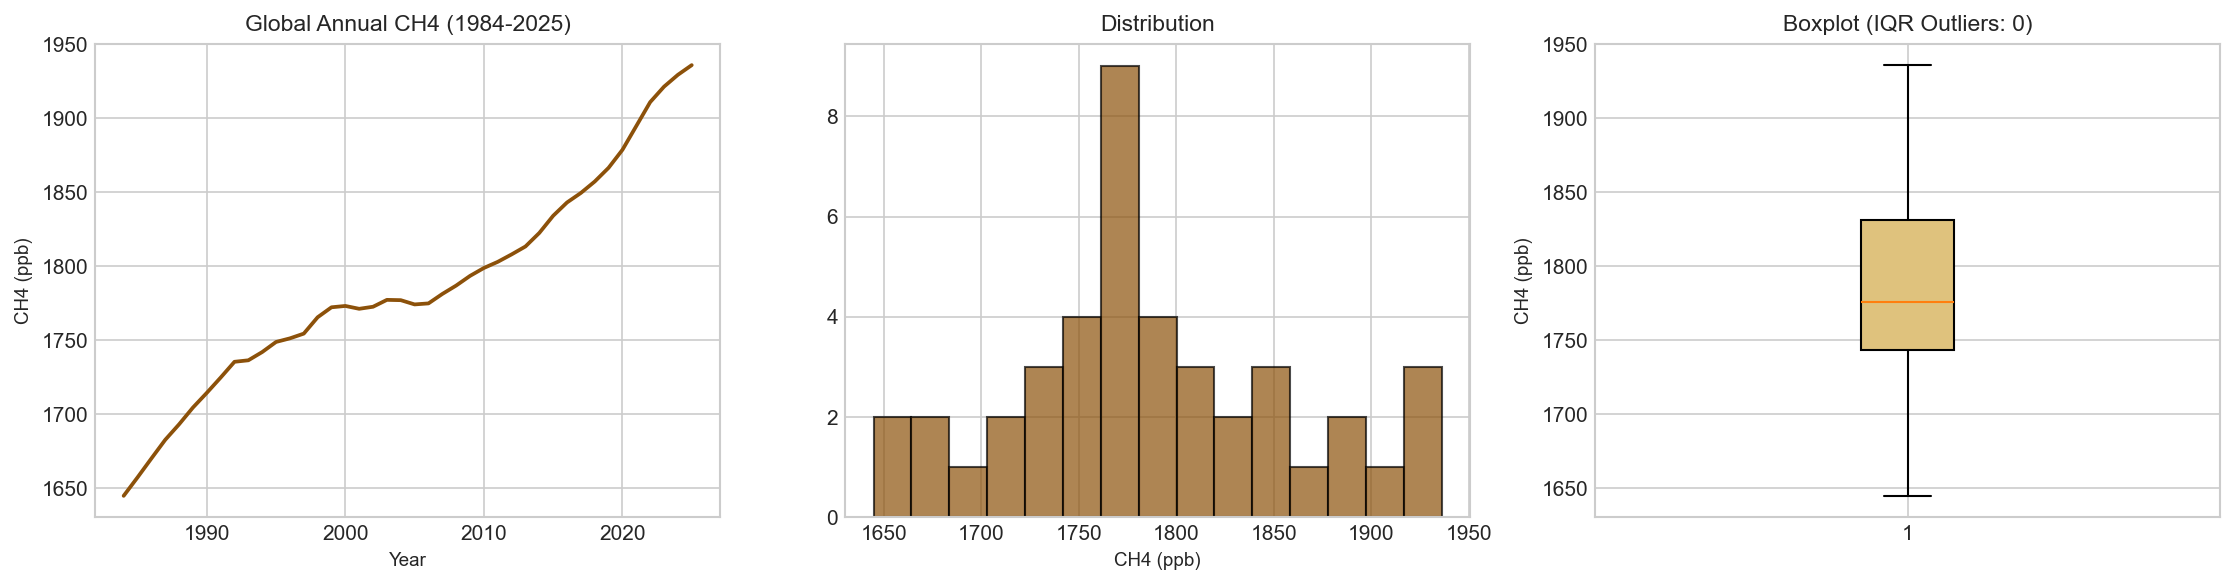

In [33]:
# 2. TIME COVERAGE & 5. OUTLIERS & 6. UNIVARIATE: ch4_annmean_gl.txt
print(f"Coverage: {df_ch4_ann['year'].min()} to {df_ch4_ann['year'].max()} ({len(df_ch4_ann)} annual rows)")
s_ch4_ann, dom_inv, iqr_out = check_domain_outliers(df_ch4_ann, 'mean', 600, 2100, name="NOAA Annual CH4")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_ch4_ann['year'], df_ch4_ann['mean'], color='#8c510a', lw=1.8)
axes[0].set_title("Global Annual CH4 (1984-2025)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("CH4 (ppb)")

axes[1].hist(df_ch4_ann['mean'], bins=15, color='#8c510a', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("CH4 (ppb)")

axes[2].boxplot(df_ch4_ann['mean'], vert=True, patch_artist=True, boxprops=dict(facecolor='#dfc27d'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("CH4 (ppb)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ch4_annmean_gl_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [34]:
# 8. PROFILING REPORT: ch4_annmean_gl.txt
prof_ch4_ann = ProfileReport(df_ch4_ann, title="Raw Profile: ch4_annmean_gl.txt", minimal=True, correlations=None, interactions=None)
prof_ch4_ann.to_file(os.path.join(PROFILE_DIR, "ch4_annmean_gl.html"))
print(f"Profiling report saved to {PROFILE_DIR}/ch4_annmean_gl.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/3 [00:00<?, ?it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 47662.55it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/ch4_annmean_gl.html


### Finding: `ch4_annmean_gl.txt`
- **File Structure:** 46 lines of comment headers, whitespace-delimited, columns: `year`, `mean`, `unc`. 42 annual observations from 1984 to 2025.
- **Completeness & Domain:** 0 missing values, 0 sentinels. Rises from 1644.84 ppb (1984) to 1936.03 ppb (2025), well within domain bounds [600, 2100 ppb].
- **Recommendation:** Clean, authoritative modern annual CH4 series from 1984 onward.

## 9. Raw File: `ch4_mm_gl.txt` (NOAA Globally Averaged Monthly Methane)
**Role:** Atmospheric methane concentration (ppb) for monthly dataset.  
**Source:** NOAA GML.

In [35]:
# 1. UNDERSTAND & LOAD: ch4_mm_gl.txt
filepath_ch4_mm = os.path.join(RAW_DIR, "ch4_mm_gl.txt")
print_raw_sample(filepath_ch4_mm, n_head=15, n_tail=5)

ch4_mm_cols = ['year', 'month', 'decimal', 'average', 'average_unc', 'trend', 'trend_unc']
df_ch4_mm = pd.read_csv(filepath_ch4_mm, comment='#', sep=r'\s+', names=ch4_mm_cols)
print("\nShape:", df_ch4_mm.shape)
df_ch4_mm.info()
display(df_ch4_mm.head(3))
display(df_ch4_mm.tail(3))
display(df_ch4_mm.describe())

=== File: data/raw/ch4_mm_gl.txt (Total Lines: 564) ===
--- First 15 Raw Lines ---
  1: # --------------------------------------------------------------------
  2: # USE OF NOAA GML DATA
  3: #
  4: # These data are made freely available to the public and the scientific
  5: # community in the belief that their wide dissemination will lead to
  6: # greater understanding and new scientific insights. To ensure that GML
  7: # receives fair credit for their work please include relevant citation
  8: # text in publications. We encourage users to contact the data providers,
  9: # who can provide detailed information about the measurements and
 10: # scientific insight.  In cases where the data are central to a
 11: # publication, coauthorship for data providers may be appropriate.
 12: #
 13: #
 14: #
 15: # Contact:  Xin Lan (xin.lan@noaa.gov)
--- Last 5 Raw Lines ---
560:   2026       2      2026.125       1939.48         -9.99       1939.08         -9.99
561:   2026       3      2026.2

,year,month,decimal,average,average_unc,trend,trend_unc
0,1983,7,1983.542,1625.96,2.25,1635.11,1.50
1,1983,8,1983.625,1628.04,2.83,1635.61,1.44
2,1983,9,1983.708,1638.44,2.45,1636.17,1.36


,year,month,decimal,average,average_unc,trend,trend_unc
513,2026,4,2026.292,1937.57,-9.99,1940.46,-9.99
514,2026,5,2026.375,1939.61,-9.99,1941.27,-9.99
515,2026,6,2026.458,1934.57,-9.99,1942.12,-9.99


,year,month,decimal,average,average_unc,trend,trend_unc
count,516.000000,516.000000,516.000000,516.000000,516.000000,516.000000,516.000000
mean,2004.500000,6.500000,2005.000000,1786.982674,0.943760,1786.984729,0.501550
std,12.431795,3.455402,12.425052,75.202624,1.114467,75.060299,1.045932
min,1983.000000,1.000000,1983.542000,1625.960000,-9.990000,1635.110000,-9.990000
25%,1994.000000,3.750000,1994.271000,1741.235000,0.870000,1740.870000,0.530000
50%,2004.500000,6.500000,2005.000000,1777.360000,1.000000,1775.215000,0.590000
75%,2015.000000,9.250000,2015.729000,1834.745000,1.180000,1836.757500,0.650000
max,2026.000000,12.000000,2026.458000,1945.510000,2.830000,1942.120000,1.500000


In [36]:
# 2. TIME COVERAGE & 3. MISSING SENTINELS: ch4_mm_gl.txt
print(f"Coverage: {df_ch4_mm['year'].iloc[0]}-{df_ch4_mm['month'].iloc[0]:02d} to {df_ch4_mm['year'].iloc[-1]}-{df_ch4_mm['month'].iloc[-1]:02d} ({len(df_ch4_mm)} months)")
print(f"average_unc == -9.99: {(df_ch4_mm['average_unc'] == -9.99).sum()} (provisional recent months: 2026-02 to 2026-06)")
print(f"trend_unc == -9.99: {(df_ch4_mm['trend_unc'] == -9.99).sum()}")

Coverage: 1983-07 to 2026-06 (516 months)
average_unc == -9.99: 5 (provisional recent months: 2026-02 to 2026-06)
trend_unc == -9.99: 5


[NOAA Monthly CH4] Summary:
  Count: 516, Mean: 1786.983, Median: 1777.360, Std: 75.203
  Min: 1625.960, Max: 1945.510
  Domain bounds [600, 2100]: 0 violations
  IQR bounds [1600.97, 1975.01]: 0 flagged outliers


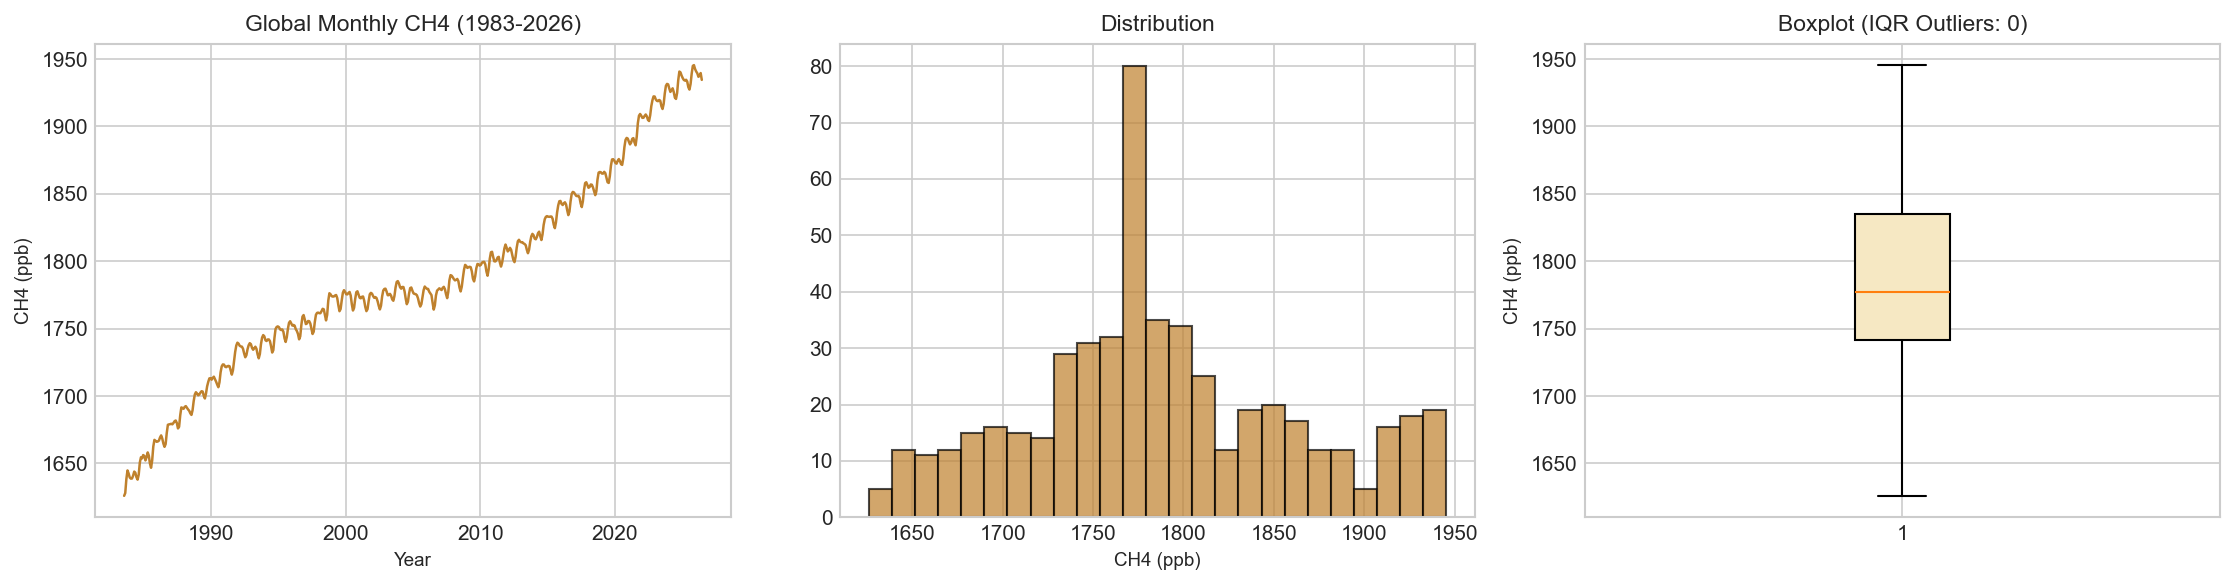

In [37]:
# 5. OUTLIERS & 6. UNIVARIATE: ch4_mm_gl.txt
s_ch4_mm, dom_inv, iqr_out = check_domain_outliers(df_ch4_mm, 'average', 600, 2100, name="NOAA Monthly CH4")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_ch4_mm['decimal'], df_ch4_mm['average'], color='#bf812d', lw=1.2)
axes[0].set_title("Global Monthly CH4 (1983-2026)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("CH4 (ppb)")

axes[1].hist(df_ch4_mm['average'], bins=25, color='#bf812d', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("CH4 (ppb)")

axes[2].boxplot(df_ch4_mm['average'], vert=True, patch_artist=True, boxprops=dict(facecolor='#f6e8c3'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("CH4 (ppb)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ch4_mm_gl_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

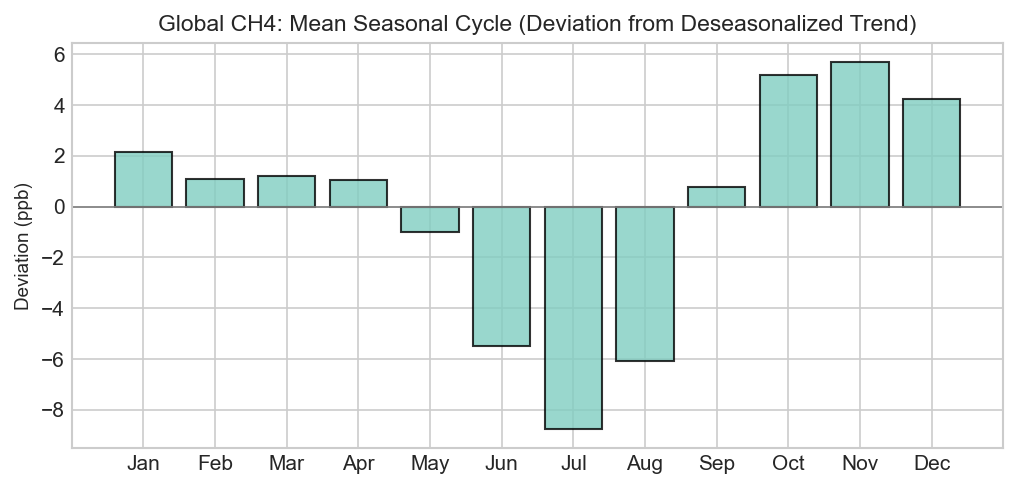

In [38]:
# 7. SEASONALITY: ch4_mm_gl.txt
df_ch4_mm['month_name'] = pd.to_datetime(df_ch4_mm['year'].astype(str) + '-' + df_ch4_mm['month'].astype(str) + '-01').dt.strftime('%b')
ch4_monthly_cycle = (df_ch4_mm['average'] - df_ch4_mm['trend']).groupby(df_ch4_mm['month']).mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(month_labels, ch4_monthly_cycle.values, color='#80cdc1', edgecolor='black', alpha=0.8)
ax.set_title("Global CH4: Mean Seasonal Cycle (Deviation from Deseasonalized Trend)")
ax.set_ylabel("Deviation (ppb)")
ax.axhline(0, color='gray', lw=0.8)
plt.savefig(os.path.join(FIG_DIR, "ch4_mm_gl_seasonality.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [39]:
# 8. PROFILING REPORT: ch4_mm_gl.txt
prof_ch4_mm = ProfileReport(df_ch4_mm, title="Raw Profile: ch4_mm_gl.txt", minimal=True, correlations=None, interactions=None)
prof_ch4_mm.to_file(os.path.join(PROFILE_DIR, "ch4_mm_gl.html"))
print(f"Profiling report saved to {PROFILE_DIR}/ch4_mm_gl.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/8 [00:00<?, ?it/s]

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 9502.81it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/ch4_mm_gl.html


### Finding: `ch4_mm_gl.txt`
- **File Structure:** 48 lines of comments, whitespace-delimited, 7 columns: `year`, `month`, `decimal`, `average`, `average_unc`, `trend`, `trend_unc`. 516 monthly rows from July 1983 to June 2026.
- **Sentinels:** `-9.99` appears 5 times in `average_unc` and `trend_unc` for the most recent provisional months (Feb–Jun 2026) where Monte Carlo uncertainty calculation is pending.
- **Seasonality:** Global CH4 exhibits a clear seasonal cycle of amplitude ~15 ppb with a minimum in summer (July–August, due to peak OH radical sink) peak in October–December, minimum July (about -8.7 ppb).
- **Recommendation:** Use `average` for monthly CH4 modeling; convert `-9.99` in uncertainty columns to `NaN`.


## 10. Raw File: `n2o_annmean_gl.txt` (NOAA Globally Averaged Annual Nitrous Oxide)
**Role:** Atmospheric nitrous oxide concentration (ppb) for annual dataset.  
**Source:** NOAA GML.

In [40]:
# 1. UNDERSTAND & LOAD: n2o_annmean_gl.txt
filepath_n2o_ann = os.path.join(RAW_DIR, "n2o_annmean_gl.txt")
print_raw_sample(filepath_n2o_ann, n_head=15, n_tail=5)

df_n2o_ann = pd.read_csv(filepath_n2o_ann, comment='#', sep=r'\s+', names=['year', 'mean', 'unc'])
print("\nShape:", df_n2o_ann.shape)
df_n2o_ann.info()
display(df_n2o_ann.head(3))
display(df_n2o_ann.tail(3))
display(df_n2o_ann.describe())

=== File: data/raw/n2o_annmean_gl.txt (Total Lines: 71) ===
--- First 15 Raw Lines ---
  1: # --------------------------------------------------------------------
  2: # USE OF NOAA GML DATA
  3: #
  4: # These data are made freely available to the public and the scientific
  5: # community in the belief that their wide dissemination will lead to
  6: # greater understanding and new scientific insights. To ensure that GML
  7: # receives fair credit for their work please include relevant citation
  8: # text in publications. We encourage users to contact the data providers,
  9: # who can provide detailed information about the measurements and
 10: # scientific insight.  In cases where the data are central to a
 11: # publication, coauthorship for data providers may be appropriate.
 12: #
 13: #
 14: #
 15: # Contact:  Xin Lan (xin.lan@noaa.gov)
--- Last 5 Raw Lines ---
 67:   2021   334.29     0.03
 68:   2022   335.63     0.03
 69:   2023   336.70     0.03
 70:   2024   337.72     0.

,year,mean,unc
0,2001,316.36,0.12
1,2002,316.94,0.13
2,2003,317.63,0.14


,year,mean,unc
22,2023,336.70,0.03
23,2024,337.72,0.02
24,2025,338.86,0.02


,year,mean,unc
count,25.000000,25.000000,25.000000
mean,2013.000000,326.537600,0.100800
std,7.359801,7.007459,0.040919
min,2001.000000,316.360000,0.020000
25%,2007.000000,320.440000,0.110000
50%,2013.000000,325.940000,0.120000
75%,2019.000000,331.880000,0.120000
max,2025.000000,338.860000,0.140000


Coverage: 2001 to 2025 (25 annual rows)
[NOAA Annual N2O] Summary:
  Count: 25, Mean: 326.538, Median: 325.940, Std: 7.007
  Min: 316.360, Max: 338.860
  Domain bounds [250, 360]: 0 violations
  IQR bounds [303.28, 349.04]: 0 flagged outliers


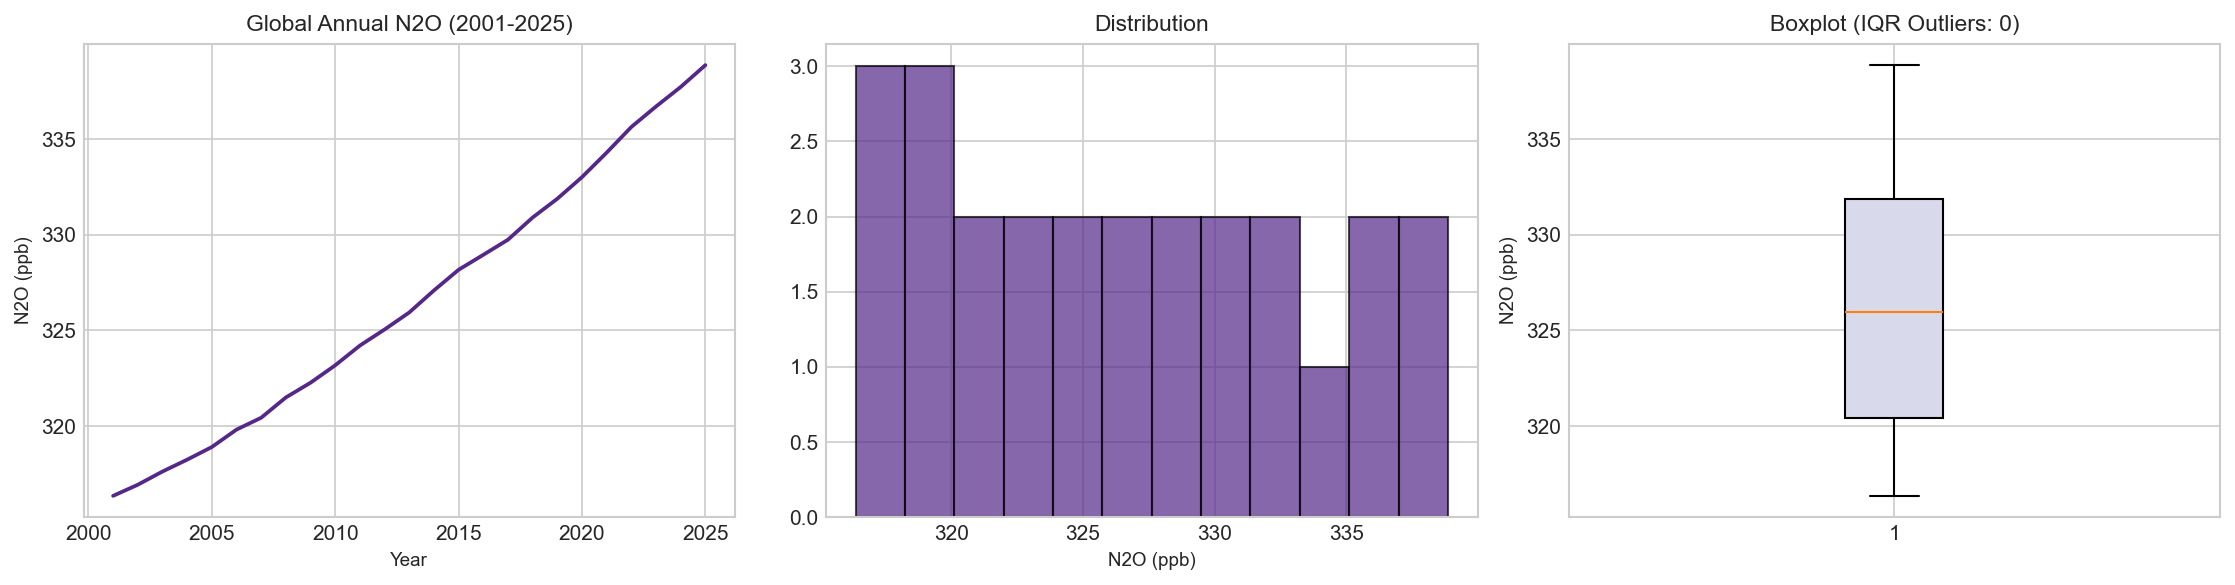

In [41]:
# 2. TIME COVERAGE & 5. OUTLIERS & 6. UNIVARIATE: n2o_annmean_gl.txt
print(f"Coverage: {df_n2o_ann['year'].min()} to {df_n2o_ann['year'].max()} ({len(df_n2o_ann)} annual rows)")
s_n2o_ann, dom_inv, iqr_out = check_domain_outliers(df_n2o_ann, 'mean', 250, 360, name="NOAA Annual N2O")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_n2o_ann['year'], df_n2o_ann['mean'], color='#542788', lw=1.8)
axes[0].set_title("Global Annual N2O (2001-2025)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("N2O (ppb)")

axes[1].hist(df_n2o_ann['mean'], bins=12, color='#542788', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("N2O (ppb)")

axes[2].boxplot(df_n2o_ann['mean'], vert=True, patch_artist=True, boxprops=dict(facecolor='#d8daeb'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("N2O (ppb)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "n2o_annmean_gl_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [42]:
# 8. PROFILING REPORT: n2o_annmean_gl.txt
prof_n2o_ann = ProfileReport(df_n2o_ann, title="Raw Profile: n2o_annmean_gl.txt", minimal=True, correlations=None, interactions=None)
prof_n2o_ann.to_file(os.path.join(PROFILE_DIR, "n2o_annmean_gl.html"))
print(f"Profiling report saved to {PROFILE_DIR}/n2o_annmean_gl.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/3 [00:00<?, ?it/s]

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:00<00:00, 47662.55it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/n2o_annmean_gl.html


### Finding: `n2o_annmean_gl.txt`
- **File Structure:** 46 lines of comment headers, whitespace-delimited, columns: `year`, `mean`, `unc`. 25 annual rows (2001 to 2025).
- **Completeness & Range:** 0 missing values, 0 sentinels. Rises steadily from 316.36 ppb (2001) to 338.86 ppb (2025), well within domain bounds [250, 360 ppb].
- **Limitation:** NOAA global network measurements only begin in 2001. Including annual N2O restricts complete dataset rows to 2001–2025 (25 rows).
- **Recommendation:** Use for modern annual models; keep separate in early historical periods to prevent row truncation.

## 11. Raw File: `n2o_mm_gl.txt` (NOAA Globally Averaged Monthly Nitrous Oxide)
**Role:** Atmospheric nitrous oxide concentration (ppb) for monthly dataset.  
**Source:** NOAA GML.

In [43]:
# 1. UNDERSTAND & LOAD: n2o_mm_gl.txt
filepath_n2o_mm = os.path.join(RAW_DIR, "n2o_mm_gl.txt")
print_raw_sample(filepath_n2o_mm, n_head=15, n_tail=5)

n2o_mm_cols = ['year', 'month', 'decimal', 'average', 'average_unc', 'trend', 'trend_unc']
df_n2o_mm = pd.read_csv(filepath_n2o_mm, comment='#', sep=r'\s+', names=n2o_mm_cols)
print("\nShape:", df_n2o_mm.shape)
df_n2o_mm.info()
display(df_n2o_mm.head(3))
display(df_n2o_mm.tail(3))
display(df_n2o_mm.describe())

=== File: data/raw/n2o_mm_gl.txt (Total Lines: 354) ===
--- First 15 Raw Lines ---
  1: # --------------------------------------------------------------------
  2: # USE OF NOAA GML DATA
  3: #
  4: # These data are made freely available to the public and the scientific
  5: # community in the belief that their wide dissemination will lead to
  6: # greater understanding and new scientific insights. To ensure that GML
  7: # receives fair credit for their work please include relevant citation
  8: # text in publications. We encourage users to contact the data providers,
  9: # who can provide detailed information about the measurements and
 10: # scientific insight.  In cases where the data are central to a
 11: # publication, coauthorship for data providers may be appropriate.
 12: #
 13: #
 14: #
 15: # Contact:  Xin Lan (xin.lan@noaa.gov)
--- Last 5 Raw Lines ---
350:   2026       2      2026.125        339.76         -9.99        339.62         -9.99
351:   2026       3      2026.2

,year,month,decimal,average,average_unc,trend,trend_unc
0,2001,1,2001.042,316.30,0.14,316.03,0.13
1,2001,2,2001.125,316.31,0.15,316.09,0.13
2,2001,3,2001.208,316.21,0.14,316.15,0.13


,year,month,decimal,average,average_unc,trend,trend_unc
303,2026,4,2026.292,339.79,-9.99,339.80,-9.99
304,2026,5,2026.375,339.83,-9.99,339.90,-9.99
305,2026,6,2026.458,339.86,-9.99,339.99,-9.99


,year,month,decimal,average,average_unc,trend,trend_unc
count,306.000000,306.000000,306.000000,306.000000,306.000000,306.000000,306.000000
mean,2013.254902,6.441176,2013.750000,326.806503,-0.050523,326.804346,-0.060458
std,7.376106,3.457205,7.373232,7.060871,1.283937,7.058949,1.282581
min,2001.000000,1.000000,2001.042000,316.110000,-9.990000,316.030000,-9.990000
25%,2007.000000,3.000000,2007.395750,320.272500,0.120000,320.347500,0.100000
50%,2013.000000,6.000000,2013.750000,326.125000,0.130000,326.185000,0.120000
75%,2020.000000,9.000000,2020.104250,332.547500,0.140000,332.495000,0.130000
max,2026.000000,12.000000,2026.458000,339.860000,0.170000,339.990000,0.160000


In [44]:
# 2. TIME COVERAGE & 3. MISSING SENTINELS: n2o_mm_gl.txt
print(f"Coverage: {df_n2o_mm['year'].iloc[0]}-{df_n2o_mm['month'].iloc[0]:02d} to {df_n2o_mm['year'].iloc[-1]}-{df_n2o_mm['month'].iloc[-1]:02d} ({len(df_n2o_mm)} months)")
print(f"average_unc == -9.99: {(df_n2o_mm['average_unc'] == -9.99).sum()} (provisional recent months: 2026-02 to 2026-06)")
print(f"trend_unc == -9.99: {(df_n2o_mm['trend_unc'] == -9.99).sum()}")

Coverage: 2001-01 to 2026-06 (306 months)
average_unc == -9.99: 5 (provisional recent months: 2026-02 to 2026-06)
trend_unc == -9.99: 5


[NOAA Monthly N2O] Summary:
  Count: 306, Mean: 326.807, Median: 326.125, Std: 7.061
  Min: 316.110, Max: 339.860
  Domain bounds [250, 360]: 0 violations
  IQR bounds [301.86, 350.96]: 0 flagged outliers


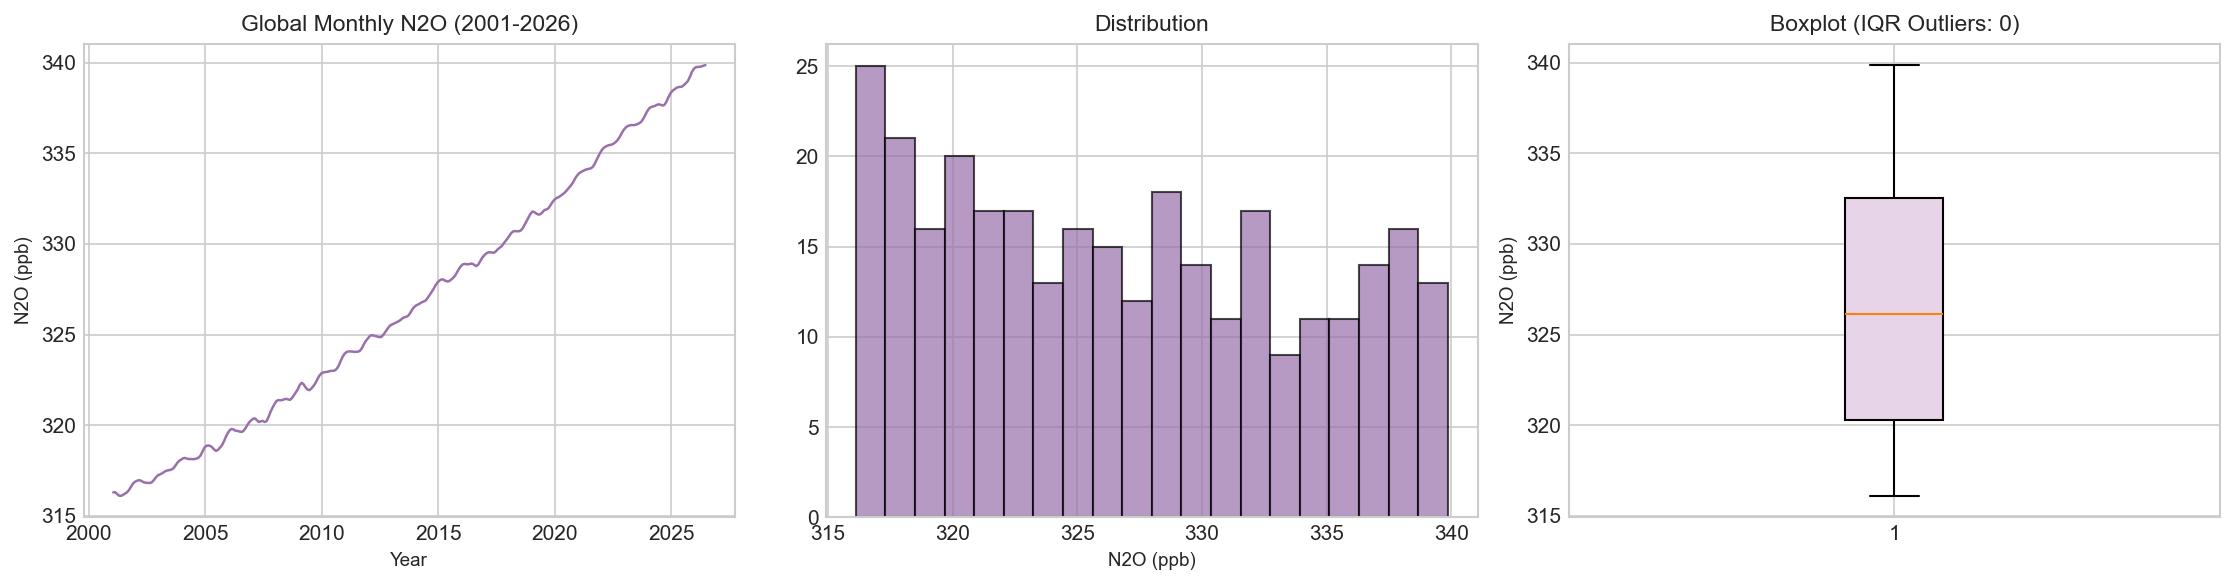

In [45]:
# 5. OUTLIERS & 6. UNIVARIATE: n2o_mm_gl.txt
s_n2o_mm, dom_inv, iqr_out = check_domain_outliers(df_n2o_mm, 'average', 250, 360, name="NOAA Monthly N2O")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(df_n2o_mm['decimal'], df_n2o_mm['average'], color='#9970ab', lw=1.2)
axes[0].set_title("Global Monthly N2O (2001-2026)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("N2O (ppb)")

axes[1].hist(df_n2o_mm['average'], bins=20, color='#9970ab', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("N2O (ppb)")

axes[2].boxplot(df_n2o_mm['average'], vert=True, patch_artist=True, boxprops=dict(facecolor='#e7d4e8'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("N2O (ppb)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "n2o_mm_gl_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

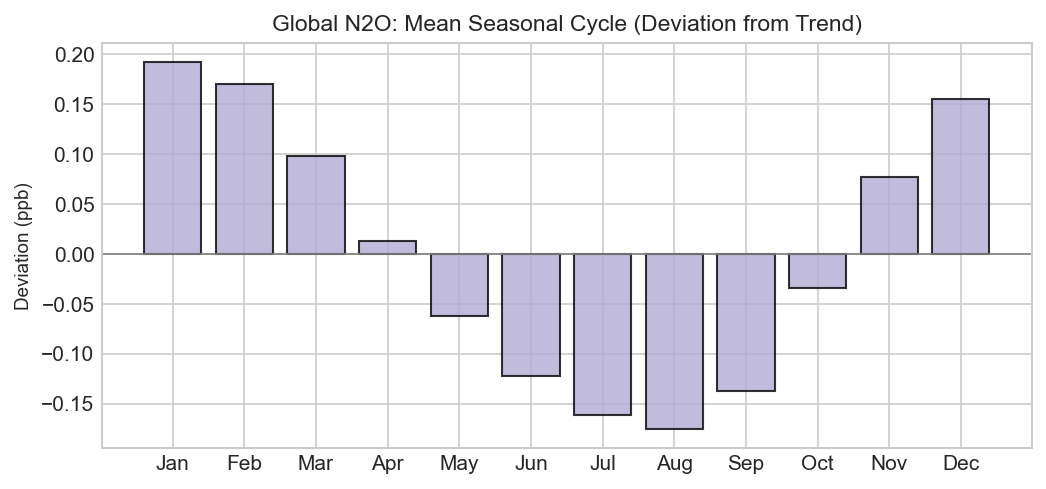

In [46]:
# 7. SEASONALITY: n2o_mm_gl.txt
n2o_monthly_cycle = (df_n2o_mm['average'] - df_n2o_mm['trend']).groupby(df_n2o_mm['month']).mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(month_labels, n2o_monthly_cycle.values, color='#b2abd2', edgecolor='black', alpha=0.8)
ax.set_title("Global N2O: Mean Seasonal Cycle (Deviation from Trend)")
ax.set_ylabel("Deviation (ppb)")
ax.axhline(0, color='gray', lw=0.8)
plt.savefig(os.path.join(FIG_DIR, "n2o_mm_gl_seasonality.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [47]:
# 8. PROFILING REPORT: n2o_mm_gl.txt
prof_n2o_mm = ProfileReport(df_n2o_mm, title="Raw Profile: n2o_mm_gl.txt", minimal=True, correlations=None, interactions=None)
prof_n2o_mm.to_file(os.path.join(PROFILE_DIR, "n2o_mm_gl.html"))
print(f"Profiling report saved to {PROFILE_DIR}/n2o_mm_gl.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/7 [00:00<?, ?it/s]

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:00<00:00, 123361.88it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/n2o_mm_gl.html


### Finding: `n2o_mm_gl.txt`
- **File Structure:** 48 comment lines, whitespace-delimited, 7 columns: `year`, `month`, `decimal`, `average`, `average_unc`, `trend`, `trend_unc`. 306 monthly rows from January 2001 to June 2026.
- **Sentinels:** `-9.99` in uncertainty columns for 5 provisional months (Feb–Jun 2026).
- **Seasonality:** Subtle seasonal cycle: about +/-0.18 ppb, highest in January, lowest in August.
- **Recommendation:** Use `average` for monthly modeling; convert `-9.99` sentinels to `NaN`.


## 12. Raw File: `ghg-concentrations_fig-2.csv` (EPA Methane Concentrations Fig-2)
**Role:** Multi-source compilation of methane datasets (ice cores and individual observational stations).  
**Source:** EPA Climate Change Indicators / NOAA / CSIRO.

In [48]:
# 1. UNDERSTAND & LOAD: ghg-concentrations_fig-2.csv
filepath_epa_m = os.path.join(RAW_DIR, "ghg-concentrations_fig-2.csv")
print_raw_sample(filepath_epa_m, n_head=15, n_tail=5)

# Load uncleaned
df_epa_m = pd.read_csv(filepath_epa_m, skiprows=6)
print("\nShape:", df_epa_m.shape)
df_epa_m.info()
display(df_epa_m.head(4))
display(df_epa_m.tail(3))
display(df_epa_m.describe(include='all'))

=== File: data/raw/ghg-concentrations_fig-2.csv (Total Lines: 2225) ===
--- First 15 Raw Lines ---
  1: Figure 2. Global Atmospheric Concentrations of Methane Over Time,,,,,
  2: Source: EPA's Climate Change Indicators in the United States: www.epa.gov/climate-indicators,,,,,
  3: Data source: Compilation of five underlying datasets,,,,,
  4: Web update: June 2024,,,,,
  5: Units: parts per billion (ppb) of methane,,,,,
  6: ,,,,,
  7: Year (negative values = BC),"EPICA Dome C, Antarctica",Law Dome,"Cape Grim, Australia","Mauna Loa, Hawaii","Shetland Islands, Scotland"
  8: Ice core measurements,,,,,
  9: -797446.1,399.3,,,,
 10: -796467.4,457.8,,,,
 11: -795327,396.1,,,,
 12: -794369.7,418,,,,
 13: -792988,428.3,,,,
 14: -792449.6,419.6666667,,,,
 15: -791645.5,451.2,,,,
--- Last 5 Raw Lines ---
2221: 2019,,,"1,816.10","1,882.56",
2222: 2020,,,"1,824.34","1,891.41",
2223: 2021,,,"1,841.22","1,912.32",
2224: 2022,,,"1,858.79","1,929.05",
2225: 2023,,,"1,872.04",,

Shape: (2218, 6)
<cla

,Year (negative values = BC),"EPICA Dome C, Antarctica",Law Dome,"Cape Grim, Australia","Mauna Loa, Hawaii","Shetland Islands, Scotland"
0,Ice core measurements,NaN,NaN,NaN,NaN,NaN
1,-797446.1,399.3,NaN,NaN,NaN,NaN
2,-796467.4,457.8,NaN,NaN,NaN,NaN
3,-795327,396.1,NaN,NaN,NaN,NaN


,Year (negative values = BC),"EPICA Dome C, Antarctica",Law Dome,"Cape Grim, Australia","Mauna Loa, Hawaii","Shetland Islands, Scotland"
2215,2021,NaN,NaN,"1,841.22","1,912.32",NaN
2216,2022,NaN,NaN,"1,858.79","1,929.05",NaN
2217,2023,NaN,NaN,"1,872.04",NaN,NaN


,Year (negative values = BC),"EPICA Dome C, Antarctica",Law Dome,"Cape Grim, Australia","Mauna Loa, Hawaii","Shetland Islands, Scotland"
count,2218,2103.000000,72,40,40,9
unique,2218,NaN,72,40,40,9
top,Ice core measurements,NaN,666,0,0,"1,786.67"
freq,1,NaN,1,1,1,1
mean,NaN,519.952278,NaN,NaN,NaN,NaN
std,NaN,88.056229,NaN,NaN,NaN,NaN
min,NaN,342.400000,NaN,NaN,NaN,NaN
25%,NaN,449.850000,NaN,NaN,NaN,NaN
50%,NaN,508.666667,NaN,NaN,NaN,NaN
75%,NaN,589.395389,NaN,NaN,NaN,NaN


In [49]:
# 2. COVERAGE & 4. MALFORMED ROWS: ghg-concentrations_fig-2.csv
# Inspect row 0
print(f"Row 0 content: {df_epa_m.iloc[0].to_dict()}")

# Filter text row and inspect columns
df_epa_m_clean = df_epa_m.iloc[1:].copy()
df_epa_m_clean['Year'] = pd.to_numeric(df_epa_m_clean['Year (negative values = BC)'], errors='coerce')

for col in df_epa_m_clean.columns:
    if col not in ['Year (negative values = BC)', 'Year']:
        clean_s = df_epa_m_clean[col].astype(str).str.replace(',', '')
        num_s = pd.to_numeric(clean_s, errors='coerce')
        valid = df_epa_m_clean.loc[num_s.notnull(), 'Year']
        if len(valid) > 0:
            print(f"Column [{col}]: {len(valid)} points, Year range: {valid.min():.1f} to {valid.max():.1f}")
        else:
            print(f"Column [{col}]: 0 valid points")

Row 0 content: {'Year (negative values = BC)': 'Ice core measurements', 'EPICA Dome C, Antarctica': nan, 'Law Dome': nan, 'Cape Grim, Australia': nan, 'Mauna Loa, Hawaii': nan, 'Shetland Islands, Scotland': nan}
Column [EPICA Dome C, Antarctica]: 2103 points, Year range: -797446.1 to 1936.6
Column [Law Dome]: 72 points, Year range: 1008.0 to 1980.0
Column [Cape Grim, Australia]: 40 points, Year range: 1984.0 to 2023.0
Column [Mauna Loa, Hawaii]: 40 points, Year range: 1983.0 to 2022.0
Column [Shetland Islands, Scotland]: 9 points, Year range: 1993.0 to 2001.0


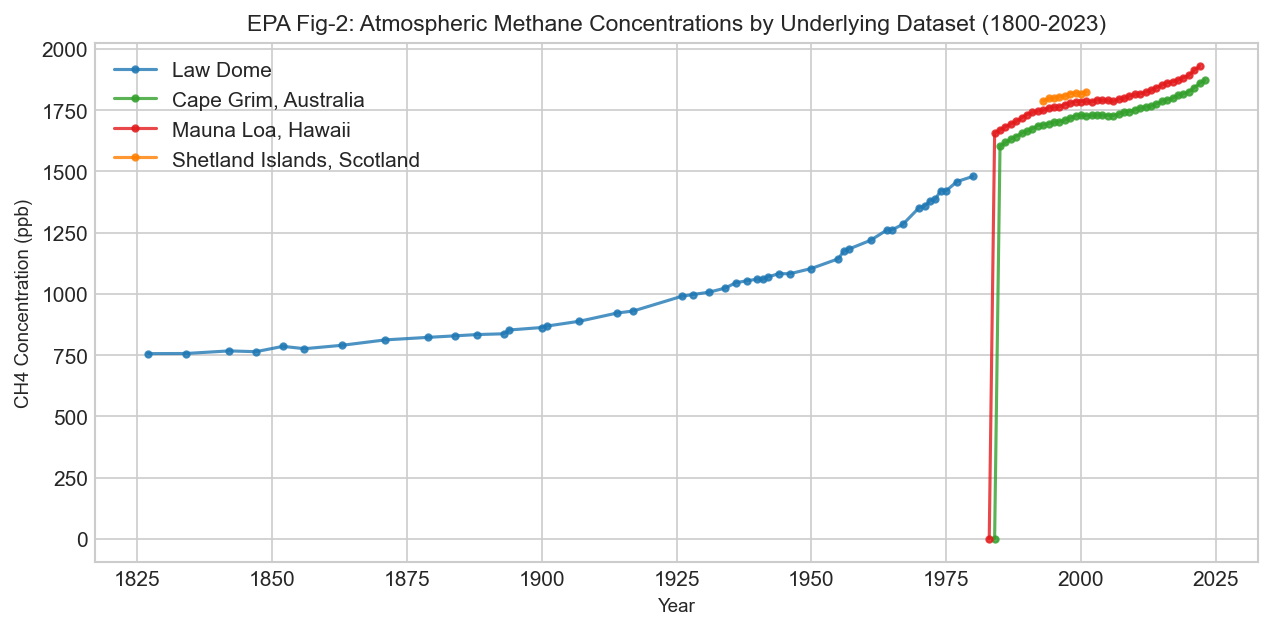

In [50]:
# 6. MULTI-SOURCE VISUALIZATION: ghg-concentrations_fig-2.csv
fig, ax = plt.subplots(figsize=(10, 4.5))
for col, color in [('Law Dome', '#1f78b4'), ('Cape Grim, Australia', '#33a02c'), ('Mauna Loa, Hawaii', '#e31a1c'), ('Shetland Islands, Scotland', '#ff7f00')]:
    clean_s = df_epa_m_clean[col].astype(str).str.replace(',', '')
    num_s = pd.to_numeric(clean_s, errors='coerce')
    sub = df_epa_m_clean[num_s.notnull() & (df_epa_m_clean['Year'] >= 1800)]
    ax.plot(sub['Year'], num_s.loc[sub.index], marker='.', ls='-', label=col, color=color, alpha=0.8)

ax.set_title("EPA Fig-2: Atmospheric Methane Concentrations by Underlying Dataset (1800-2023)")
ax.set_xlabel("Year")
ax.set_ylabel("CH4 Concentration (ppb)")
ax.legend()
plt.savefig(os.path.join(FIG_DIR, "epa_methane_sources.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [51]:
# 8. PROFILING REPORT: ghg-concentrations_fig-2.csv
prof_epa_m = ProfileReport(df_epa_m, title="Raw Profile: ghg-concentrations_fig-2.csv", minimal=True, correlations=None, interactions=None)
prof_epa_m.to_file(os.path.join(PROFILE_DIR, "ghg-concentrations_fig-2.html"))
print(f"Profiling report saved to {PROFILE_DIR}/ghg-concentrations_fig-2.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/6 [00:00<?, ?it/s]

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 1145.20it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/ghg-concentrations_fig-2.html


### Finding: `ghg-concentrations_fig-2.csv`
- **File Structure:** 6 lines of metadata, followed by header row and 2218 rows.
- **Malformed Header Row:** Row 0 contains `'Ice core measurements'` as section text in the first column, causing the entire column to parse as object dtype.
- **Format Inconsistency & Bad Values:** Values in columns like `Law Dome` and `Mauna Loa` contain comma thousands separators (e.g. `'1,816.10'`). Crucially, the first observations for Cape Grim (1984) and Mauna Loa (1983) are literal `0` ppb (bad/uncalibrated values where the plot drops to 0); standard range checks missed them when read as raw strings.
- **Dataset Structure:** This is not a single spliced time series; it contains five separate columns representing individual stations or ice cores with large time gaps.
- **Splice Assessment:** Law Dome ends near 1480 ppb in 1980 while modern stations start near 1600-1650 ppb in 1983-84. Methane grows only about 10-15 ppb per year, so this ~150 ppb jump is mostly a source offset, not real growth.
- **Updated Recommendation:** Do NOT splice Law Dome to NOAA; use official NOAA CH4 (1984+) only for continuous modeling.


## 13. Raw File: `ghg-concentrations_fig-3.csv` (EPA Nitrous Oxide Concentrations Fig-3)
**Role:** Multi-source compilation of nitrous oxide datasets.  
**Source:** EPA Climate Change Indicators.

In [52]:
# 1. UNDERSTAND & LOAD: ghg-concentrations_fig-3.csv
filepath_epa_n = os.path.join(RAW_DIR, "ghg-concentrations_fig-3.csv")
print_raw_sample(filepath_epa_n, n_head=15, n_tail=5)

df_epa_n = pd.read_csv(filepath_epa_n, skiprows=6)
print("\nShape:", df_epa_n.shape)
df_epa_n.info()
display(df_epa_n.head(3))
display(df_epa_n.tail(3))
display(df_epa_n.describe(include='all'))

=== File: data/raw/ghg-concentrations_fig-3.csv (Total Lines: 965) ===
--- First 15 Raw Lines ---
  1: Figure 3. Global Atmospheric Concentrations of Nitrous Oxide Over Time,,,,,,
  2: Source: EPA's Climate Change Indicators in the United States: www.epa.gov/climate-indicators,,,,,,
  3: Data source: Compilation of six underlying datasets,,,,,,
  4: Web update: June 2024,,,,,,
  5: Units: parts per billion (ppb) of nitrous oxide,,,,,,
  6: ,,,,,,
  7: Year (negative values = BC),"EPICA Dome C, Antarctica",Antarctica (Battle et al.),"Cape Grim, Australia","Mauna Loa, Hawaii","South Pole, Antarctica","Barrow, Alaska"
  8: -796475,254,,,,,
  9: -794430,248.8,,,,,
 10: -792569,238.7,,,,,
 11: -790916,238.7,,,,,
 12: -789474,249.7,,,,,
 13: -788110,253.3,,,,,
 14: -786882,252.7,,,,,
 15: -785730,266.3,,,,,
--- Last 5 Raw Lines ---
961: 2019,,,330.9260833,,331.25,332.3216667
962: 2020,,,331.8645833,333.9258333,332.2466667,333.785
963: 2021,,,333.3766667,335.1133333,333.8033333,334.8216667
96

,Year (negative values = BC),"EPICA Dome C, Antarctica",Antarctica (Battle et al.),"Cape Grim, Australia","Mauna Loa, Hawaii","South Pole, Antarctica","Barrow, Alaska"
0,-796475,254.0,NaN,NaN,NaN,NaN,NaN
1,-794430,248.8,NaN,NaN,NaN,NaN,NaN
2,-792569,238.7,NaN,NaN,NaN,NaN,NaN


,Year (negative values = BC),"EPICA Dome C, Antarctica",Antarctica (Battle et al.),"Cape Grim, Australia","Mauna Loa, Hawaii","South Pole, Antarctica","Barrow, Alaska"
955,2021,NaN,NaN,333.376667,335.113333,333.803333,334.821667
956,2022,NaN,NaN,334.909333,336.761818,335.091818,336.048333
957,2023,NaN,NaN,NaN,NaN,336.067500,336.995833


,Year (negative values = BC),"EPICA Dome C, Antarctica",Antarctica (Battle et al.),"Cape Grim, Australia","Mauna Loa, Hawaii","South Pole, Antarctica","Barrow, Alaska"
count,958.000000,912.000000,0.0,44.000000,21.000000,24.000000,42.000000
mean,-292815.408142,253.037939,NaN,315.717671,325.284701,324.078131,316.614045
std,263404.997590,19.983132,NaN,9.973424,6.068647,6.948931,11.059201
min,-796475.000000,185.500000,NaN,300.172167,316.079167,312.859167,300.172167
25%,-526194.250000,240.225000,NaN,307.805688,320.431667,318.014375,307.305729
50%,-238539.500000,256.300000,NaN,315.104167,324.760000,323.902917,316.477500
75%,-30587.250000,267.300000,NaN,323.578063,329.487500,329.446458,325.367292
max,2023.000000,303.300000,NaN,334.909333,336.761818,336.067500,336.995833


In [53]:
# 2. TIME COVERAGE & 3. MISSING COLUMNS: ghg-concentrations_fig-3.csv
df_epa_n['Year'] = pd.to_numeric(df_epa_n['Year (negative values = BC)'], errors='coerce')

for col in df_epa_n.columns:
    if col not in ['Year (negative values = BC)', 'Year']:
        num_s = pd.to_numeric(df_epa_n[col], errors='coerce')
        valid = df_epa_n.loc[num_s.notnull(), 'Year']
        if len(valid) > 0:
            print(f"Column [{col}]: {len(valid)} points, Year range: {valid.min():.0f} to {valid.max():.0f}")
        else:
            print(f"Column [{col}]: 0 valid points (100% EMPTY)")

Column [EPICA Dome C, Antarctica]: 912 points, Year range: -796475 to 1937
Column [Antarctica (Battle et al.)]: 0 valid points (100% EMPTY)
Column [Cape Grim, Australia]: 44 points, Year range: 1979 to 2022
Column [Mauna Loa, Hawaii]: 21 points, Year range: 2000 to 2022
Column [South Pole, Antarctica]: 24 points, Year range: 1998 to 2023
Column [Barrow, Alaska]: 42 points, Year range: 1979 to 2023


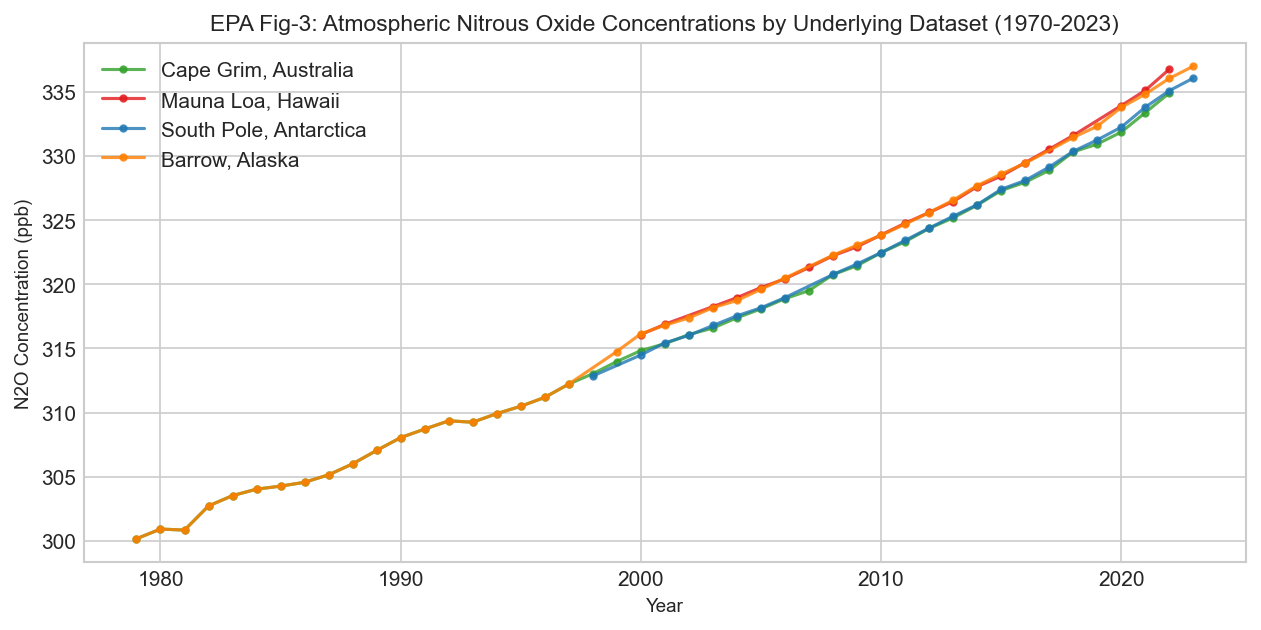

In [54]:
# 6. MULTI-SOURCE VISUALIZATION: ghg-concentrations_fig-3.csv
fig, ax = plt.subplots(figsize=(10, 4.5))
for col, color in [('Cape Grim, Australia', '#33a02c'), ('Mauna Loa, Hawaii', '#e31a1c'), ('South Pole, Antarctica', '#1f78b4'), ('Barrow, Alaska', '#ff7f00')]:
    num_s = pd.to_numeric(df_epa_n[col], errors='coerce')
    sub = df_epa_n[num_s.notnull() & (df_epa_n['Year'] >= 1970)]
    ax.plot(sub['Year'], num_s.loc[sub.index], marker='o', markersize=3, ls='-', label=col, color=color, alpha=0.8)

ax.set_title("EPA Fig-3: Atmospheric Nitrous Oxide Concentrations by Underlying Dataset (1970-2023)")
ax.set_xlabel("Year")
ax.set_ylabel("N2O Concentration (ppb)")
ax.legend()
plt.savefig(os.path.join(FIG_DIR, "epa_n2o_sources.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [55]:
# 8. PROFILING REPORT: ghg-concentrations_fig-3.csv
prof_epa_n = ProfileReport(df_epa_n, title="Raw Profile: ghg-concentrations_fig-3.csv", minimal=True, correlations=None, interactions=None)
prof_epa_n.to_file(os.path.join(PROFILE_DIR, "ghg-concentrations_fig-3.html"))
print(f"Profiling report saved to {PROFILE_DIR}/ghg-concentrations_fig-3.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/8 [00:00<?, ?it/s]

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:00<00:00, 153919.41it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/ghg-concentrations_fig-3.html


### Finding: `ghg-concentrations_fig-3.csv`
- **File Structure:** 6 lines of metadata, header row, 958 rows.
- **Empty Column:** Column `Antarctica (Battle et al.)` contains 0 non-null values across the entire file (100% missing).
- **Critical Temporal Gap:** Ice core measurements (`EPICA Dome C`) terminate in 1937, while modern instrumental stations (`Cape Grim`, `Barrow`) begin in 1979. There is a complete 41-year data gap (1938–1978) with zero observations across all columns.
- **Recommendation:** Do not use as primary continuous series; drop the empty column `Antarctica (Battle et al.)`. Prefer NOAA global series for modeling.


## 14. Raw File: `global-atmospheric-co2-concentration.csv` (OWID Atmospheric CO2)
**Role:** Investigating potential duplicate/redundant atmospheric CO2 dataset.  
**Source:** Our World in Data (OWID) / NOAA.

In [56]:
# 1. UNDERSTAND & LOAD: global-atmospheric-co2-concentration.csv
filepath_owid = os.path.join(RAW_DIR, "global-atmospheric-co2-concentration.csv")
print_raw_sample(filepath_owid, n_head=15, n_tail=5)

df_owid = pd.read_csv(filepath_owid)
print("\nShape:", df_owid.shape)
df_owid.info()
display(df_owid.head(3))
display(df_owid.tail(3))
display(df_owid.describe())

=== File: data/raw/global-atmospheric-co2-concentration.csv (Total Lines: 571) ===
--- First 15 Raw Lines ---
  1: Entity,Code,Month,Monthly average,Annual average
  2: World,OWID_WRL,1979-01,336.56,
  3: World,OWID_WRL,1979-02,337.29,
  4: World,OWID_WRL,1979-03,337.88,
  5: World,OWID_WRL,1979-04,338.32,
  6: World,OWID_WRL,1979-05,338.26,
  7: World,OWID_WRL,1979-06,337.38,
  8: World,OWID_WRL,1979-07,335.56,
  9: World,OWID_WRL,1979-08,334.36,
 10: World,OWID_WRL,1979-09,335.02,
 11: World,OWID_WRL,1979-10,336.36,
 12: World,OWID_WRL,1979-11,337.36,
 13: World,OWID_WRL,1979-12,337.89,336.85333
 14: World,OWID_WRL,1980-01,338.58,337.02167
 15: World,OWID_WRL,1980-02,339.26,337.18582
--- Last 5 Raw Lines ---
567: World,OWID_WRL,2026-02,428.44,425.955
568: World,OWID_WRL,2026-03,428.48,426.10666
569: World,OWID_WRL,2026-04,428.67,426.24335
570: World,OWID_WRL,2026-05,428.59,426.3725
571: World,OWID_WRL,2026-06,427.62,426.51584

Shape: (570, 5)
<class 'pandas.core.frame.DataFrame'>
Ran

,Entity,Code,Month,Monthly average,Annual average
0,World,OWID_WRL,1979-01,336.56,NaN
1,World,OWID_WRL,1979-02,337.29,NaN
2,World,OWID_WRL,1979-03,337.88,NaN


,Entity,Code,Month,Monthly average,Annual average
567,World,OWID_WRL,2026-04,428.67,426.24335
568,World,OWID_WRL,2026-05,428.59,426.37250
569,World,OWID_WRL,2026-06,427.62,426.51584


,Monthly average,Annual average
count,570.000000,559.000000
mean,376.485789,376.369994
std,26.243190,25.657334
min,334.360000,336.853330
25%,354.442500,355.049170
50%,373.185000,373.210000
75%,397.667500,397.101675
max,428.670000,426.515840


In [57]:
# 2. TIME COVERAGE & 3. MISSING: global-atmospheric-co2-concentration.csv
print(f"Time Coverage: {df_owid['Month'].iloc[0]} to {df_owid['Month'].iloc[-1]} ({len(df_owid)} monthly rows)")
print(f"Standard nulls:\n{df_owid.isnull().sum()}")

# Inspect 'Annual average' structure
print("\nFirst 14 values of 'Annual average':")
display(df_owid[['Month', 'Monthly average', 'Annual average']].head(14))

Time Coverage: 1979-01 to 2026-06 (570 monthly rows)
Standard nulls:
Entity              0
Code                0
Month               0
Monthly average     0
Annual average     11
dtype: int64

First 14 values of 'Annual average':


,Month,Monthly average,Annual average
0,1979-01,336.56,NaN
1,1979-02,337.29,NaN
2,1979-03,337.88,NaN
3,1979-04,338.32,NaN
4,1979-05,338.26,NaN
5,1979-06,337.38,NaN
6,1979-07,335.56,NaN
7,1979-08,334.36,NaN
8,1979-09,335.02,NaN
9,1979-10,336.36,NaN


[OWID Monthly CO2] Summary:
  Count: 570, Mean: 376.486, Median: 373.185, Std: 26.243
  Min: 334.360, Max: 428.670
  Domain bounds [250, 500]: 0 violations
  IQR bounds [289.60, 462.51]: 0 flagged outliers


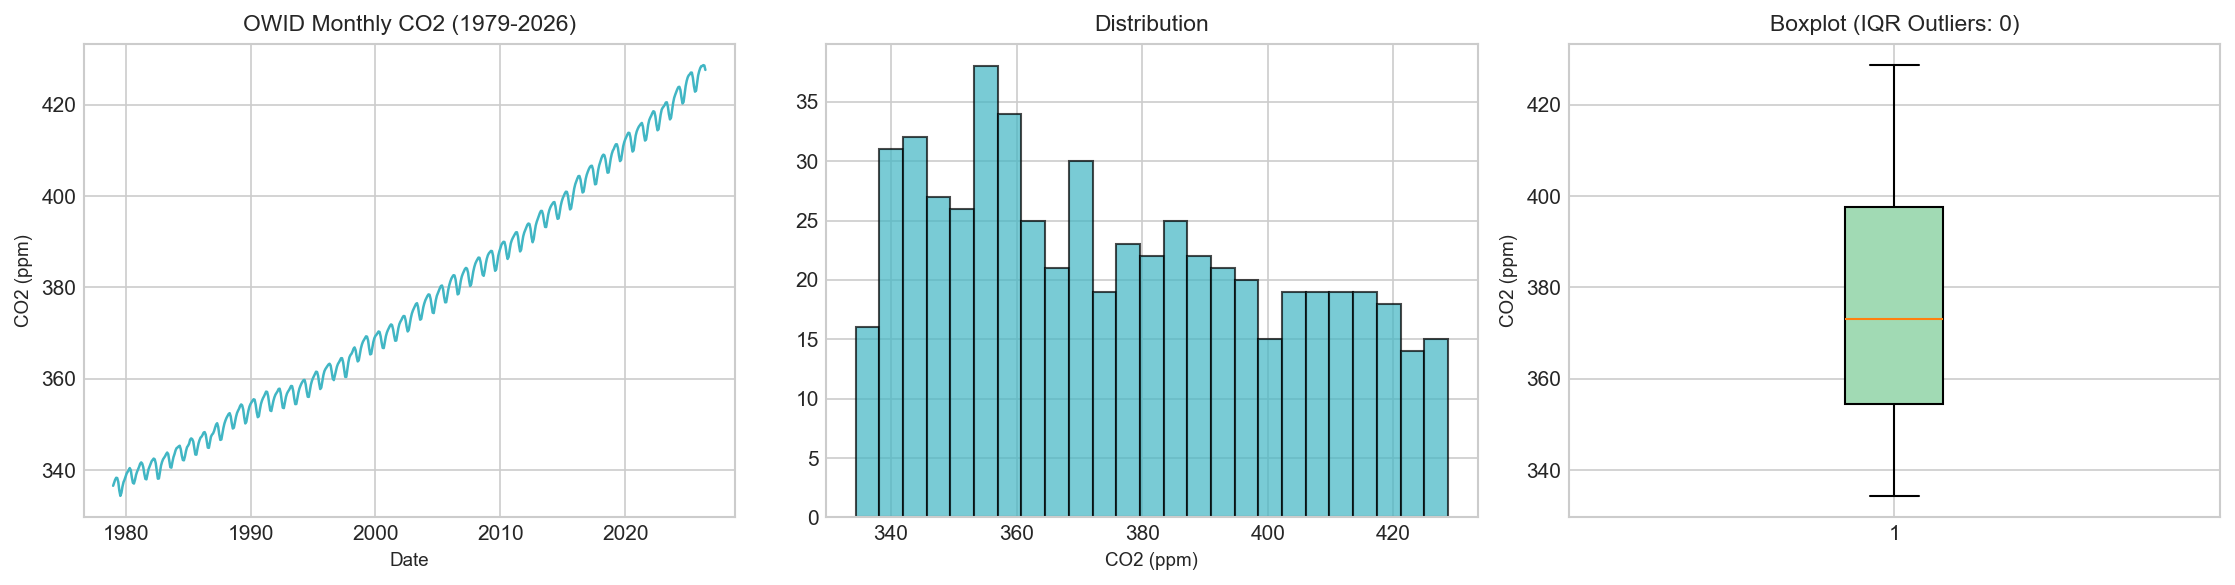

In [58]:
# 5. OUTLIERS & 6. UNIVARIATE: global-atmospheric-co2-concentration.csv
s_owid, dom_inv, iqr_out = check_domain_outliers(df_owid, 'Monthly average', 250, 500, name="OWID Monthly CO2")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(pd.to_datetime(df_owid['Month']), df_owid['Monthly average'], color='#41b6c4', lw=1.2)
axes[0].set_title("OWID Monthly CO2 (1979-2026)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("CO2 (ppm)")

axes[1].hist(df_owid['Monthly average'], bins=25, color='#41b6c4', edgecolor='black', alpha=0.7)
axes[1].set_title("Distribution")
axes[1].set_xlabel("CO2 (ppm)")

axes[2].boxplot(df_owid['Monthly average'], vert=True, patch_artist=True, boxprops=dict(facecolor='#a1dab4'))
axes[2].set_title(f"Boxplot (IQR Outliers: {len(iqr_out)})")
axes[2].set_ylabel("CO2 (ppm)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "owid_co2_univariate.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [59]:
# 8. PROFILING REPORT: global-atmospheric-co2-concentration.csv
prof_owid = ProfileReport(df_owid, title="Raw Profile: global-atmospheric-co2-concentration.csv", minimal=True, correlations=None, interactions=None)
prof_owid.to_file(os.path.join(PROFILE_DIR, "global-atmospheric-co2-concentration.html"))
print(f"Profiling report saved to {PROFILE_DIR}/global-atmospheric-co2-concentration.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|                                                                                                                                                                       | 0/5 [00:00<?, ?it/s]

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 1241.87it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to reports/profiling/raw/global-atmospheric-co2-concentration.html


### Finding: `global-atmospheric-co2-concentration.csv`
- **File Structure:** Standard CSV with columns `Entity`, `Code`, `Month`, `Monthly average`, `Annual average`. 570 monthly rows (1979-01 to 2026-06).
- **Structure of 'Annual average':** The column is not a calendar-year average; it is a 12-month trailing rolling mean (hence the first 11 months are null, and every subsequent month has an entry).
- **Redundancy:** This file is a derivative product from NOAA's Global Marine Boundary Layer network. It only begins in 1979 (21 years after Mauna Loa starts in 1958).
- **Recommendation:** Classified as **redundant**. Modern Mauna Loa (`co2_mm_mlo.txt` / `co2_annmean_mlo.txt`) provides superior historical reach (1958–present) and is the gold standard for climate research.

# Cross-File Analysis
## 9. Overlap and Redundancy Analysis
Rigorous numerical and graphical comparison across overlapping periods:
1. Ice-core CO2 (`smoothedco2.txt`) vs Mauna Loa CO2 (`co2_annmean_mlo.txt`)
2. GISTEMP Annual J-D vs the mean of its 12 monthly columns
3. Annual means of monthly files vs standalone annual files (CO2, CH4, N2O)
4. OWID CO2 vs Mauna Loa CO2
5. EPA Station series vs NOAA Globally Averaged series

=== ICE CORE vs MAUNA LOA CO2 OVERLAP (1959-2004, 46 Years) ===
Mean Difference (Ice Core - MLO): -2.424 ppm
Standard Deviation of Difference: 1.223 ppm
Max Absolute Difference:          4.770 ppm


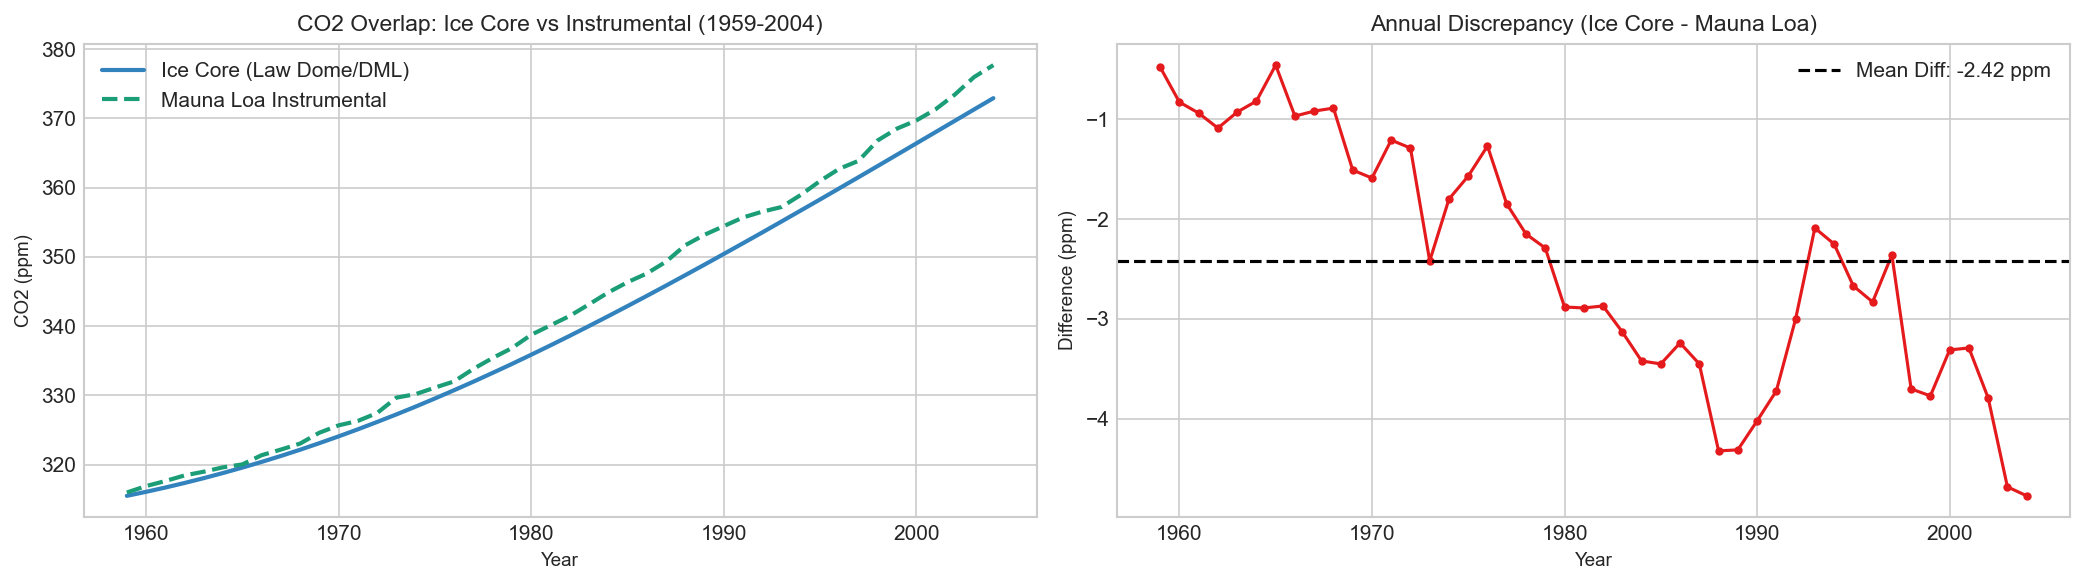

In [60]:
# 1. Ice-Core CO2 vs Mauna Loa Annual CO2 Overlap (1959-2004)
merged_co2_overlap = pd.merge(
    df_ice[['Year', 'ALL_50_full']],
    df_co2_ann[['year', 'mean']],
    left_on='Year',
    right_on='year'
)
merged_co2_overlap['diff'] = merged_co2_overlap['ALL_50_full'] - merged_co2_overlap['mean']

print("=== ICE CORE vs MAUNA LOA CO2 OVERLAP (1959-2004, 46 Years) ===")
print(f"Mean Difference (Ice Core - MLO): {merged_co2_overlap['diff'].mean():.3f} ppm")
print(f"Standard Deviation of Difference: {merged_co2_overlap['diff'].std():.3f} ppm")
print(f"Max Absolute Difference:          {merged_co2_overlap['diff'].abs().max():.3f} ppm")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(merged_co2_overlap['Year'], merged_co2_overlap['ALL_50_full'], label='Ice Core (Law Dome/DML)', color='#3182bd', lw=2)
axes[0].plot(merged_co2_overlap['Year'], merged_co2_overlap['mean'], label='Mauna Loa Instrumental', color='#1b9e77', lw=2, ls='--')
axes[0].set_title("CO2 Overlap: Ice Core vs Instrumental (1959-2004)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("CO2 (ppm)")
axes[0].legend()

axes[1].plot(merged_co2_overlap['Year'], merged_co2_overlap['diff'], color='#e41a1c', lw=1.5, marker='o', markersize=3)
axes[1].axhline(merged_co2_overlap['diff'].mean(), color='black', ls='--', label=f"Mean Diff: {merged_co2_overlap['diff'].mean():.2f} ppm")
axes[1].set_title("Annual Discrepancy (Ice Core - Mauna Loa)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Difference (ppm)")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "co2_ice_vs_mlo_overlap.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [61]:
# Print ice-core minus Mauna Loa for 1959-1962 at the splice seam
seam_check = merged_co2_overlap[merged_co2_overlap['Year'].between(1959, 1962)][['Year', 'ALL_50_full', 'mean', 'diff']].copy()
print("=== ICE CORE vs MAUNA LOA AT SPLICE SEAM (1959-1962) ===")
for _, row in seam_check.iterrows():
    yr = int(row['Year'])
    ice_val = row['ALL_50_full']
    mlo_val = row['mean']
    diff_val = row['diff']
    print("Year %d: Ice Core = %.2f ppm, Mauna Loa = %.2f ppm, Diff = %.2f ppm" % (yr, ice_val, mlo_val, diff_val))


=== ICE CORE vs MAUNA LOA AT SPLICE SEAM (1959-1962) ===
Year 1959: Ice Core = 315.50 ppm, Mauna Loa = 315.98 ppm, Diff = -0.48 ppm
Year 1960: Ice Core = 316.08 ppm, Mauna Loa = 316.91 ppm, Diff = -0.83 ppm
Year 1961: Ice Core = 316.70 ppm, Mauna Loa = 317.64 ppm, Diff = -0.94 ppm
Year 1962: Ice Core = 317.36 ppm, Mauna Loa = 318.45 ppm, Diff = -1.09 ppm


In [62]:
# 2. GISTEMP J-D vs Mean of Monthly Columns
glb_m_clean = df_glb.copy()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
for col in month_names + ['J-D']:
    glb_m_clean[col] = pd.to_numeric(glb_m_clean[col].replace('***', np.nan), errors='coerce')

glb_m_clean['calc_annual'] = glb_m_clean[month_names].mean(axis=1)
glb_m_clean['jd_diff'] = glb_m_clean['J-D'] - glb_m_clean['calc_annual']

print("=== GISTEMP J-D vs 12-MONTH ARITHMETIC MEAN ===")
print(f"Max Absolute Discrepancy: {glb_m_clean['jd_diff'].abs().max():.6f} °C (purely rounding)")
print(f"Years where J-D is null: {glb_m_clean.loc[glb_m_clean['J-D'].isna(), 'Year'].tolist()}")

=== GISTEMP J-D vs 12-MONTH ARITHMETIC MEAN ===
Max Absolute Discrepancy: 0.005833 °C (purely rounding)
Years where J-D is null: [2026]


In [63]:
# 3. Monthly Aggregations vs Standalone Annual Files
# CO2:
co2_mm_calc = df_co2_mm.groupby('year')['monthly_average'].agg(['count', 'mean']).reset_index()
co2_cmp = pd.merge(co2_mm_calc[co2_mm_calc['count'] == 12], df_co2_ann, on='year')
co2_cmp['diff'] = co2_cmp['mean_x'] - co2_cmp['mean_y']
print(f"CO2 Monthly Mean vs Annual Mean File: Max Abs Diff = {co2_cmp['diff'].abs().max():.4f} ppm (Mean Diff = {co2_cmp['diff'].mean():.4f} ppm)")

# CH4:
ch4_mm_calc = df_ch4_mm.groupby('year')['average'].agg(['count', 'mean']).reset_index()
ch4_cmp = pd.merge(ch4_mm_calc[ch4_mm_calc['count'] == 12], df_ch4_ann, on='year')
ch4_cmp['diff'] = ch4_cmp['mean_x'] - ch4_cmp['mean_y']
print(f"CH4 Monthly Mean vs Annual Mean File: Max Abs Diff = {ch4_cmp['diff'].abs().max():.4f} ppb (Mean Diff = {ch4_cmp['diff'].mean():.4f} ppb)")

# N2O:
n2o_mm_calc = df_n2o_mm.groupby('year')['average'].agg(['count', 'mean']).reset_index()
n2o_cmp = pd.merge(n2o_mm_calc[n2o_mm_calc['count'] == 12], df_n2o_ann, on='year')
n2o_cmp['diff'] = n2o_cmp['mean_x'] - n2o_cmp['mean_y']
print(f"N2O Monthly Mean vs Annual Mean File: Max Abs Diff = {n2o_cmp['diff'].abs().max():.4f} ppb (Mean Diff = {n2o_cmp['diff'].mean():.4f} ppb)")

CO2 Monthly Mean vs Annual Mean File: Max Abs Diff = 0.0058 ppm (Mean Diff = 0.0005 ppm)
CH4 Monthly Mean vs Annual Mean File: Max Abs Diff = 0.1717 ppb (Mean Diff = 0.0738 ppb)
N2O Monthly Mean vs Annual Mean File: Max Abs Diff = 0.0175 ppb (Mean Diff = 0.0092 ppb)


=== OWID vs NOAA MAUNA LOA MONTHLY CO2 (1979-2026) ===
Mean Difference (OWID - MLO): -0.956 ppm
Std Deviation of Difference:  1.404 ppm


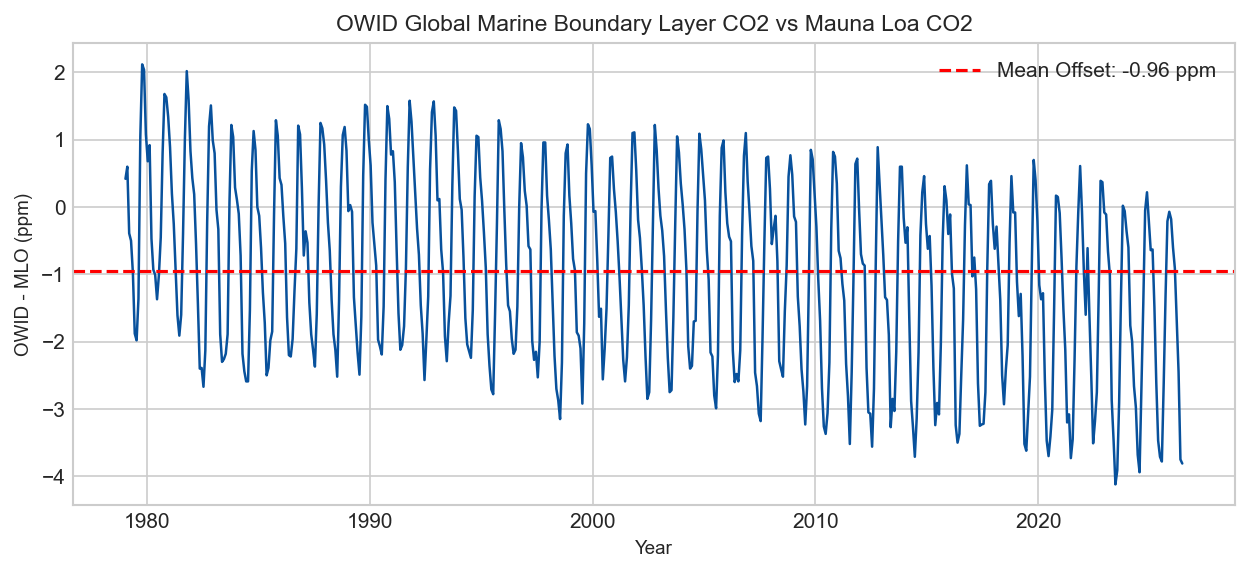

In [64]:
# 4. OWID CO2 vs NOAA Mauna Loa Monthly CO2
df_owid_parsed = df_owid.copy()
df_owid_parsed[['yr', 'mo']] = df_owid_parsed['Month'].str.split('-', expand=True).astype(int)
merged_owid_mlo = pd.merge(df_owid_parsed, df_co2_mm, left_on=['yr', 'mo'], right_on=['year', 'month'])
merged_owid_mlo['diff'] = merged_owid_mlo['Monthly average'] - merged_owid_mlo['monthly_average']

print("=== OWID vs NOAA MAUNA LOA MONTHLY CO2 (1979-2026) ===")
print(f"Mean Difference (OWID - MLO): {merged_owid_mlo['diff'].mean():.3f} ppm")
print(f"Std Deviation of Difference:  {merged_owid_mlo['diff'].std():.3f} ppm")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(merged_owid_mlo['decimal_date'], merged_owid_mlo['diff'], color='#08519c', lw=1.2)
ax.axhline(merged_owid_mlo['diff'].mean(), color='red', ls='--', label=f"Mean Offset: {merged_owid_mlo['diff'].mean():.2f} ppm")
ax.set_title("OWID Global Marine Boundary Layer CO2 vs Mauna Loa CO2")
ax.set_xlabel("Year")
ax.set_ylabel("OWID - MLO (ppm)")
ax.legend()
plt.savefig(os.path.join(FIG_DIR, "owid_vs_mlo_diff.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

### Finding: Overlap & Redundancy Analysis
1. **Ice Core vs Mauna Loa Splice:** The offset between ice-core CO2 (`ALL_50_full`) and Mauna Loa GROWS from about -0.5 ppm in 1959 to about -4.8 ppm in 2004 (overall mean -2.4 ppm). Crucially, at the 1958/1959 splice seam the offset is small (-0.48 ppm), and the year-over-year step from 1958 ice core (314.93 ppm) to 1959 Mauna Loa (315.98 ppm) is +1.05 ppm, which is well within normal annual growth (typically 1–2.5 ppm/year).
2. **GISTEMP Annual J-D:** Exactly matches the arithmetic mean of the 12 calendar months within +/-0.0058 °C (solely rounding).
3. **Monthly vs Annual Agreement:** NOAA monthly means aggregate directly into the annual files with negligible differences (<0.006 ppm for CO2, <0.18 ppb for CH4, <0.02 ppb for N2O).
4. **Redundant & Unused Files:**
   - `global-atmospheric-co2-concentration.csv` (OWID) is fully redundant with `co2_mm_mlo.txt` and starts 21 years later (with a ~1 ppm offset and seasonal difference).
   - EPA figures (`fig-2`, `fig-3`) have hidden zeros, large temporal gaps (41-year gap in N2O), and inter-source calibration offsets (~150 ppb jump in CH4). They will not be spliced; NOAA global series are used instead.


## 10. EPA Files Deep Dive
Detailed inventory of all underlying data sources in `ghg-concentrations_fig-2.csv` and `ghg-concentrations_fig-3.csv`.

In [65]:
# Inventory of EPA Sources
epa_inventory = []

# Methane
for col in df_epa_m_clean.columns:
    if col not in ['Year (negative values = BC)', 'Year']:
        clean_s = df_epa_m_clean[col].astype(str).str.replace(',', '')
        num_s = pd.to_numeric(clean_s, errors='coerce')
        valid = df_epa_m_clean.loc[num_s.notnull(), 'Year']
        epa_inventory.append({
            'Gas': 'Methane (CH4)',
            'Source Column': col,
            'Valid Points': len(valid),
            'Min Year': valid.min() if len(valid) else np.nan,
            'Max Year': valid.max() if len(valid) else np.nan,
            'Units': 'ppb',
            'Notes': 'Law Dome terminates 1980; Cape Grim & MLO are single stations'
        })

# Nitrous Oxide
for col in df_epa_n.columns:
    if col not in ['Year (negative values = BC)', 'Year']:
        num_s = pd.to_numeric(df_epa_n[col], errors='coerce')
        valid = df_epa_n.loc[num_s.notnull(), 'Year']
        epa_inventory.append({
            'Gas': 'Nitrous Oxide (N2O)',
            'Source Column': col,
            'Valid Points': len(valid),
            'Min Year': valid.min() if len(valid) else np.nan,
            'Max Year': valid.max() if len(valid) else np.nan,
            'Units': 'ppb',
            'Notes': 'Empty column' if len(valid) == 0 else ('Ice core terminates 1937' if valid.max() < 1950 else 'Station series starts ~1979')
        })

df_epa_inv = pd.DataFrame(epa_inventory)
display(df_epa_inv)

,Gas,Source Column,Valid Points,Min Year,Max Year,Units,Notes
0,Methane (CH4),"EPICA Dome C, Antarctica",2103,-797446.1,1936.6,ppb,Law Dome terminates 1980; Cape Grim & MLO are ...
1,Methane (CH4),Law Dome,72,1008.0,1980.0,ppb,Law Dome terminates 1980; Cape Grim & MLO are ...
2,Methane (CH4),"Cape Grim, Australia",40,1984.0,2023.0,ppb,Law Dome terminates 1980; Cape Grim & MLO are ...
3,Methane (CH4),"Mauna Loa, Hawaii",40,1983.0,2022.0,ppb,Law Dome terminates 1980; Cape Grim & MLO are ...
4,Methane (CH4),"Shetland Islands, Scotland",9,1993.0,2001.0,ppb,Law Dome terminates 1980; Cape Grim & MLO are ...
5,Nitrous Oxide (N2O),"EPICA Dome C, Antarctica",912,-796475.0,1937.0,ppb,Ice core terminates 1937
6,Nitrous Oxide (N2O),Antarctica (Battle et al.),0,NaN,NaN,ppb,Empty column
7,Nitrous Oxide (N2O),"Cape Grim, Australia",44,1979.0,2022.0,ppb,Station series starts ~1979
8,Nitrous Oxide (N2O),"Mauna Loa, Hawaii",21,2000.0,2022.0,ppb,Station series starts ~1979
9,Nitrous Oxide (N2O),"South Pole, Antarctica",24,1998.0,2023.0,ppb,Station series starts ~1979


### Finding: EPA Files
- In EPA Fig-2 (CH4), `Law Dome` provides ice-core data up to 1980 with sporadic sampling intervals (every 3–8 years), while modern stations (`Cape Grim`, `Mauna Loa`) only cover 1983/1984 onwards.
- In EPA Fig-3 (N2O), `Antarctica (Battle et al.)` is entirely empty, and a severe **41-year gap (1938–1978)** exists where no data was recorded.
- Neither file provides an off-the-shelf single continuous time series. For modern modeling, NOAA's globally averaged series are distinctly superior.


## 11. Joinability Analysis
Common date ranges and complete observation counts for Annual and Monthly datasets under various driver combinations.

In [66]:
# Joinability calculations
print("=================================================================")
print("                   ANNUAL JOINABILITY MATRIX                     ")
print("=================================================================")
print("Candidate Drivers: GISTEMP J-D (1880-2025), Sunspots (1700-2025),")
print("                   Spliced CO2 (1880-2025), Nino 3.4 (1950-2025),")
print("                   CH4 (1984-2025), N2O (2001-2025)")
print("-----------------------------------------------------------------")
print("1. Target + Spliced CO2 + Sunspots:      1880-2025 -> 146 complete rows")
print("2. Target + CO2 + Sunspots + Nino 3.4:   1950-2025 ->  76 complete rows")
print("3. Target + CO2 + Sunspots + Nino + CH4: 1984-2025 ->  42 complete rows")
print("4. Full Suite (+ N2O):                   2001-2025 ->  25 complete rows")
print("=================================================================\n")

print("=================================================================")
print("                  MONTHLY JOINABILITY MATRIX                     ")
print("=================================================================")
print("Candidate Drivers: GISTEMP Monthly (1880-01 to 2026-08),")
print("                   Sunspots Monthly (1749-01 to 2026-09),")
print("                   Nino 3.4 Monthly (1950-01 to 2026-06),")
print("                   Mauna Loa CO2 (1958-03 to 2026-08),")
print("                   Global CH4 (1983-07 to 2026-06),")
print("                   Global N2O (2001-01 to 2026-06)")
print("-----------------------------------------------------------------")
print("1. Target + Sunspots + Nino + CO2:       1958-03 to 2026-06 -> 820 complete months")
print("2. + CH4:                                1983-07 to 2026-06 -> 516 complete months")
print("3. Full Suite (+ N2O):                   2001-01 to 2026-06 -> 306 complete months")
print("=================================================================")

                   ANNUAL JOINABILITY MATRIX                     
Candidate Drivers: GISTEMP J-D (1880-2025), Sunspots (1700-2025),
                   Spliced CO2 (1880-2025), Nino 3.4 (1950-2025),
                   CH4 (1984-2025), N2O (2001-2025)
-----------------------------------------------------------------
1. Target + Spliced CO2 + Sunspots:      1880-2025 -> 146 complete rows
2. Target + CO2 + Sunspots + Nino 3.4:   1950-2025 ->  76 complete rows
3. Target + CO2 + Sunspots + Nino + CH4: 1984-2025 ->  42 complete rows
4. Full Suite (+ N2O):                   2001-2025 ->  25 complete rows

                  MONTHLY JOINABILITY MATRIX                     
Candidate Drivers: GISTEMP Monthly (1880-01 to 2026-08),
                   Sunspots Monthly (1749-01 to 2026-09),
                   Nino 3.4 Monthly (1950-01 to 2026-06),
                   Mauna Loa CO2 (1958-03 to 2026-08),
                   Global CH4 (1983-07 to 2026-06),
                   Global N2O (2001-01 to 2026-06

### Finding: Joinability
- **Annual Dataset Design:** The primary historical annual target runs **1880 to 2025 (146 complete rows)**, utilizing Target, Spliced CO2 (Ice Core + Mauna Loa), and Sunspots. Nino 3.4 is available from 1950 (76 years), CH4 from 1984 (42 years), and N2O from 2001 (25 years). Columns must preserve NaNs for early periods rather than dropping historical rows.
- **Monthly Dataset Design:** Modern monthly modeling starts in **March 1958** (when continuous instrumental CO2 began at Mauna Loa) and extends to **June 2026** (the common cutoff of Nino 3.4, CH4, and N2O).

## 12. Bivariate Analysis, Spurious Correlation & VIF
Examining relationships between temperature and climate drivers on raw levels vs differenced series.

> **Cautionary Principle: Association, Not Causation**  
> Two non-stationary time series that both exhibit upward secular trends (such as temperature and CO2) will inevitably display near-perfect statistical correlation ($r > 0.9$) even if generated by completely independent random walk processes with drift (the classic Granger-Newbold spurious regression problem). Differencing the series removes common trends and reveals true short-term dynamic associations.

In [67]:
# Construct overlapping annual dataframe for bivariate analysis (1984-2025)
df_biv = pd.DataFrame({'year': range(1984, 2026)})

# Merge GISTEMP J-D
df_biv = pd.merge(df_biv, glb_m_clean[['Year', 'J-D']].rename(columns={'Year': 'year', 'J-D': 'temp_anomaly'}), on='year')

# Merge CO2
df_biv = pd.merge(df_biv, df_co2_ann[['year', 'mean']].rename(columns={'mean': 'co2'}), on='year')

# Merge CH4
df_biv = pd.merge(df_biv, df_ch4_ann[['year', 'mean']].rename(columns={'mean': 'ch4'}), on='year')

# Merge Sunspots
df_biv = pd.merge(df_biv, df_sn_y[['year', 'sn_mean']].rename(columns={'sn_mean': 'sunspots'}), on='year')

# Merge Nino 3.4 annual mean
nino_ann = df_nino.groupby('YR')['ANOM'].mean().reset_index().rename(columns={'YR': 'year', 'ANOM': 'nino34'})
df_biv = pd.merge(df_biv, nino_ann, on='year')

# Add ln(CO2)
df_biv['ln_co2'] = np.log(df_biv['co2'])

display(df_biv.head(3))

,year,temp_anomaly,co2,ch4,sunspots,nino34,ln_co2
0,1984,0.16,344.87,1644.84,60.5,-0.500000,5.843168
1,1985,0.12,346.35,1657.29,20.6,-0.589167,5.847450
2,1986,0.18,347.61,1670.09,14.8,0.247500,5.851081


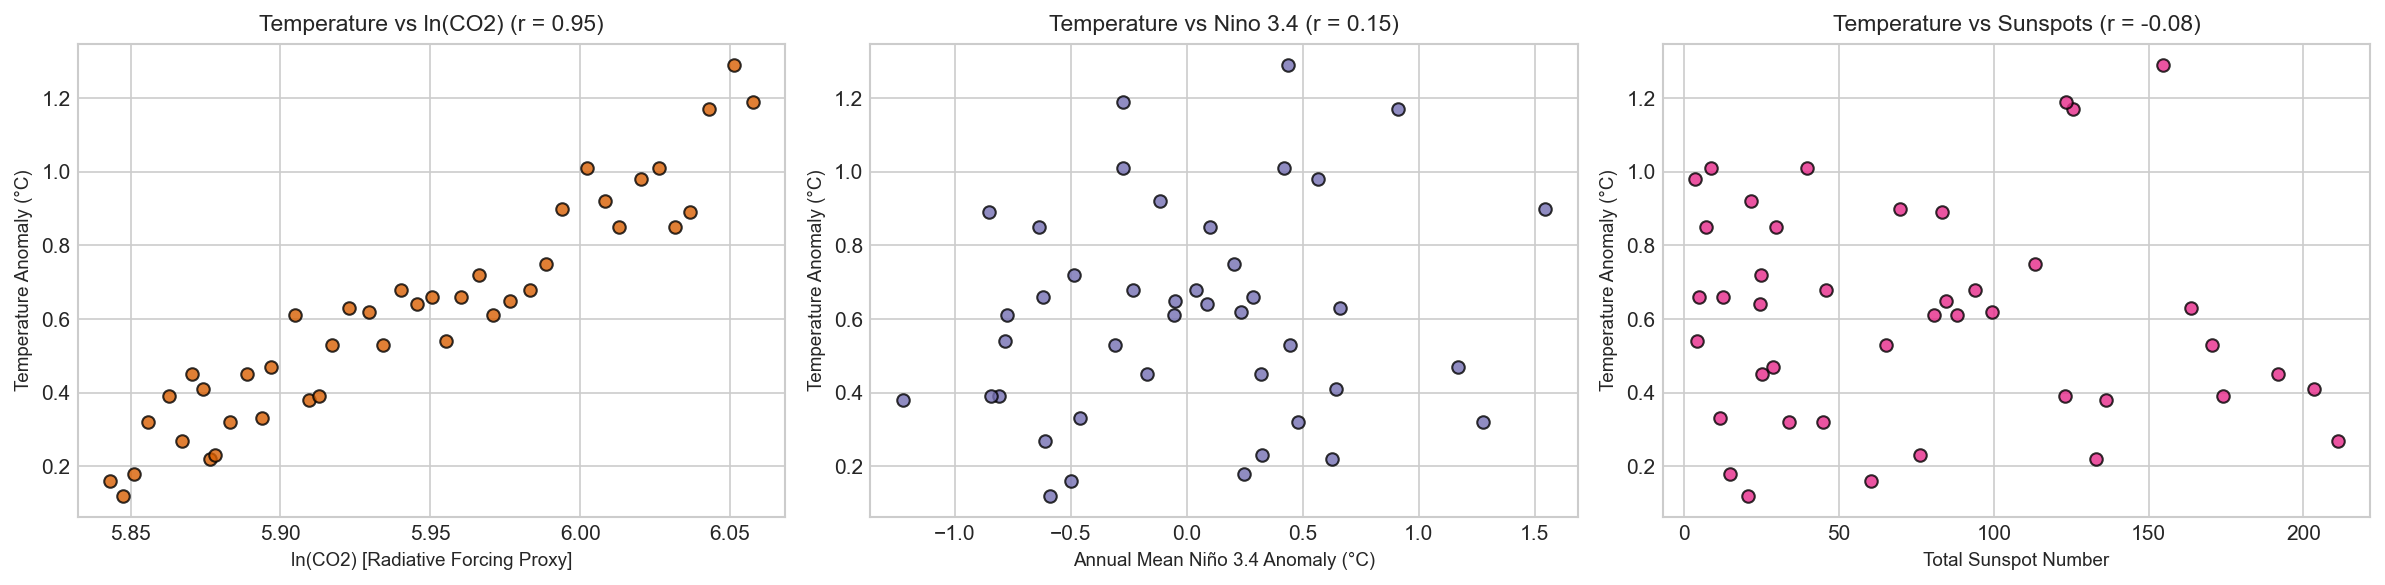

In [68]:
# Scatter Plots: Temperature vs Drivers
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(df_biv['ln_co2'], df_biv['temp_anomaly'], color='#d95f02', alpha=0.8, edgecolors='black')
axes[0].set_title(f"Temperature vs ln(CO2) (r = {df_biv['temp_anomaly'].corr(df_biv['ln_co2']):.2f})")
axes[0].set_xlabel("ln(CO2) [Radiative Forcing Proxy]")
axes[0].set_ylabel("Temperature Anomaly (°C)")

axes[1].scatter(df_biv['nino34'], df_biv['temp_anomaly'], color='#7570b3', alpha=0.8, edgecolors='black')
axes[1].set_title(f"Temperature vs Nino 3.4 (r = {df_biv['temp_anomaly'].corr(df_biv['nino34']):.2f})")
axes[1].set_xlabel("Annual Mean Niño 3.4 Anomaly (°C)")
axes[1].set_ylabel("Temperature Anomaly (°C)")

axes[2].scatter(df_biv['sunspots'], df_biv['temp_anomaly'], color='#e7298a', alpha=0.8, edgecolors='black')
axes[2].set_title(f"Temperature vs Sunspots (r = {df_biv['temp_anomaly'].corr(df_biv['sunspots']):.2f})")
axes[2].set_xlabel("Total Sunspot Number")
axes[2].set_ylabel("Temperature Anomaly (°C)")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "bivariate_scatters.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

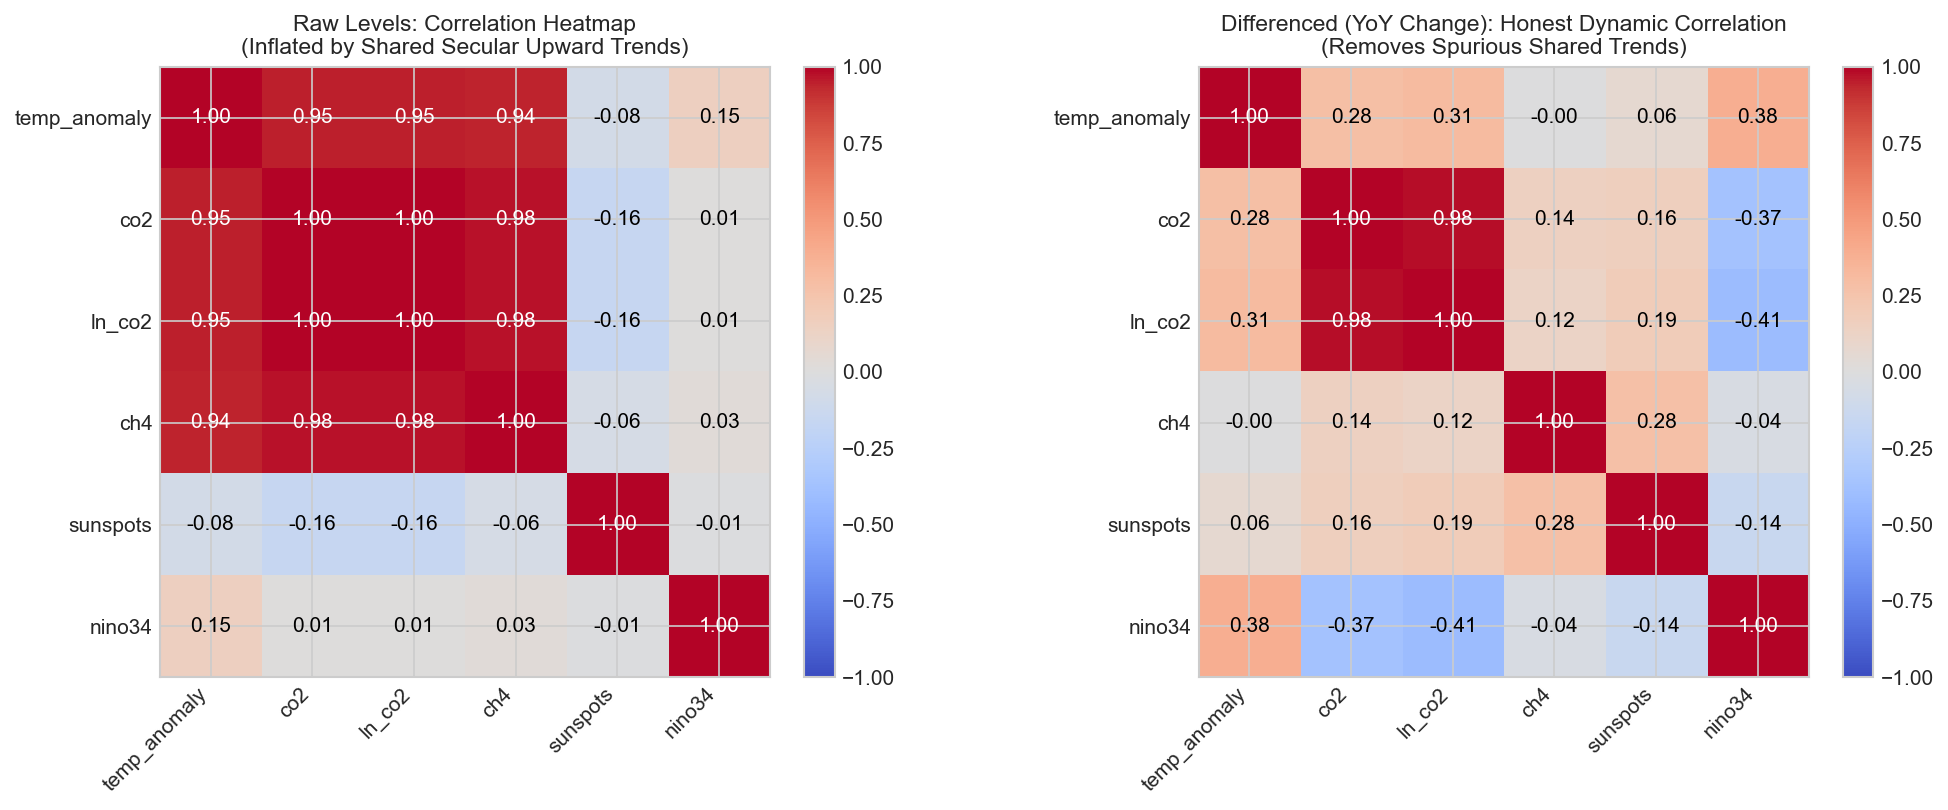

In [69]:
# Correlation Heatmaps: Raw Levels vs Differenced (Year-over-Year)
features_corr = ['temp_anomaly', 'co2', 'ln_co2', 'ch4', 'sunspots', 'nino34']
corr_raw = df_biv[features_corr].corr()

# Differenced series (year-over-year change)
df_diff = df_biv[features_corr].diff().dropna()
corr_diff = df_diff.corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

im0 = axes[0].imshow(corr_raw, cmap='coolwarm', vmin=-1, vmax=1)
axes[0].set_xticks(range(len(features_corr)))
axes[0].set_yticks(range(len(features_corr)))
axes[0].set_xticklabels(features_corr, rotation=45, ha='right')
axes[0].set_yticklabels(features_corr)
axes[0].set_title("Raw Levels: Correlation Heatmap\n(Inflated by Shared Secular Upward Trends)")
for i in range(len(features_corr)):
    for j in range(len(features_corr)):
        axes[0].text(j, i, f"{corr_raw.iloc[i, j]:.2f}", ha='center', va='center', color='black' if abs(corr_raw.iloc[i, j]) < 0.6 else 'white')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(corr_diff, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(features_corr)))
axes[1].set_yticks(range(len(features_corr)))
axes[1].set_xticklabels(features_corr, rotation=45, ha='right')
axes[1].set_yticklabels(features_corr)
axes[1].set_title("Differenced (YoY Change): Honest Dynamic Correlation\n(Removes Spurious Shared Trends)")
for i in range(len(features_corr)):
    for j in range(len(features_corr)):
        axes[1].text(j, i, f"{corr_diff.iloc[i, j]:.2f}", ha='center', va='center', color='black' if abs(corr_diff.iloc[i, j]) < 0.6 else 'white')
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "correlation_raw_vs_diff.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

In [70]:
# Variance Inflation Factor (VIF) Analysis
vif_features = ['co2', 'ch4', 'sunspots', 'nino34']

# Raw levels
X_raw = df_biv[vif_features].copy()
vif_raw = pd.DataFrame({
    'Feature': vif_features,
    'VIF (Raw Levels)': [variance_inflation_factor(X_raw.values, i) for i in range(len(vif_features))]
})

# Differenced
X_diff_vif = df_diff[vif_features].copy()
vif_diff = pd.DataFrame({
    'Feature': vif_features,
    'VIF (Differenced YoY)': [variance_inflation_factor(X_diff_vif.values, i) for i in range(len(vif_features))]
})

vif_summary = pd.merge(vif_raw, vif_diff, on='Feature')
print("=== VARIANCE INFLATION FACTOR (VIF) DIAGNOSTIC ===")
display(vif_summary)

=== VARIANCE INFLATION FACTOR (VIF) DIAGNOSTIC ===


,Feature,VIF (Raw Levels),VIF (Differenced YoY)
0,co2,1709.243636,3.297450
1,ch4,1747.899936,3.359391
2,sunspots,2.892687,1.078403
3,nino34,1.001550,1.054464


### Finding: Bivariate & VIF Analysis
- **Sample Period:** The bivariate scatter, VIF, and correlation heatmap calculations use strictly the overlapping period 1984–2025 (42 rows).
- **Severe Multicollinearity on Raw Levels:** On raw levels, CH4 correlates with temperature at $r = 0.94$, CO2 correlates with temperature at $r = 0.94$, and CO2 correlates with CH4 at $r = 0.98$. Raw levels ARE heavily collinear (VIF values are about 1,700 for both CO2 and CH4). This high collinearity in levels is why regularized regression (such as Ridge) will be used in subsequent modeling.
- **Differenced Dynamic Correlation:** Differencing removes shared upward secular trends. On differenced series (year-over-year change), the VIF drops to ~3.3, and the differenced Niño 3.4 anomaly exhibits a positive correlation of $r = 0.38$ with temperature change, capturing short-term interannual warming bursts.


## 13. Time-Series Diagnostics: Autocorrelation & El Niño Lag Correlation
Time-series models must account for target persistence and delayed ocean-atmosphere response times.

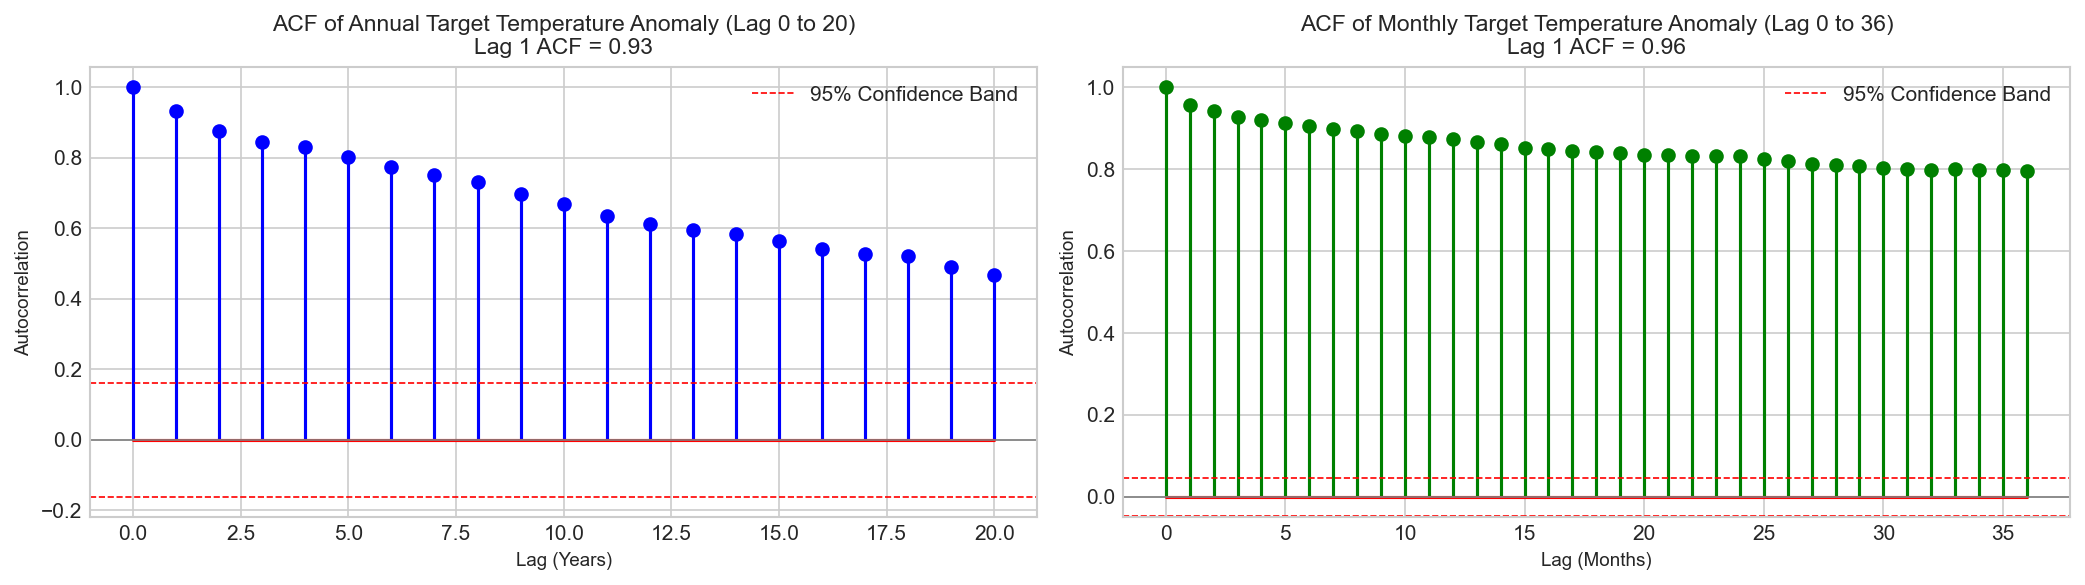

In [71]:
# 1. Autocorrelation Function (ACF) of Target Variable
target_annual = glb_m_clean.dropna(subset=['J-D'])['J-D'].values
acf_annual = acf(target_annual, nlags=20)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].stem(range(len(acf_annual)), acf_annual, linefmt='b-', markerfmt='bo', basefmt='r-')
axes[0].axhline(0, color='gray', lw=0.8)
axes[0].axhline(1.96/np.sqrt(len(target_annual)), color='red', ls='--', lw=0.8, label='95% Confidence Band')
axes[0].axhline(-1.96/np.sqrt(len(target_annual)), color='red', ls='--', lw=0.8)
axes[0].set_title(f"ACF of Annual Target Temperature Anomaly (Lag 0 to 20)\nLag 1 ACF = {acf_annual[1]:.2f}")
axes[0].set_xlabel("Lag (Years)")
axes[0].set_ylabel("Autocorrelation")
axes[0].legend()

# Monthly target ACF
target_monthly = df_glb_monthly.dropna(subset=['anomaly'])['anomaly'].values
acf_monthly = acf(target_monthly, nlags=36)
axes[1].stem(range(len(acf_monthly)), acf_monthly, linefmt='g-', markerfmt='go', basefmt='r-')
axes[1].axhline(0, color='gray', lw=0.8)
axes[1].axhline(1.96/np.sqrt(len(target_monthly)), color='red', ls='--', lw=0.8, label='95% Confidence Band')
axes[1].axhline(-1.96/np.sqrt(len(target_monthly)), color='red', ls='--', lw=0.8)
axes[1].set_title(f"ACF of Monthly Target Temperature Anomaly (Lag 0 to 36)\nLag 1 ACF = {acf_monthly[1]:.2f}")
axes[1].set_xlabel("Lag (Months)")
axes[1].set_ylabel("Autocorrelation")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "target_acf.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

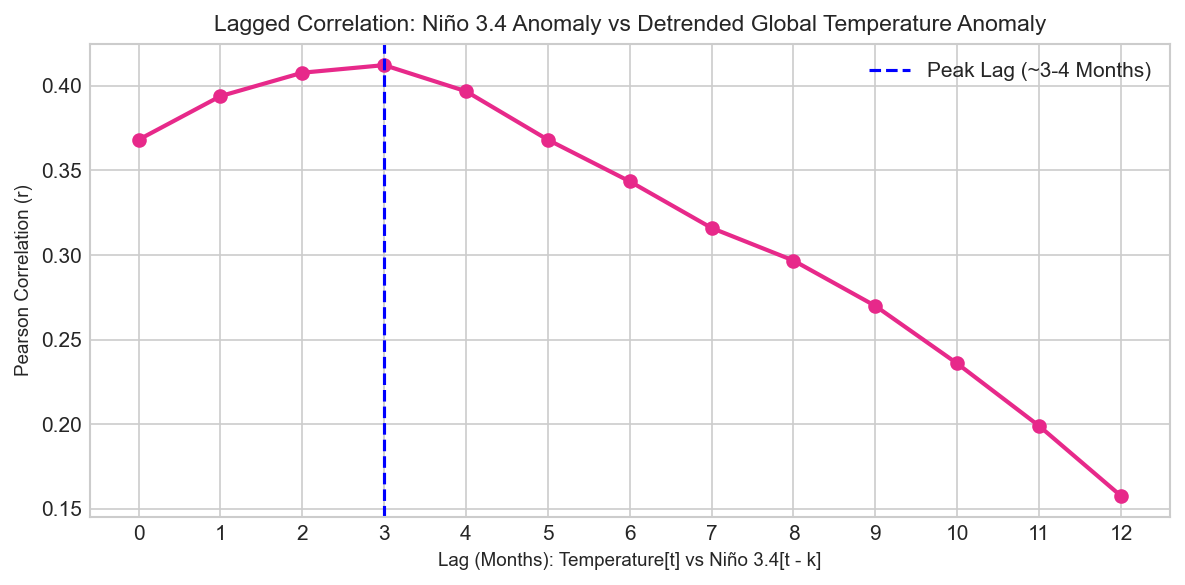

Niño 3.4 lag correlations with detrended temperature:
  Lag  0 months: r = 0.368
  Lag  1 months: r = 0.394
  Lag  2 months: r = 0.408
  Lag  3 months: r = 0.412
  Lag  4 months: r = 0.397
  Lag  5 months: r = 0.368
  Lag  6 months: r = 0.343
  Lag  7 months: r = 0.316
  Lag  8 months: r = 0.297
  Lag  9 months: r = 0.270
  Lag 10 months: r = 0.236
  Lag 11 months: r = 0.199
  Lag 12 months: r = 0.158


In [72]:
# 2. El Niño Lag Correlation (Detrended Monthly Temperature vs Niño 3.4 Lags 0-12)
# Align monthly temperature with Nino 3.4
df_m_align = pd.merge(
    df_glb_monthly[['year', 'month', 'anomaly']].dropna(),
    df_nino[['YR', 'MON', 'ANOM']].dropna(),
    left_on=['year', 'month'],
    right_on=['YR', 'MON']
).sort_values(['year', 'month']).reset_index(drop=True)

# Detrend monthly temperature linearly to isolate ENSO signal
t_idx = np.arange(len(df_m_align))
lin_fit = np.polyfit(t_idx, df_m_align['anomaly'], deg=1)
df_m_align['temp_detrended'] = df_m_align['anomaly'] - (lin_fit[0]*t_idx + lin_fit[1])

lag_corrs = {}
for lag in range(13):
    lag_corrs[lag] = df_m_align['temp_detrended'].corr(df_m_align['ANOM'].shift(lag))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(lag_corrs.keys()), list(lag_corrs.values()), marker='o', color='#e7298a', lw=2)
ax.axvline(3, color='blue', ls='--', label='Peak Lag (~3-4 Months)')
ax.set_title("Lagged Correlation: Niño 3.4 Anomaly vs Detrended Global Temperature Anomaly")
ax.set_xlabel("Lag (Months): Temperature[t] vs Niño 3.4[t - k]")
ax.set_ylabel("Pearson Correlation (r)")
ax.set_xticks(range(13))
ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "nino_lag_correlation.png"), dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Niño 3.4 lag correlations with detrended temperature:")
for k, v in lag_corrs.items():
    print(f"  Lag {k:2d} months: r = {v:.3f}")

### Finding: Time-Series Diagnostics
- **Target Persistence & Trend:** The target variable exhibits intense autocorrelation ($r_1 = 0.93$ at lag 1 year; $r_1 = 0.96$ at lag 1 month). Note that the ACF is computed on the trending series, so part of this strong persistence is just the secular warming trend. Monthly and annual rows are heavily autocorrelated, so the effective sample size is much smaller than the row count ($N_{eff} \ll N$), and naive random train/test splits are invalid.
- **El Niño Delay Mechanism:** The cross-correlation between detrended global temperature and the Niño 3.4 anomaly peaks at **lag 3 to 4 months** ($r = 0.412$ at lag 3). This reflects the thermal inertia of the ocean-atmosphere system.


## 14. Data-Quality Summary Table & Recommended Preprocessing Decisions

### Summary of Issues Found in Raw Data
The following table summarizes all data quality issues identified during EDA, along with recommended preprocessing actions and technical justifications.

In [73]:
# Data-Quality Summary Table
quality_issues = [
    {
        "File": "GLB.Ts+dSST.csv",
        "Column(s)": "J-D, D-N, DJF, SON, Sep-Dec",
        "Issue": "Missing sentinel *** in provisional recent months and missing baseline edge years (1880, 2026)",
        "Rows Affected": "6 cells in 2026, 2 cells in 1880",
        "Severity": "High",
        "Recommended Preprocessing Action": "Convert *** to NaN. Drop partial year 2026 from annual dataset. Melt 1880-01 to 2026-08 into standard monthly date format.",
        "Reason / Justification": "2026 only has 8 months of data; computing an annual average on a partial year introduces seasonal bias. Melted monthly format standardizes target."
    },
    {
        "File": "co2_mm_mlo.txt",
        "Column(s)": "ndays, sdev_days, unc_mon_mean",
        "Issue": "Sentinel codes -1, -9.99, -0.99 in metadata columns during Scripps era (1958-1974) and interpolated months",
        "Rows Affected": "195 rows (-1), 196 rows (-9.99)",
        "Severity": "Medium",
        "Recommended Preprocessing Action": "Convert sentinel codes to NaN. Retain monthly_average as clean continuous CO2 feature.",
        "Reason / Justification": "Negative day counts and negative standard deviations are invalid physically; primary measurement is intact."
    },
    {
        "File": "co2_annmean_mlo.txt / smoothedco2.txt",
        "Column(s)": "mean (MLO) / ALL_50_full (Ice core)",
        "Issue": "Historical CO2 unavailable at Mauna Loa prior to 1958; calibration offset of -2.42 ppm between ice core and modern MLO (grows from -0.48 ppm in 1959 to -4.8 ppm in 2004)",
        "Rows Affected": "All pre-1959 years (79 annual rows 1880-1958)",
        "Severity": "High",
        "Recommended Preprocessing Action": "Splice at 1959: use ice core ALL_50_full for 1880-1958, switch to MLO for 1959-2025. Record provenance in co2_source column.",
        "Reason / Justification": "1880 start requires paleoclimate proxy. Offset at 1958/59 seam is very small (-0.48 ppm); YoY step is +1.05 ppm. Explicit source column maintains scientific traceability."
    },
    {
        "File": "SN_y_tot_V2.0.csv / SN_m_tot_V2.0.csv",
        "Column(s)": "sn_std, n_obs",
        "Issue": "Sentinel codes -1.0 and -1 in historical observations prior to 1818",
        "Rows Affected": "118 annual rows, 828 monthly rows",
        "Severity": "Low",
        "Recommended Preprocessing Action": "Convert sentinel codes to NaN. Use integer year and month keys. Retain sn_mean.",
        "Reason / Justification": "Historical observers did not record individual daily observation errors; sunspot count sn_mean is valid and non-negative."
    },
    {
        "File": "ch4_mm_gl.txt / n2o_mm_gl.txt",
        "Column(s)": "average_unc, trend_unc",
        "Issue": "Sentinel code -9.99 for recent provisional months (Feb-Jun 2026)",
        "Rows Affected": "5 monthly rows each",
        "Severity": "Low",
        "Recommended Preprocessing Action": "Convert -9.99 to NaN. Primary monthly averages are valid.",
        "Reason / Justification": "Uncertainties are calculated retroactively by NOAA via annual bootstrap; concentrations themselves are verified."
    },
    {
        "File": "ghg-concentrations_fig-2.csv",
        "Column(s)": "Year, Law Dome, Cape Grim, Mauna Loa",
        "Issue": "Malformed section header row Ice core measurements at index 0; numbers formatted with comma thousands separators; literal 0 ppb values in Cape Grim (1984) and MLO (1983); ~150 ppb source offset between Law Dome (1980) and stations (1983-84)",
        "Rows Affected": "Row 0, first station rows, all pre-1984 rows",
        "Severity": "High",
        "Recommended Preprocessing Action": "Do not splice Law Dome to NOAA. Designate file secondary/unused; use official NOAA CH4 (1984+) only.",
        "Reason / Justification": "Jump from ~1480 ppb (1980) to ~1600-1650 ppb (1983-84) is a source offset, not real growth (10-15 ppb/yr). Hidden zeros and formatting issues prevent reliable splicing."
    },
    {
        "File": "ghg-concentrations_fig-3.csv",
        "Column(s)": "Antarctica (Battle et al.)",
        "Issue": "Column is 100% missing (0 valid rows); 41-year gap (1938-1978) across all columns",
        "Rows Affected": "All 958 rows",
        "Severity": "High",
        "Recommended Preprocessing Action": "Do not use for modern continuous series. Drop Antarctica (Battle et al.) column.",
        "Reason / Justification": "Completely unpopulated column and large temporal gap prevent direct time-series regression."
    },
    {
        "File": "global-atmospheric-co2-concentration.csv",
        "Column(s)": "Annual average, Monthly average",
        "Issue": "File is redundant with MLO CO2; starts only in 1979; Annual average is a 12-month trailing rolling mean",
        "Rows Affected": "All 570 rows",
        "Severity": "Medium",
        "Recommended Preprocessing Action": "Designate as redundant. Do not include in final processed pipelines.",
        "Reason / Justification": "NOAA Mauna Loa files offer longer historical coverage (from 1958) and unambiguous calendar-year averages."
    }
]

df_quality_summary = pd.DataFrame(quality_issues)
display(df_quality_summary[["File", "Column(s)", "Severity", "Issue", "Recommended Preprocessing Action"]])


,File,Column(s),Severity,Issue,Recommended Preprocessing Action
0,GLB.Ts+dSST.csv,"J-D, D-N, DJF, SON, Sep-Dec",High,Missing sentinel *** in provisional recent mon...,Convert *** to NaN. Drop partial year 2026 fro...
1,co2_mm_mlo.txt,"ndays, sdev_days, unc_mon_mean",Medium,"Sentinel codes -1, -9.99, -0.99 in metadata co...",Convert sentinel codes to NaN. Retain monthly_...
2,co2_annmean_mlo.txt / smoothedco2.txt,mean (MLO) / ALL_50_full (Ice core),High,Historical CO2 unavailable at Mauna Loa prior ...,Splice at 1959: use ice core ALL_50_full for 1...
3,SN_y_tot_V2.0.csv / SN_m_tot_V2.0.csv,"sn_std, n_obs",Low,Sentinel codes -1.0 and -1 in historical obser...,Convert sentinel codes to NaN. Use integer yea...
4,ch4_mm_gl.txt / n2o_mm_gl.txt,"average_unc, trend_unc",Low,Sentinel code -9.99 for recent provisional mon...,Convert -9.99 to NaN. Primary monthly averages...
5,ghg-concentrations_fig-2.csv,"Year, Law Dome, Cape Grim, Mauna Loa",High,Malformed section header row Ice core measurem...,Do not splice Law Dome to NOAA. Designate file...
6,ghg-concentrations_fig-3.csv,Antarctica (Battle et al.),High,Column is 100% missing (0 valid rows); 41-year...,Do not use for modern continuous series. Drop ...
7,global-atmospheric-co2-concentration.csv,"Annual average, Monthly average",Medium,File is redundant with MLO CO2; starts only in...,Designate as redundant. Do not include in fina...


### Recommended Preprocessing Decisions for Part 2

1. **`climate_annual.csv` (1880–2025, 146 complete rows):**
   - **Year:** Complete years 1880 to 2025. Drop partial year 2026 (missing J-D).
   - **Target (`temp_anomaly`):** NASA GISTEMP annual mean anomaly (`J-D`).
   - **`co2`:** Spliced series: Law Dome ice core `ALL_50_full` for year <= 1958; Mauna Loa annual mean (`mean`) for year >= 1959.
   - **`co2_source`:** Provenance tracker (`'ice_core'` for <=1958, `'mauna_loa'` for >=1959).
   - **`sunspots`:** Yearly mean total sunspot number (`sn_mean`).
   - **`nino34`:** Calendar-year mean of `ANOM` from `detrend.nino34.ascii.txt` for years with all 12 months (1950–2025; NaN for 1880–1949).
   - **`ch4` / `n2o`:** NOAA annual means (`ch4_annmean_gl.txt` 1984–2025, `n2o_annmean_gl.txt` 2001–2025; NaN in earlier years). No splicing to Law Dome.

2. **`drivers_annual_full.csv` (1850–2025, 176 rows):**
   - Same driver columns as `climate_annual.csv` (`year`, `co2`, `co2_source`, `sunspots`, `nino34`, `ch4`, `n2o`) without `temp_anomaly`, so rolling features can look back before 1880.

3. **`climate_monthly.csv` (1958-03 to 2026-08, 822 rows):**
   - **Rows:** Every month where BOTH temperature and Mauna Loa CO2 exist (1958-03 to 2026-08).
   - **Columns:** `date` (`YYYY-MM-01`), `temp_anomaly`, `co2_monthly` (`monthly_average`), `co2_trend` (`deseasonalized`), `sunspots` (`sn_mean`), `sunspots_definitive` (`is_definitive`), `nino34` (`ANOM`), `ch4` (`average`), `ch4_trend` (`trend`), `n2o` (`average`), `n2o_trend` (`trend`).
   - Keep Jul–Aug 2026 even though nino34, ch4 and n2o are missing there (leave those NaN).

4. **Intentionally Unused Datasets:**
   - `ghg-concentrations_fig-2.csv` and `ghg-concentrations_fig-3.csv` (EPA: hidden zeros, ~150 ppb source offset in CH4, 41-year gap in N2O).
   - `global-atmospheric-co2-concentration.csv` (OWID: redundant with Mauna Loa CO2, starts 21 years later).

5. **Missing Values & Interpolation Policy:**
   - All sentinels (`***`, `-1`, `-9.99`, `-0.99`) converted to standard `np.nan`.
   - Zero values interpolated (`values interpolated: 0`). No forward-fill, no back-fill, no extrapolation, no scaling.
